In [4]:
# ======================================================================
# AURORA
# CREATE PATIENT-LEVEL CLOSEST GRIFFIN DRAW TO METASTATIC ER ASSESSMENT
#
# Goal:
#   For each patient:
#
#   1. Identify FIRST informative metastatic ER assessment
#      ER = Positive or Negative
#
#   2. Identify all available Griffin blood draws
#
#   3. Calculate:
#
#        signed_lag = blood_draw_day - ER_assessment_day
#
#   4. Select the Griffin draw with minimum absolute lag
#
#   5. If two draws are exactly equally close:
#        - prefer draw BEFORE/on the ER assessment
#        - then prefer lower NB number
#
# Output:
#   ClosestDraw_MetER_patient_audit.tsv
#
# Expected cohort with current AURORA data:
#   262 total Griffin patients
#   244 informative metastatic ER
#       183 ER+
#        61 ER-
#   18 metastatic ER unknown
#
# ======================================================================


# ======================================================================
# 0. IMPORTS
# ======================================================================

from pathlib import Path

import re
import numpy as np
import pandas as pd


# ======================================================================
# 1. PATHS
# ======================================================================
#
# Check the filenames below and modify ONLY if your server filenames differ.
# ======================================================================


CLINICAL_XLSX = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/AUP_ClinicalData_20260609.xlsx"
)


METASHEET_XLSX = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/Metasheet_Analysis.with_Histology_Receptor_status.Earliest_Met_Diagnosis.xlsx/"
)


GRIFFIN_XLSX = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/griffin_nucleosome_profiling/"
    "Griffin_44TF_GC_corrected_summary_by_module.xlsx"
)


OUT_DIR = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "Griffin/Downstream/"
    "AURORA_Griffin_Met_ER_Closest_Draw_TFBS"
)


OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


OUT_TSV = (
    OUT_DIR /
    "ClosestDraw_MetER_patient_audit.tsv"
)


print("Output directory:")
print(OUT_DIR)


# ======================================================================
# 2. HELPER FUNCTIONS
# ======================================================================


def normalize_patient_id(x):
    """
    Convert patient IDs consistently to strings.

    Examples:
        2       -> '2'
        2.0     -> '2'
        '592-21' -> '592-21'
    """

    if pd.isna(x):
        return np.nan

    if isinstance(x, float) and x.is_integer():
        return str(int(x))

    return str(x).strip()



def normalize_sample_id(x):
    """
    Normalize sample names.

    Clinical/metasheet may contain:
        AUP-AL1Y-NB1

    Griffin may contain:
        AL1Y-NB1

    Output:
        AL1Y-NB1
    """

    if pd.isna(x):
        return np.nan

    x = str(x).strip()

    if x.startswith("AUP-"):
        x = x[4:]

    return x



def normalize_er(x):
    """
    Standardize ER labels.
    """

    if pd.isna(x):
        return np.nan

    x = str(x).strip().lower()

    if x in [
        "positive",
        "pos",
        "er+",
        "+"
    ]:
        return "Positive"

    if x in [
        "negative",
        "neg",
        "er-",
        "-"
    ]:
        return "Negative"

    return np.nan



def get_nb_number(sample):
    """
    Extract NB number.

    AL1Y-NB1 -> 1
    AL1Y-NB4 -> 4
    """

    if pd.isna(sample):
        return 999

    match = re.search(
        r"-NB(\d+)$",
        str(sample)
    )

    if match:
        return int(match.group(1))

    return 999


# ======================================================================
# 3. LOAD CLINICAL DATA
# ======================================================================


clinical = pd.read_excel(
    CLINICAL_XLSX,
    sheet_name=0
)


print("\n==========================================")
print("CLINICAL DATA")
print("==========================================")

print(
    "Rows:",
    len(clinical)
)


required_clinical_cols = [

    "patient_id",
    "Category",
    "Days_From_Primary_Diagnosis",
    "Barcode",
    "Tissue_Site",
    "ER_Status"
]


missing = [

    x for x in required_clinical_cols

    if x not in clinical.columns
]


if missing:

    raise ValueError(
        f"Clinical file missing columns:\n{missing}"
    )


clinical["patient_id_norm"] = (

    clinical["patient_id"]
    .map(normalize_patient_id)
)


clinical["sample_norm"] = (

    clinical["Barcode"]
    .map(normalize_sample_id)
)


clinical["ER_norm"] = (

    clinical["ER_Status"]
    .map(normalize_er)
)


clinical["day"] = pd.to_numeric(

    clinical[
        "Days_From_Primary_Diagnosis"
    ],

    errors="coerce"
)


# ======================================================================
# 4. LOAD METASHEET
# ======================================================================


meta = pd.read_excel(
    METASHEET_XLSX
)


print("\n==========================================")
print("METASHEET")
print("==========================================")

print(
    "Rows:",
    len(meta)
)


required_meta_cols = [

    "Collaborator_sample_id",
    "Patient_id",
    "Tumor_Fraction"
]


missing = [

    x for x in required_meta_cols

    if x not in meta.columns
]


if missing:

    raise ValueError(
        f"Metasheet missing columns:\n{missing}"
    )


meta["sample_norm"] = (

    meta[
        "Collaborator_sample_id"
    ]
    .map(normalize_sample_id)
)


meta["patient_id_norm"] = (

    meta[
        "Patient_id"
    ]
    .map(normalize_patient_id)
)


# Convert tumor fraction from fraction to percent

meta["TFx_pct"] = (

    pd.to_numeric(
        meta["Tumor_Fraction"],
        errors="coerce"
    )
    *
    100
)


# ======================================================================
# 5. LOAD GRIFFIN SAMPLE LIST
# ======================================================================
#
# We only need the sample names here.
# This guarantees that the selected blood draw actually has Griffin data.
#
# ======================================================================


griffin = pd.read_excel(

    GRIFFIN_XLSX,

    sheet_name="Breast_Lineage",

    header=[
        0,
        1
    ]
)


# Find first/sample column

griffin_sample_col = (
    griffin.columns[0]
)


griffin_samples = (

    griffin[
        griffin_sample_col
    ]
    .dropna()
    .map(normalize_sample_id)
    .drop_duplicates()
)


griffin_sample_set = set(
    griffin_samples
)


print("\n==========================================")
print("GRIFFIN")
print("==========================================")

print(
    "Unique Griffin samples:",
    len(griffin_sample_set)
)


# ======================================================================
# 6. IDENTIFY ALL CLINICAL BLOOD DRAWS
# ======================================================================


blood = clinical.loc[

    (
        clinical["Category"]
        ==
        "Blood_Draw"
    )

    &

    clinical["sample_norm"].notna()

    &

    clinical["day"].notna(),

    [
        "patient_id_norm",
        "sample_norm",
        "day"
    ]

].copy()


blood = blood.rename(

    columns={
        "day":
            "draw_day"
    }
)


# ======================================================================
# 7. MERGE BLOOD DRAWS WITH METASHEET
# ======================================================================


blood = blood.merge(

    meta[
        [
            "patient_id_norm",
            "sample_norm",
            "TFx_pct"
        ]
    ],

    on=[
        "patient_id_norm",
        "sample_norm"
    ],

    how="inner"
)


# ======================================================================
# 8. RETAIN ONLY BLOOD DRAWS WITH GRIFFIN DATA
# ======================================================================


blood = blood.loc[

    blood[
        "sample_norm"
    ]
    .isin(
        griffin_sample_set
    )

].copy()


print("\n==========================================")
print("BLOOD DRAW QC")
print("==========================================")

print(
    "Blood draws with clinical + metasheet + Griffin:",
    len(blood)
)


print(
    "Unique patients with Griffin blood draws:",
    blood[
        "patient_id_norm"
    ].nunique()
)


# Expected approximately:
#
# 769 blood draws
# 262 patients


# ======================================================================
# 9. IDENTIFY INFORMATIVE METASTATIC ER ASSESSMENTS
# ======================================================================
#
# Definition:
#
# Category == Met_Diagnosis
#
# AND
#
# ER_Status = Positive or Negative
#
# ======================================================================


met_er = clinical.loc[

    (
        clinical["Category"]
        ==
        "Met_Diagnosis"
    )

    &

    clinical["ER_norm"].isin(
        [
            "Positive",
            "Negative"
        ]
    )

    &

    clinical["day"].notna()

].copy()


print("\n==========================================")
print("METASTATIC ER ASSESSMENTS")
print("==========================================")

print(
    "Informative metastatic ER rows:",
    len(met_er)
)


print(
    "Patients with ≥1 informative metastatic ER:",
    met_er[
        "patient_id_norm"
    ].nunique()
)


# ======================================================================
# 10. FIRST INFORMATIVE METASTATIC ER PER PATIENT
# ======================================================================
#
# IMPORTANT:
#
# We choose the earliest date at which metastatic ER is informative.
#
# If multiple metastatic sites are recorded on that same day,
# they are combined.
#
# If contradictory ER statuses occur on the same earliest date,
# patient is flagged as ambiguous and excluded.
#
# ======================================================================


anchor_records = []

ambiguous_records = []


for patient_id, group in met_er.groupby(
    "patient_id_norm"
):


    first_day = (

        group["day"]
        .min()
    )


    first_rows = group.loc[

        group["day"]
        ==
        first_day

    ].copy()


    statuses = (

        first_rows["ER_norm"]
        .dropna()
        .unique()
        .tolist()
    )


    statuses = sorted(
        statuses
    )


    # ------------------------------------
    # Contradictory ER on same first day
    # ------------------------------------

    if len(statuses) != 1:


        ambiguous_records.append(

            {
                "patient_id":
                    patient_id,

                "ER_assessment_day":
                    first_day,

                "ER_statuses":
                    ";".join(
                        statuses
                    )
            }
        )


        continue


    met_status = statuses[0]


    sites = (

        first_rows[
            "Tissue_Site"
        ]
        .dropna()
        .astype(str)
        .unique()
        .tolist()
    )


    sites = sorted(
        sites
    )


    anchor_records.append(

        {
            "patient_id_norm":
                patient_id,

            "met_ER":
                met_status,

            "ER_assessment_day":
                first_day,

            "ER_assessment_sites":
                ", ".join(
                    sites
                )
        }
    )


anchors = pd.DataFrame(
    anchor_records
)


ambiguous = pd.DataFrame(
    ambiguous_records
)


print(
    "\nPatients with usable first metastatic ER:",
    len(anchors)
)


print(
    "\nMetastatic ER:"
)

print(
    anchors[
        "met_ER"
    ]
    .value_counts()
)


print(
    "\nAmbiguous first ER assessment:",
    len(ambiguous)
)


# ======================================================================
# 11. MERGE EVERY BLOOD DRAW WITH PATIENT ER ANCHOR
# ======================================================================


pairs = blood.merge(

    anchors,

    on="patient_id_norm",

    how="inner"
)


# ======================================================================
# 12. CALCULATE BLOOD–ER LAG
# ======================================================================
#
# signed_lag:
#
#   negative -> blood BEFORE ER assessment
#
#   zero     -> same day
#
#   positive -> blood AFTER ER assessment
#
# ======================================================================


pairs["signed_lag_days"] = (

    pairs["draw_day"]
    -
    pairs["ER_assessment_day"]
)


pairs["abs_lag_days"] = (

    pairs["signed_lag_days"]
    .abs()
)


pairs["NB_number"] = (

    pairs[
        "sample_norm"
    ]
    .map(
        get_nb_number
    )
)


# ======================================================================
# 13. DRAW RELATIVE TO ER ASSESSMENT
# ======================================================================


pairs[
    "draw_relative_to_ER"
] = np.select(

    [

        pairs[
            "signed_lag_days"
        ] < 0,

        pairs[
            "signed_lag_days"
        ] == 0

    ],

    [

        "Before",
        "Same day"

    ],

    default="After"
)


# ======================================================================
# 14. TIE-BREAKING VARIABLE
# ======================================================================
#
# If exactly equal |lag|:
#
# preference:
#
#   before/same day = 0
#   after           = 1
#
# Therefore before is selected first.
#
# ======================================================================


pairs[
    "after_preference"
] = (

    pairs[
        "signed_lag_days"
    ] > 0

).astype(int)


# ======================================================================
# 15. NUMBER OF AVAILABLE GRIFFIN DRAWS PER PATIENT
# ======================================================================


n_draws = (

    pairs
    .groupby(
        "patient_id_norm"
    )
    .size()
    .rename(
        "n_Griffin_draws"
    )
)


# ======================================================================
# 16. CREATE STRING OF ALL AVAILABLE CANDIDATE DRAWS
# ======================================================================


candidate_strings = {}


for patient_id, group in pairs.groupby(
    "patient_id_norm"
):


    group = group.sort_values(
        "draw_day"
    )


    candidate_strings[
        patient_id
    ] = ";".join(

        [

            (
                f"{row.sample_norm}"
                f":lag={row.signed_lag_days:.0f}"
            )

            for row in group.itertuples()

        ]
    )


# ======================================================================
# 17. COUNT EXACT ABSOLUTE-LAG TIES
# ======================================================================


tie_counts = {}


for patient_id, group in pairs.groupby(
    "patient_id_norm"
):


    minimum_lag = (

        group[
            "abs_lag_days"
        ]
        .min()
    )


    tie_counts[
        patient_id
    ] = int(

        (
            group[
                "abs_lag_days"
            ]
            ==
            minimum_lag
        )
        .sum()
    )


# ======================================================================
# 18. SELECT CLOSEST DRAW
# ======================================================================
#
# Sort hierarchy:
#
# 1. patient
# 2. minimum absolute lag
# 3. prefer before/same-day
# 4. smaller NB number
#
# ======================================================================


pairs = pairs.sort_values(

    [

        "patient_id_norm",
        "abs_lag_days",
        "after_preference",
        "NB_number"

    ]
)


selected = (

    pairs
    .groupby(
        "patient_id_norm",
        as_index=False
    )
    .first()
)


# ======================================================================
# 19. ADD QC INFORMATION
# ======================================================================


selected[
    "n_Griffin_draws"
] = (

    selected[
        "patient_id_norm"
    ]
    .map(
        n_draws
    )
)


selected[
    "closest_abs_lag_tie_count"
] = (

    selected[
        "patient_id_norm"
    ]
    .map(
        tie_counts
    )
)


selected[
    "all_candidate_samples"
] = (

    selected[
        "patient_id_norm"
    ]
    .map(
        candidate_strings
    )
)


# ======================================================================
# 20. ADD TIMING WINDOW FLAGS
# ======================================================================


for days in [

    30,
    60,
    90,
    180,
    365

]:

    selected[
        f"within_{days}d"
    ] = (

        selected[
            "abs_lag_days"
        ]
        <=
        days
    )


# ======================================================================
# 21. CLEAN FINAL COLUMN NAMES
# ======================================================================


selected = selected.rename(

    columns={

        "patient_id_norm":
            "patient_id",

        "sample_norm":
            "selected_sample",

        "NB_number":
            "selected_NB"
    }
)


# ======================================================================
# 22. FINAL AUDIT COLUMN ORDER
# ======================================================================


final_columns = [

    "patient_id",

    "met_ER",

    "ER_assessment_day",

    "ER_assessment_sites",

    "selected_sample",

    "selected_NB",

    "draw_day",

    "signed_lag_days",

    "abs_lag_days",

    "draw_relative_to_ER",

    "TFx_pct",

    "within_30d",

    "within_60d",

    "within_90d",

    "within_180d",

    "within_365d",

    "n_Griffin_draws",

    "closest_abs_lag_tie_count",

    "all_candidate_samples"
]


audit_final = selected[
    final_columns
].copy()


# ======================================================================
# 23. SORT FOR EASY QC
# ======================================================================


audit_final = audit_final.sort_values(

    [

        "met_ER",
        "abs_lag_days",
        "patient_id"

    ]
).reset_index(
    drop=True
)


# ======================================================================
# 24. SAVE MAIN AUDIT
# ======================================================================


audit_final.to_csv(

    OUT_TSV,

    sep="\t",

    index=False
)


print("\n==========================================")
print("SAVED MAIN AUDIT")
print("==========================================")

print(
    OUT_TSV
)


# ======================================================================
# 25. COHORT QC SUMMARY
# ======================================================================


print("\n==========================================")
print("FINAL COHORT QC")
print("==========================================")


print(
    "Patients in audit:",
    len(audit_final)
)


print(
    "\nMetastatic ER distribution:"
)

print(
    audit_final[
        "met_ER"
    ]
    .value_counts()
)


print(
    "\nSelected NB distribution:"
)

print(

    audit_final[
        "selected_NB"
    ]
    .value_counts()
    .sort_index()
)


print(
    "\nDraw relative to ER assessment:"
)

print(

    audit_final[
        "draw_relative_to_ER"
    ]
    .value_counts()
)


print(
    "\nAbsolute lag summary:"
)

print(

    audit_final[
        "abs_lag_days"
    ]
    .describe()
)


# ======================================================================
# 26. TIMING WINDOW QC
# ======================================================================


window_summary = []


for days in [

    30,
    60,
    90,
    180,
    365

]:


    temp = audit_final.loc[

        audit_final[
            "abs_lag_days"
        ]
        <=
        days

    ]


    n_positive = (

        temp[
            "met_ER"
        ]
        .eq(
            "Positive"
        )
        .sum()
    )


    n_negative = (

        temp[
            "met_ER"
        ]
        .eq(
            "Negative"
        )
        .sum()
    )


    window_summary.append(

        {

            "Window":
                f"±{days} d",

            "n":
                len(temp),

            "ER_positive":
                n_positive,

            "ER_negative":
                n_negative
        }
    )


window_summary = pd.DataFrame(
    window_summary
)


print("\n==========================================")
print("WINDOW SUMMARY")
print("==========================================")


print(
    window_summary
    .to_string(
        index=False
    )
)


# ======================================================================
# 27. SAVE WINDOW QC
# ======================================================================


window_summary.to_csv(

    OUT_DIR /
    "ClosestDraw_MetER_window_QC.tsv",

    sep="\t",

    index=False
)


# ======================================================================
# 28. SAVE PATIENTS WITHOUT INFORMATIVE METASTATIC ER
# ======================================================================


griffin_patients = set(

    blood[
        "patient_id_norm"
    ]
)


informative_patients = set(

    anchors[
        "patient_id_norm"
    ]
)


unknown_er_patients = sorted(

    griffin_patients
    -
    informative_patients
)


pd.DataFrame(

    {
        "patient_id":
            unknown_er_patients
    }

).to_csv(

    OUT_DIR /
    "Patients_without_informative_metastatic_ER.tsv",

    sep="\t",

    index=False
)


# ======================================================================
# 29. SAVE AMBIGUOUS ER CASES IF PRESENT
# ======================================================================


if len(ambiguous) > 0:

    ambiguous.to_csv(

        OUT_DIR /
        "Patients_ambiguous_first_metastatic_ER.tsv",

        sep="\t",

        index=False
    )

print("\nDONE.")

Output directory:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Met_ER_Closest_Draw_TFBS

CLINICAL DATA
Rows: 6728

METASHEET
Rows: 769

GRIFFIN
Unique Griffin samples: 769

BLOOD DRAW QC
Blood draws with clinical + metasheet + Griffin: 769
Unique patients with Griffin blood draws: 262

METASTATIC ER ASSESSMENTS
Informative metastatic ER rows: 386
Patients with ≥1 informative metastatic ER: 254

Patients with usable first metastatic ER: 254

Metastatic ER:
Positive    188
Negative     66
Name: met_ER, dtype: int64

Ambiguous first ER assessment: 0

SAVED MAIN AUDIT
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Met_ER_Closest_Draw_TFBS/ClosestDraw_MetER_patient_audit.tsv

FINAL COHORT QC
Patients in audit: 244

Metastatic ER distribution:
Positive    183
Negative     61
Name: met_ER, dtype: int64

Selected NB distribution:
1    235
2      7
3      1
4      1
Name: selected_NB, dtype: int64

Draw relative t

In [7]:
print("\n==========================================")
print("UNIQUE PATIENT COUNTS")
print("==========================================")

print(
    "Unique patients in clinical database:",
    clinical["patient_id_norm"].nunique()
)

print(
    "Unique patients with informative metastatic ER:",
    anchors["patient_id_norm"].nunique()
)

print(
    "Unique patients with ULP-WGS data:",
    blood["patient_id_norm"].nunique()
)

print(
    "Patients with ULP-WGS and informative metastatic ER:",
    audit_final["patient_id"].nunique()
)

# ============================================================
# PRINT CLINICAL ER-INFORMATIVE PATIENTS NOT IN GRIFFIN 262
# ============================================================

# Patients with informative metastatic ER in clinical database
clinical_metER_patients = set(
    anchors["patient_id_norm"].dropna()
)

# All 262 patients with  ULP-WGS (Griffin data)
griffin_patients = set(
    blood["patient_id_norm"].dropna()
)

# Informative metastatic ER but NOT among Griffin patients
additional_clinical_cases = sorted(
    clinical_metER_patients - griffin_patients
)

print("\n==========================================")
print("INFORMATIVE MET ER PATIENTS NOT IN GRIFFIN")
print("==========================================")

print("Number of patients:", len(additional_clinical_cases))

for patient_id in additional_clinical_cases:
    print(patient_id)


UNIQUE PATIENT COUNTS
Unique patients in clinical database: 274
Unique patients with informative metastatic ER: 254
Unique patients with ULP-WGS data: 262
Patients with ULP-WGS and informative metastatic ER: 244

INFORMATIVE MET ER PATIENTS NOT IN GRIFFIN
Number of patients: 10
1
24
29
33
39
587-9
588-11
592-11
993-38
999-7


Output directory:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Met_ER_Closest_Draw_TFBS

Fixed TFBS panel:
['ESR1', 'FOXA1', 'GATA3', 'PGR', 'GRHL2', 'STAT3', 'NFKB1', 'TFAP2C', 'XBP1', 'FOXM1', 'FOXO3', 'AR', 'ESR2', 'FOXO1', 'RUNX1', 'E2F1', 'E2F7', 'TEAD1', 'TEAD4', 'FOSL1', 'BACH1', 'HIF1A', 'ETS1', 'CEBPB', 'ELF3']

Number of TFBS:
25

Expected Griffin features: 75

AUDIT FILE QC
Rows: 244

Columns:
['patient_id', 'met_ER', 'ER_assessment_day', 'ER_assessment_sites', 'selected_sample', 'selected_NB', 'draw_day', 'signed_lag_days', 'abs_lag_days', 'draw_relative_to_ER', 'TFx_pct', 'within_30d', 'within_60d', 'within_90d', 'within_180d', 'within_365d']

Metastatic ER counts:
Positive    183
Negative     61
Name: met_ER, dtype: int64

Total informative cases: 244

GRIFFIN WORKBOOK
Raw Griffin shape: (769, 76)

Flattened columns:
['sample', 'ESR1_mean_coverage', 'ESR1_central_coverage', 'ESR1_amplitude', 'FOXA1_mean_coverage', 'FOXA1_central_c

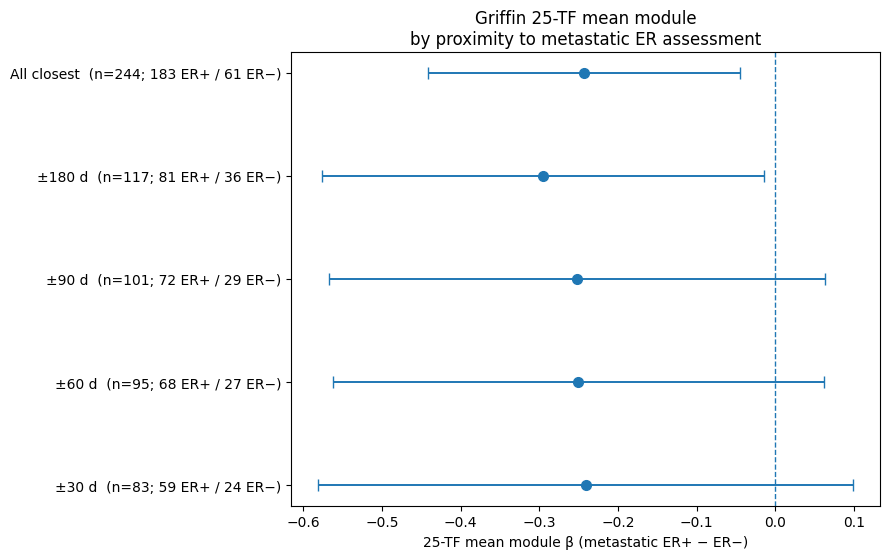

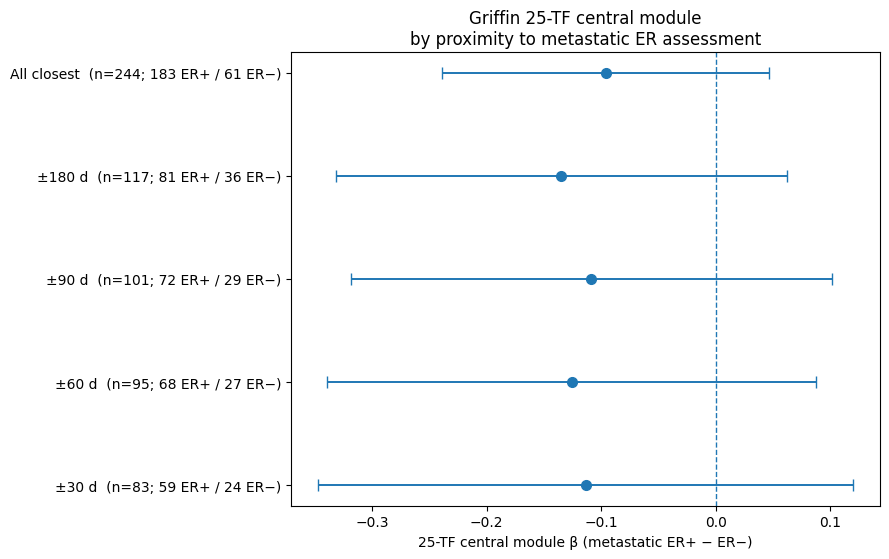

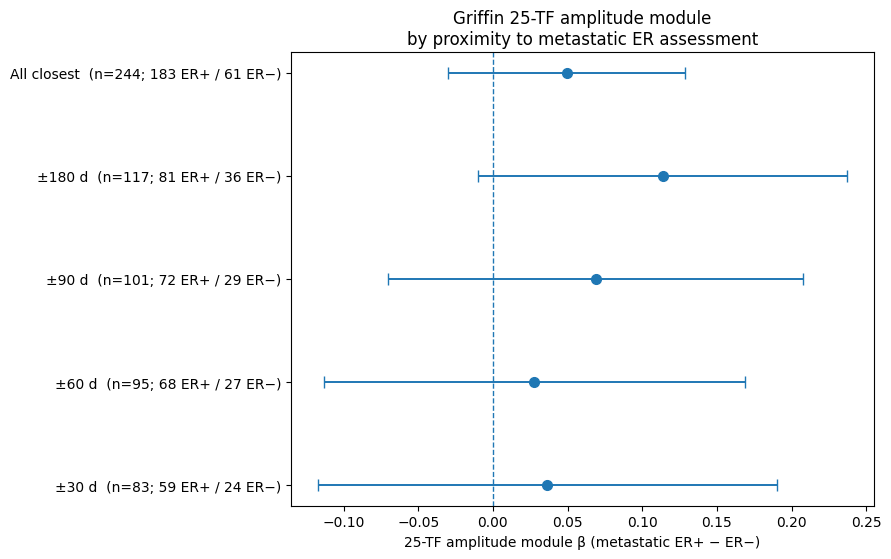

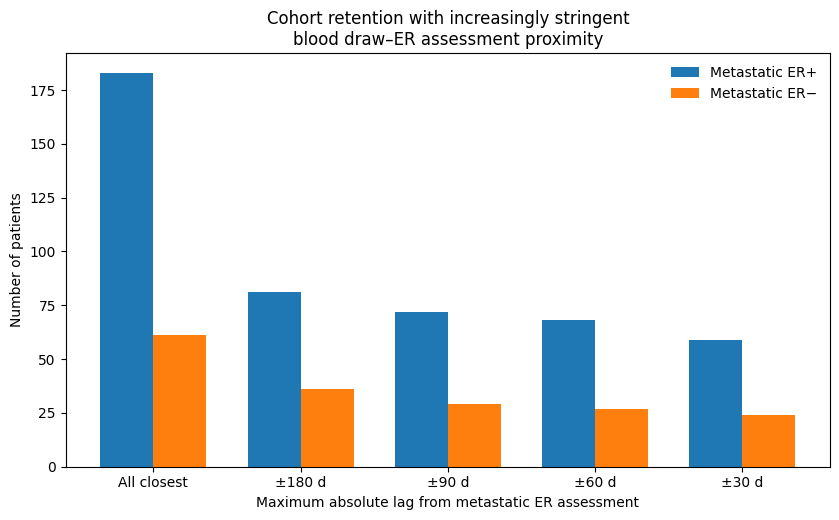

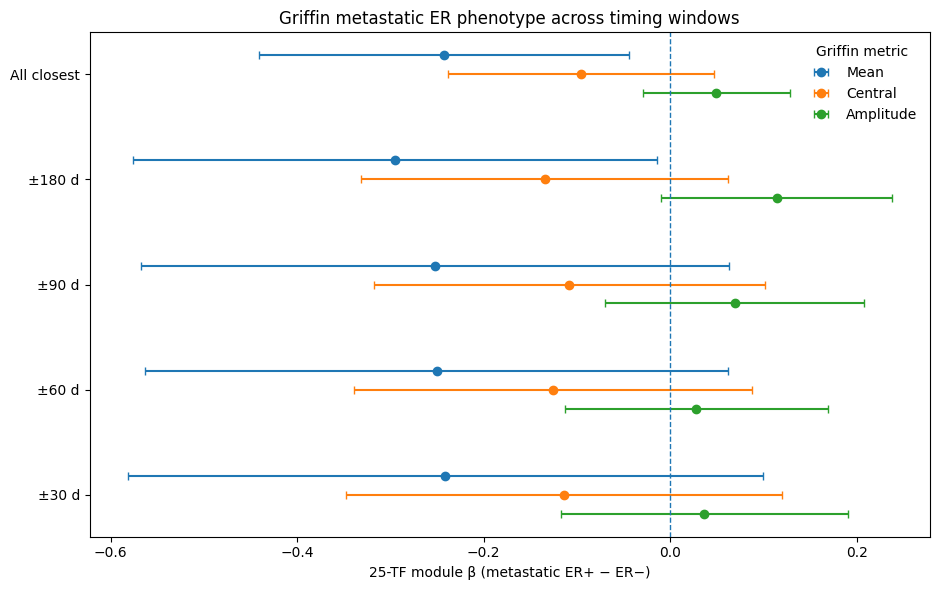


ANALYSIS COMPLETE

Output directory:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Met_ER_Closest_Draw_TFBS

Saved tables:
1. 25TF_Module_results_long.tsv
2. 25TF_Module_timing_summary_full.tsv
3. 25TF_Module_timing_summary.tsv
4. 25TF_CohortSpecific_Zscore_parameters.tsv

Saved figures:
1. Figure_25TF_Mean_Module_Timing_Forest
2. Figure_25TF_Central_Module_Timing_Forest
3. Figure_25TF_Amplitude_Module_Timing_Forest
4. Figure_Cohort_Size_By_ER_Assessment_Window
5. Figure_25TF_All3Metrics_Timing_Forest


In [2]:
# ======================================================================
# AURORA
# Metastatic ER phenotype using Griffin draw closest to
# first informative metastatic ER assessment
#
# 25-TF BREAST-LINEAGE / PLASTICITY PANEL
#
# Griffin metrics analyzed independently:
#   1. Mean coverage
#   2. Central coverage
#   3. Amplitude
#
# For EACH timing-defined cohort:
#   - TF-specific mean and SD are recalculated within that cohort
#   - 25 TFBS are z-standardized within that cohort
#   - module = mean of the 25 TF-specific z-scores
#
# Model:
#   Module ~ Metastatic_ER + TFx
#
# ER coding:
#   ER- = 0
#   ER+ = 1
#
# Therefore:
#   beta = ER+ - ER-
#
# Statistical inference:
#   OLS + HC3 robust standard errors
#
# Seed:
#   1234
#
# ======================================================================


# ======================================================================
# 0. IMPORTS
# ======================================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from statsmodels.stats.multitest import multipletests

SEED = 1234

np.random.seed(SEED)

# ======================================================================
# 1. PATHS
# ======================================================================
#
# EDIT THESE PATHS FOR YOUR SERVER.
#
# The patient audit should contain:
#   patient_id
#   met_ER
#   selected_sample
#   abs_lag_days
#   TFx_pct
#
# selected_sample = Griffin draw closest to first informative
# metastatic ER assessment.
#
# ======================================================================


AUDIT_TSV = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Met_ER_Closest_Draw_TFBS/ClosestDraw_MetER_patient_audit.tsv"
)


GRIFFIN_XLSX = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/griffin_nucleosome_profiling/"
    "Griffin_44TF_GC_corrected_summary_by_module.xlsx"
)


OUT_DIR = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/"
    "AURORA_Griffin_Met_ER_Closest_Draw_TFBS"
)


OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


print("Output directory:")
print(OUT_DIR)


# ======================================================================
# 2. FIXED 25-TF PANEL
# ======================================================================

TF25 = [
    "ESR1", "FOXA1", "GATA3", "PGR", "GRHL2",
    "STAT3", "NFKB1", "TFAP2C", "XBP1", "FOXM1", 
    "FOXO3", "AR", "ESR2", "FOXO1", "RUNX1", 
    "E2F1", "E2F7", "TEAD1", "TEAD4", "FOSL1", 
    "BACH1", "HIF1A", "ETS1", "CEBPB", "ELF3"
]

assert len(TF25) == 25

print("\nFixed TFBS panel:")
print(TF25)

print("\nNumber of TFBS:")
print(len(TF25))

# ======================================================================
# 3. DEFINE THE THREE GRIFFIN METRIC FAMILIES
# ======================================================================

METRICS = {

    "Mean":
        "mean_coverage",

    "Central":
        "central_coverage",

    "Amplitude":
        "amplitude"
}


# All 75 expected columns:
# 25 TF x 3 metrics

EXPECTED_FEATURES = []

for tf in TF25:

    for suffix in METRICS.values():

        EXPECTED_FEATURES.append(
            f"{tf}_{suffix}"
        )


print(
    "\nExpected Griffin features:",
    len(EXPECTED_FEATURES)
)


# ======================================================================
# 4. LOAD CLOSEST-DRAW PATIENT AUDIT
# ======================================================================

audit = pd.read_csv(
    AUDIT_TSV,
    sep="\t"
)


print("\n==============================================")
print("AUDIT FILE QC")
print("==============================================")

print(
    "Rows:",
    len(audit)
)


print(
    "\nColumns:"
)

print(
    audit.columns.tolist()
)


# Required columns
required_audit_cols = [

    "patient_id",
    "met_ER",
    "selected_sample",
    "abs_lag_days",
    "TFx_pct"
]


missing_audit_cols = [

    x for x in required_audit_cols

    if x not in audit.columns
]


if missing_audit_cols:

    raise ValueError(

        "Audit file is missing required columns:\n"
        f"{missing_audit_cols}"
    )


# Keep informative metastatic ER only

audit = audit.loc[

    audit["met_ER"].isin(
        [
            "Positive",
            "Negative"
        ]
    )

].copy()


# Numeric conversion

audit["abs_lag_days"] = pd.to_numeric(

    audit["abs_lag_days"],
    errors="coerce"
)


audit["TFx_pct"] = pd.to_numeric(

    audit["TFx_pct"],
    errors="coerce"
)


print(
    "\nMetastatic ER counts:"
)

print(
    audit["met_ER"].value_counts()
)


print(
    "\nTotal informative cases:",
    len(audit)
)


# ======================================================================
# 5. LOAD BREAST-LINEAGE SHEET FROM GRIFFIN WORKBOOK
# ======================================================================
#
# Griffin workbook has a two-row header:
#
# row 1:
# sample | ESR1 | ... | FOXA1 ...
#
# row 2:
#        | ESR1_mean_coverage
#        | ESR1_central_coverage
#        | ESR1_amplitude ...
#
# ======================================================================


griffin = pd.read_excel(

    GRIFFIN_XLSX,

    sheet_name="Breast_Lineage",

    header=[
        0,
        1
    ]
)


print("\n==============================================")
print("GRIFFIN WORKBOOK")
print("==============================================")


print(
    "Raw Griffin shape:",
    griffin.shape
)


# ======================================================================
# 6. FLATTEN TWO-ROW COLUMN HEADER
# ======================================================================

new_columns = []


for col1, col2 in griffin.columns:

    col1_str = str(col1)

    col2_str = str(col2)


    # Sample column
    if col1_str.lower() == "sample":

        new_columns.append(
            "sample"
        )


    # Real second-row Griffin metric name
    elif (
        pd.notna(col2)
        and
        not col2_str.startswith("Unnamed")
    ):

        new_columns.append(
            col2_str
        )


    # Fallback
    else:

        new_columns.append(
            col1_str
        )


griffin.columns = new_columns


print(
    "\nFlattened columns:"
)

print(
    griffin.columns.tolist()
)


# ======================================================================
# 7. NORMALIZE SAMPLE NAMES
# ======================================================================

def normalize_sample_id(x):

    if pd.isna(x):

        return np.nan


    x = str(x).strip()


    # Griffin usually uses AL1Y-NB1
    # while some files may contain AUP-AL1Y-NB1

    if x.startswith("AUP-"):

        x = x[4:]


    return x


griffin["sample"] = (

    griffin["sample"]
    .map(normalize_sample_id)
)


audit["selected_sample"] = (

    audit["selected_sample"]
    .map(normalize_sample_id)
)


# ======================================================================
# 8. VERIFY ALL 25 TF x 3 METRICS ARE AVAILABLE
# ======================================================================

missing_features = [

    x for x in EXPECTED_FEATURES

    if x not in griffin.columns
]


if missing_features:

    print(
        "\nERROR: Missing Griffin features:"
    )

    for x in missing_features:

        print(x)


    raise ValueError(

        f"\n{len(missing_features)} required "
        "25-TF Griffin features are missing.\n"
        "Check that you are using the updated "
        "44-TF Griffin workbook."
    )


print(
    "\nAll 75 Griffin features found:"
)

print(
    "25 TFBS × 3 metrics"
)


# ======================================================================
# 9. MERGE SELECTED CLOSEST-DRAW PATIENTS WITH GRIFFIN
# ======================================================================

griffin_sub = griffin[

    [
        "sample"
    ]
    +
    EXPECTED_FEATURES

].copy()


df = audit.merge(

    griffin_sub,

    left_on="selected_sample",

    right_on="sample",

    how="left",

    validate="one_to_one"
)


print("\n==============================================")
print("MERGE QC")
print("==============================================")


print(
    "Patients after merge:",
    len(df)
)


# ======================================================================
# 10. CHECK MISSING GRIFFIN VALUES
# ======================================================================

missing_griffin = (

    df[EXPECTED_FEATURES]
    .isna()
    .any(axis=1)
)


print(
    "Patients missing ≥1 of 75 Griffin measurements:",
    missing_griffin.sum()
)


if missing_griffin.any():

    print(
        "\nSamples with missing Griffin values:"
    )

    print(

        df.loc[

            missing_griffin,

            [
                "patient_id",
                "selected_sample",
                "met_ER"
            ]
        ]
    )


# Complete cases for this module analysis

df = df.loc[

    ~missing_griffin

].copy()


# Also require TFx

missing_tfx = (

    df["TFx_pct"]
    .isna()
)


print(
    "\nMissing TFx:",
    missing_tfx.sum()
)


df = df.loc[

    ~missing_tfx

].copy()


print(
    "\nFinal available patients:",
    len(df)
)


print(
    df["met_ER"].value_counts()
)


# ======================================================================
# 11. DEFINE TIMING COHORTS
# ======================================================================

cohorts = {


    "All closest":

        df.copy(),


    "±180 d":

        df.loc[
            df["abs_lag_days"] <= 180
        ].copy(),


    "±90 d":

        df.loc[
            df["abs_lag_days"] <= 90
        ].copy(),


    "±60 d":

        df.loc[
            df["abs_lag_days"] <= 60
        ].copy(),


    "±30 d":

        df.loc[
            df["abs_lag_days"] <= 30
        ].copy()
}


COHORT_ORDER = [

    "All closest",
    "±180 d",
    "±90 d",
    "±60 d",
    "±30 d"
]


print("\n==============================================")
print("TIMING COHORT QC")
print("==============================================")


for cohort_name in COHORT_ORDER:

    temp = cohorts[cohort_name]


    n_pos = (

        temp["met_ER"]
        .eq("Positive")
        .sum()
    )


    n_neg = (

        temp["met_ER"]
        .eq("Negative")
        .sum()
    )


    print(

        f"{cohort_name:12s} "
        f"n={len(temp):3d} | "
        f"ER+={n_pos:3d} | "
        f"ER-={n_neg:3d}"
    )


# ======================================================================
# 12. FUNCTION:
# CREATE COHORT-SPECIFIC 25-TF MODULES
# ======================================================================
#
# IMPORTANT:
#
# Every cohort gets its OWN:
#
#   mean
#   SD
#   z-scores
#
# So ±90-day scaling is based ONLY on the ±90-day patients.
#
# Mean, Central and Amplitude are standardized separately.
#
# ======================================================================


def create_25TF_modules_within_cohort(

    data,
    tf_list
):


    data = data.copy()


    scaling_records = []


    for metric_name, metric_suffix in METRICS.items():


        z_columns = []


        for tf in tf_list:


            feature = (

                f"{tf}_{metric_suffix}"
            )


            values = pd.to_numeric(

                data[feature],

                errors="coerce"
            )


            mean_value = (

                values.mean()
            )


            sd_value = (

                values.std(
                    ddof=1
                )
            )


            # QC
            if (
                pd.isna(sd_value)
                or
                sd_value == 0
            ):

                raise ValueError(

                    f"Invalid SD for "
                    f"{feature}"
                )


            z_column = (

                f"{feature}_z"
            )


            data[z_column] = (

                values
                -
                mean_value

            ) / sd_value


            z_columns.append(
                z_column
            )


            scaling_records.append(

                {
                    "Metric":
                        metric_name,

                    "TF":
                        tf,

                    "Feature":
                        feature,

                    "Mean":
                        mean_value,

                    "SD":
                        sd_value
                }
            )


        # --------------------------------------
        # Average all 25 standardized TFBS
        # --------------------------------------

        module_column = (

            f"Module25_{metric_name}"
        )


        data[module_column] = (

            data[z_columns]
            .mean(
                axis=1
            )
        )


    scaling_df = pd.DataFrame(

        scaling_records
    )


    return (
        data,
        scaling_df
    )


# ======================================================================
# 13. BUILD MODULES FOR EACH COHORT INDEPENDENTLY
# ======================================================================

cohort_scaling = {}


for cohort_name in COHORT_ORDER:


    cohorts[cohort_name], scaling = (

        create_25TF_modules_within_cohort(

            cohorts[cohort_name],

            TF25
        )
    )


    cohort_scaling[
        cohort_name
    ] = scaling


# ======================================================================
# 14. OPTIONAL QC:
# MODULE MEANS SHOULD BE ~0 WITHIN EACH COHORT
# ======================================================================

print("\n==============================================")
print("MODULE SCORE QC")
print("==============================================")


for cohort_name in COHORT_ORDER:


    temp = cohorts[
        cohort_name
    ]


    print(
        "\n",
        cohort_name
    )


    for metric in METRICS:


        col = (

            f"Module25_{metric}"
        )


        print(

            metric,

            "mean=",

            round(
                temp[col].mean(),
                6
            ),

            "SD=",

            round(
                temp[col].std(ddof=1),
                4
            )
        )


# ======================================================================
# 15. MODEL FUNCTION
# ======================================================================
#
# Module ~ ER + TFx
#
# ER- = reference
#
# Beta:
#     metastatic ER+ - metastatic ER-
#
# HC3 robust standard errors
#
# ======================================================================


def fit_module_model(

    data,
    module_column
):


    d = data.copy()


    d["ER_positive"] = (

        d["met_ER"]
        .eq("Positive")
        .astype(int)
    )


    X = d[
        [
            "ER_positive",
            "TFx_pct"
        ]
    ]


    X = sm.add_constant(
        X
    )


    y = d[
        module_column
    ]


    model = sm.OLS(

        y,
        X

    ).fit(

        cov_type="HC3"
    )


    beta = (

        model.params[
            "ER_positive"
        ]
    )


    se = (

        model.bse[
            "ER_positive"
        ]
    )


    p_value = (

        model.pvalues[
            "ER_positive"
        ]
    )


    ci = (

        model
        .conf_int()
        .loc[
            "ER_positive"
        ]
    )


    return {

        "Beta":
            beta,

        "HC3_SE":
            se,

        "CI95_low":
            ci.iloc[0],

        "CI95_high":
            ci.iloc[1],

        "p":
            p_value
    }


# ======================================================================
# 16. FIT ALL COHORT x METRIC MODELS
# ======================================================================

results = []


for cohort_name in COHORT_ORDER:


    d = cohorts[
        cohort_name
    ]


    n_total = len(d)


    n_pos = (

        d["met_ER"]
        .eq("Positive")
        .sum()
    )


    n_neg = (

        d["met_ER"]
        .eq("Negative")
        .sum()
    )


    for metric_name in METRICS.keys():


        module_col = (

            f"Module25_{metric_name}"
        )


        stats = fit_module_model(

            d,
            module_col
        )


        results.append(

            {

                "Cohort":
                    cohort_name,

                "Metric":
                    metric_name,

                "n":
                    n_total,

                "ER_positive_n":
                    n_pos,

                "ER_negative_n":
                    n_neg,

                "ER_pos_neg":
                    f"{n_pos} / {n_neg}",

                "Module_beta_ERpos_minus_ERneg":
                    stats["Beta"],

                "HC3_SE":
                    stats["HC3_SE"],

                "CI95_low":
                    stats["CI95_low"],

                "CI95_high":
                    stats["CI95_high"],

                "p":
                    stats["p"]
            }
        )


module_results = pd.DataFrame(

    results
)


# ======================================================================
# 17. OPTIONAL MULTIPLICITY ACROSS 3 MODULE METRICS
# ======================================================================
#
# Mean = primary
#
# Central and amplitude = secondary.
#
# This q-value is supplied for transparency,
# but I would still report mean coverage as the primary metric.
#
# BH is performed across:
#
# Mean
# Central
# Amplitude
#
# WITHIN each timing cohort.
#
# ======================================================================


module_results[
    "BH_q3"
] = np.nan


for cohort_name in COHORT_ORDER:


    mask = (

        module_results[
            "Cohort"
        ]
        ==
        cohort_name
    )


    p_values = (

        module_results.loc[
            mask,
            "p"
        ]
        .to_numpy()
    )


    q_values = multipletests(

        p_values,

        method="fdr_bh"
    )[1]


    module_results.loc[

        mask,

        "BH_q3"

    ] = q_values


# ======================================================================
# 18. PRINT COMPLETE RESULT
# ======================================================================

pd.set_option(
    "display.max_columns",
    50
)


print("\n==============================================")
print("25-TF MODULE RESULTS")
print("==============================================")


print(

    module_results[
        [
            "Cohort",
            "Metric",
            "n",
            "ER_pos_neg",
            "Module_beta_ERpos_minus_ERneg",
            "CI95_low",
            "CI95_high",
            "p",
            "BH_q3"
        ]
    ]
    .to_string(
        index=False
    )
)


# ======================================================================
# 19. CREATE WIDE SUMMARY TABLE
# ======================================================================

summary_rows = []


for cohort_name in COHORT_ORDER:


    temp = module_results.loc[

        module_results["Cohort"]
        ==
        cohort_name

    ]


    first = temp.iloc[0]


    row = {

        "Cohort":
            cohort_name,

        "n":
            first["n"],

        "ER+ / ER-":
            first["ER_pos_neg"]
    }


    for metric in [

        "Mean",
        "Central",
        "Amplitude"
    ]:


        r = temp.loc[

            temp["Metric"]
            ==
            metric

        ].iloc[0]


        row[
            f"{metric}_beta"
        ] = (

            r[
                "Module_beta_ERpos_minus_ERneg"
            ]
        )


        row[
            f"{metric}_CI_low"
        ] = (

            r["CI95_low"]
        )


        row[
            f"{metric}_CI_high"
        ] = (

            r["CI95_high"]
        )


        row[
            f"{metric}_p"
        ] = (

            r["p"]
        )


        row[
            f"{metric}_q3"
        ] = (

            r["BH_q3"]
        )


    summary_rows.append(
        row
    )


summary_wide = pd.DataFrame(

    summary_rows
)


# ======================================================================
# 20. DISPLAY-SPECIFIC TABLE
# ======================================================================

display_table = summary_wide[
    [
        "Cohort",
        "n",
        "ER+ / ER-",

        "Mean_beta",
        "Mean_p",

        "Central_beta",
        "Central_p",

        "Amplitude_beta",
        "Amplitude_p"
    ]
].copy()


display_table.columns = [

    "Cohort",
    "n",
    "ER+ / ER−",

    "Mean β",
    "Mean p",

    "Central β",
    "Central p",

    "Amplitude β",
    "Amplitude p"
]


# ======================================================================
# 21. Print
# ======================================================================

for col in [

    "Mean β",
    "Central β",
    "Amplitude β"
]:

    display_table[col] = (

        display_table[col]
        .map(
            lambda x:
            f"{x:.3f}"
        )
    )


for col in [

    "Mean p",
    "Central p",
    "Amplitude p"
]:

    display_table[col] = (

        display_table[col]
        .map(

            lambda x:

            f"{x:.4f}"

            if x >= 0.0001

            else

            f"{x:.2e}"
        )
    )


print("\n==============================================")
print("SUMMARY TABLE")
print("==============================================")


print(

    display_table
    .to_string(
        index=False
    )
)


# ======================================================================
# 22. SAVE RESULTS
# ======================================================================

module_results.to_csv(

    OUT_DIR /
    "25TF_Module_results_long.tsv",

    sep="\t",

    index=False
)


summary_wide.to_csv(

    OUT_DIR /
    "25TF_Module_timing_summary_full.tsv",

    sep="\t",

    index=False
)


display_table.to_csv(

    OUT_DIR /
    "25TF_Module_timing_summary.tsv",

    sep="\t",

    index=False
)


# Save scaling parameters for reproducibility

all_scaling = []


for cohort_name in COHORT_ORDER:


    temp = cohort_scaling[
        cohort_name
    ].copy()


    temp.insert(
        0,
        "Cohort",
        cohort_name
    )


    all_scaling.append(
        temp
    )


scaling_all = pd.concat(

    all_scaling,

    ignore_index=True
)


scaling_all.to_csv(

    OUT_DIR /
    "25TF_CohortSpecific_Zscore_parameters.tsv",

    sep="\t",

    index=False
)


# ======================================================================
# 23. FOREST PLOT FUNCTION
# ======================================================================


def make_forest_plot(

    result_df,
    metric_name,
    filename_prefix
):


    plot_df = result_df.loc[

        result_df["Metric"]
        ==
        metric_name

    ].copy()


    plot_df["Cohort"] = pd.Categorical(

        plot_df["Cohort"],

        categories=COHORT_ORDER,

        ordered=True
    )


    plot_df = (

        plot_df
        .sort_values("Cohort")
        .reset_index(drop=True)
    )


    beta = (

        plot_df[
            "Module_beta_ERpos_minus_ERneg"
        ]
        .to_numpy()
    )


    low = (

        plot_df[
            "CI95_low"
        ]
        .to_numpy()
    )


    high = (

        plot_df[
            "CI95_high"
        ]
        .to_numpy()
    )


    y = np.arange(

        len(plot_df)
    )


    labels = []


    for _, r in plot_df.iterrows():


        labels.append(

            f"{r['Cohort']}  "
            f"(n={r['n']}; "
            f"{r['ER_positive_n']} ER+ / "
            f"{r['ER_negative_n']} ER−)"
        )


    fig, ax = plt.subplots(

        figsize=(
            9,
            5.7
        )
    )


    ax.errorbar(

        beta,

        y,

        xerr=[
            beta - low,
            high - beta
        ],

        fmt="o",

        markersize=7,

        capsize=4,

        linewidth=1.4
    )


    ax.axvline(

        0,

        linestyle="--",

        linewidth=1
    )


    ax.set_yticks(

        y,

        labels
    )


    ax.invert_yaxis()


    ax.set_xlabel(

        f"25-TF {metric_name.lower()} module β "
        "(metastatic ER+ − ER−)"
    )


    ax.set_title(

        f"Griffin 25-TF {metric_name.lower()} module\n"
        "by proximity to metastatic ER assessment"
    )


    plt.tight_layout()


    fig.savefig(

        OUT_DIR /
        f"{filename_prefix}.png",

        dpi=600,

        bbox_inches="tight"
    )


    fig.savefig(

        OUT_DIR /
        f"{filename_prefix}.pdf",

        bbox_inches="tight"
    )


    plt.show()


    plt.close(fig)


# ======================================================================
# 24. FOREST — MEAN COVERAGE
# ======================================================================

make_forest_plot(

    module_results,

    metric_name="Mean",

    filename_prefix=
        "Figure_25TF_Mean_Module_Timing_Forest"
)


# ======================================================================
# 25. FOREST — CENTRAL COVERAGE
# ======================================================================

make_forest_plot(

    module_results,

    metric_name="Central",

    filename_prefix=
        "Figure_25TF_Central_Module_Timing_Forest"
)


# ======================================================================
# 26. FOREST — AMPLITUDE
# ======================================================================

make_forest_plot(

    module_results,

    metric_name="Amplitude",

    filename_prefix=
        "Figure_25TF_Amplitude_Module_Timing_Forest"
)


# ======================================================================
# 27. COHORT SIZE PLOT
# ======================================================================

count_df = (

    module_results.loc[

        module_results[
            "Metric"
        ]
        ==
        "Mean"

    ]
    .copy()
)


count_df["Cohort"] = pd.Categorical(

    count_df["Cohort"],

    categories=COHORT_ORDER,

    ordered=True
)


count_df = (

    count_df
    .sort_values("Cohort")
)


x = np.arange(

    len(count_df)
)


width = 0.36


fig, ax = plt.subplots(

    figsize=(
        8.5,
        5.3
    )
)


ax.bar(

    x - width / 2,

    count_df[
        "ER_positive_n"
    ],

    width,

    label=
        "Metastatic ER+"
)


ax.bar(

    x + width / 2,

    count_df[
        "ER_negative_n"
    ],

    width,

    label=
        "Metastatic ER−"
)


ax.set_xticks(

    x,

    count_df[
        "Cohort"
    ]
)


ax.set_ylabel(

    "Number of patients"
)


ax.set_xlabel(

    "Maximum absolute lag from metastatic ER assessment"
)


ax.set_title(

    "Cohort retention with increasingly stringent\n"
    "blood draw–ER assessment proximity"
)


ax.legend(

    frameon=False
)


plt.tight_layout()


fig.savefig(

    OUT_DIR /
    "Figure_Cohort_Size_By_ER_Assessment_Window.png",

    dpi=600,

    bbox_inches="tight"
)


fig.savefig(

    OUT_DIR /
    "Figure_Cohort_Size_By_ER_Assessment_Window.pdf",

    bbox_inches="tight"
)


plt.show()


plt.close(fig)


# ======================================================================
# 28. OPTIONAL COMBINED PLOT:
# THREE MODULE METRICS TOGETHER
# ======================================================================
#
# shown side-by-side for each timing window.
#
# ======================================================================


plot_df = module_results.copy()


plot_df["Cohort"] = pd.Categorical(

    plot_df["Cohort"],

    categories=COHORT_ORDER,

    ordered=True
)


plot_df = (

    plot_df
    .sort_values(
        [
            "Cohort",
            "Metric"
        ]
    )
)


fig, ax = plt.subplots(

    figsize=(
        9.5,
        6
    )
)


offsets = {

    "Mean":
        -0.18,

    "Central":
        0,

    "Amplitude":
        0.18
}


y_base = np.arange(

    len(COHORT_ORDER)
)


for metric in [

    "Mean",
    "Central",
    "Amplitude"
]:


    temp = plot_df.loc[

        plot_df[
            "Metric"
        ]
        ==
        metric

    ].copy()


    temp = (

        temp
        .set_index("Cohort")
        .loc[COHORT_ORDER]
        .reset_index()
    )


    beta = (

        temp[
            "Module_beta_ERpos_minus_ERneg"
        ]
        .to_numpy()
    )


    low = (

        temp[
            "CI95_low"
        ]
        .to_numpy()
    )


    high = (

        temp[
            "CI95_high"
        ]
        .to_numpy()
    )


    y = (

        y_base
        +
        offsets[metric]
    )


    ax.errorbar(

        beta,

        y,

        xerr=[
            beta - low,
            high - beta
        ],

        fmt="o",

        capsize=3,

        label=metric
    )


ax.axvline(

    0,

    linestyle="--",

    linewidth=1
)


ax.set_yticks(

    y_base,

    COHORT_ORDER
)


ax.invert_yaxis()


ax.set_xlabel(

    "25-TF module β "
    "(metastatic ER+ − ER−)"
)


ax.set_title(

    "Griffin metastatic ER phenotype across timing windows"
)


ax.legend(

    title="Griffin metric",

    frameon=False
)


plt.tight_layout()


fig.savefig(

    OUT_DIR /
    "Figure_25TF_All3Metrics_Timing_Forest.png",

    dpi=600,

    bbox_inches="tight"
)


fig.savefig(

    OUT_DIR /
    "Figure_25TF_All3Metrics_Timing_Forest.pdf",

    bbox_inches="tight"
)


plt.show()


plt.close(fig)


# ======================================================================
# 29. FINAL OUTPUT SUMMARY
# ======================================================================

print("\n==============================================")
print("ANALYSIS COMPLETE")
print("==============================================")


print(
    "\nOutput directory:"
)

print(
    OUT_DIR
)


print(
    "\nSaved tables:"
)

print(
    "1. 25TF_Module_results_long.tsv"
)

print(
    "2. 25TF_Module_timing_summary_full.tsv"
)

print(
    "3. 25TF_Module_timing_summary.tsv"
)

print(
    "4. 25TF_CohortSpecific_Zscore_parameters.tsv"
)


print(
    "\nSaved figures:"
)

print(
    "1. Figure_25TF_Mean_Module_Timing_Forest"
)

print(
    "2. Figure_25TF_Central_Module_Timing_Forest"
)

print(
    "3. Figure_25TF_Amplitude_Module_Timing_Forest"
)

print(
    "4. Figure_Cohort_Size_By_ER_Assessment_Window"
)

print(
    "5. Figure_25TF_All3Metrics_Timing_Forest"
)

Output directory:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Met_ER_Closest_Draw_TFBS/AllClosest_25TF_ERpos_vs_ERneg

Expected TFBS measurements: 75

PATIENT AUDIT
Rows: 244

Metastatic ER:
Positive    183
Negative     61
Name: met_ER, dtype: int64

GRIFFIN
Raw shape: (769, 76)

All 75 required measurements found.

ALL-CLOSEST COHORT QC
Patients after merge: 244

ER distribution:
Positive    183
Negative     61
Name: met_ER, dtype: int64

Patients missing >=1 Griffin value: 0
Patients missing TFx: 0

FINAL ANALYSIS DATA
n = 244
ER+ = 183
ER- = 61


MEAN COVERAGE — 25 TFBS
    TF  beta_ERpos_minus_ERneg  CI95_low  CI95_high        p   BH_q25  BH_q75_sensitivity
  ESR1               -0.005063 -0.008076  -0.002050 0.000990 0.004948            0.012370
 FOXA1               -0.006218 -0.010451  -0.001985 0.003988 0.016618            0.034580
 GATA3               -0.006471 -0.009591  -0.003352 0.000048 0.000741            0.002172
   PGR           

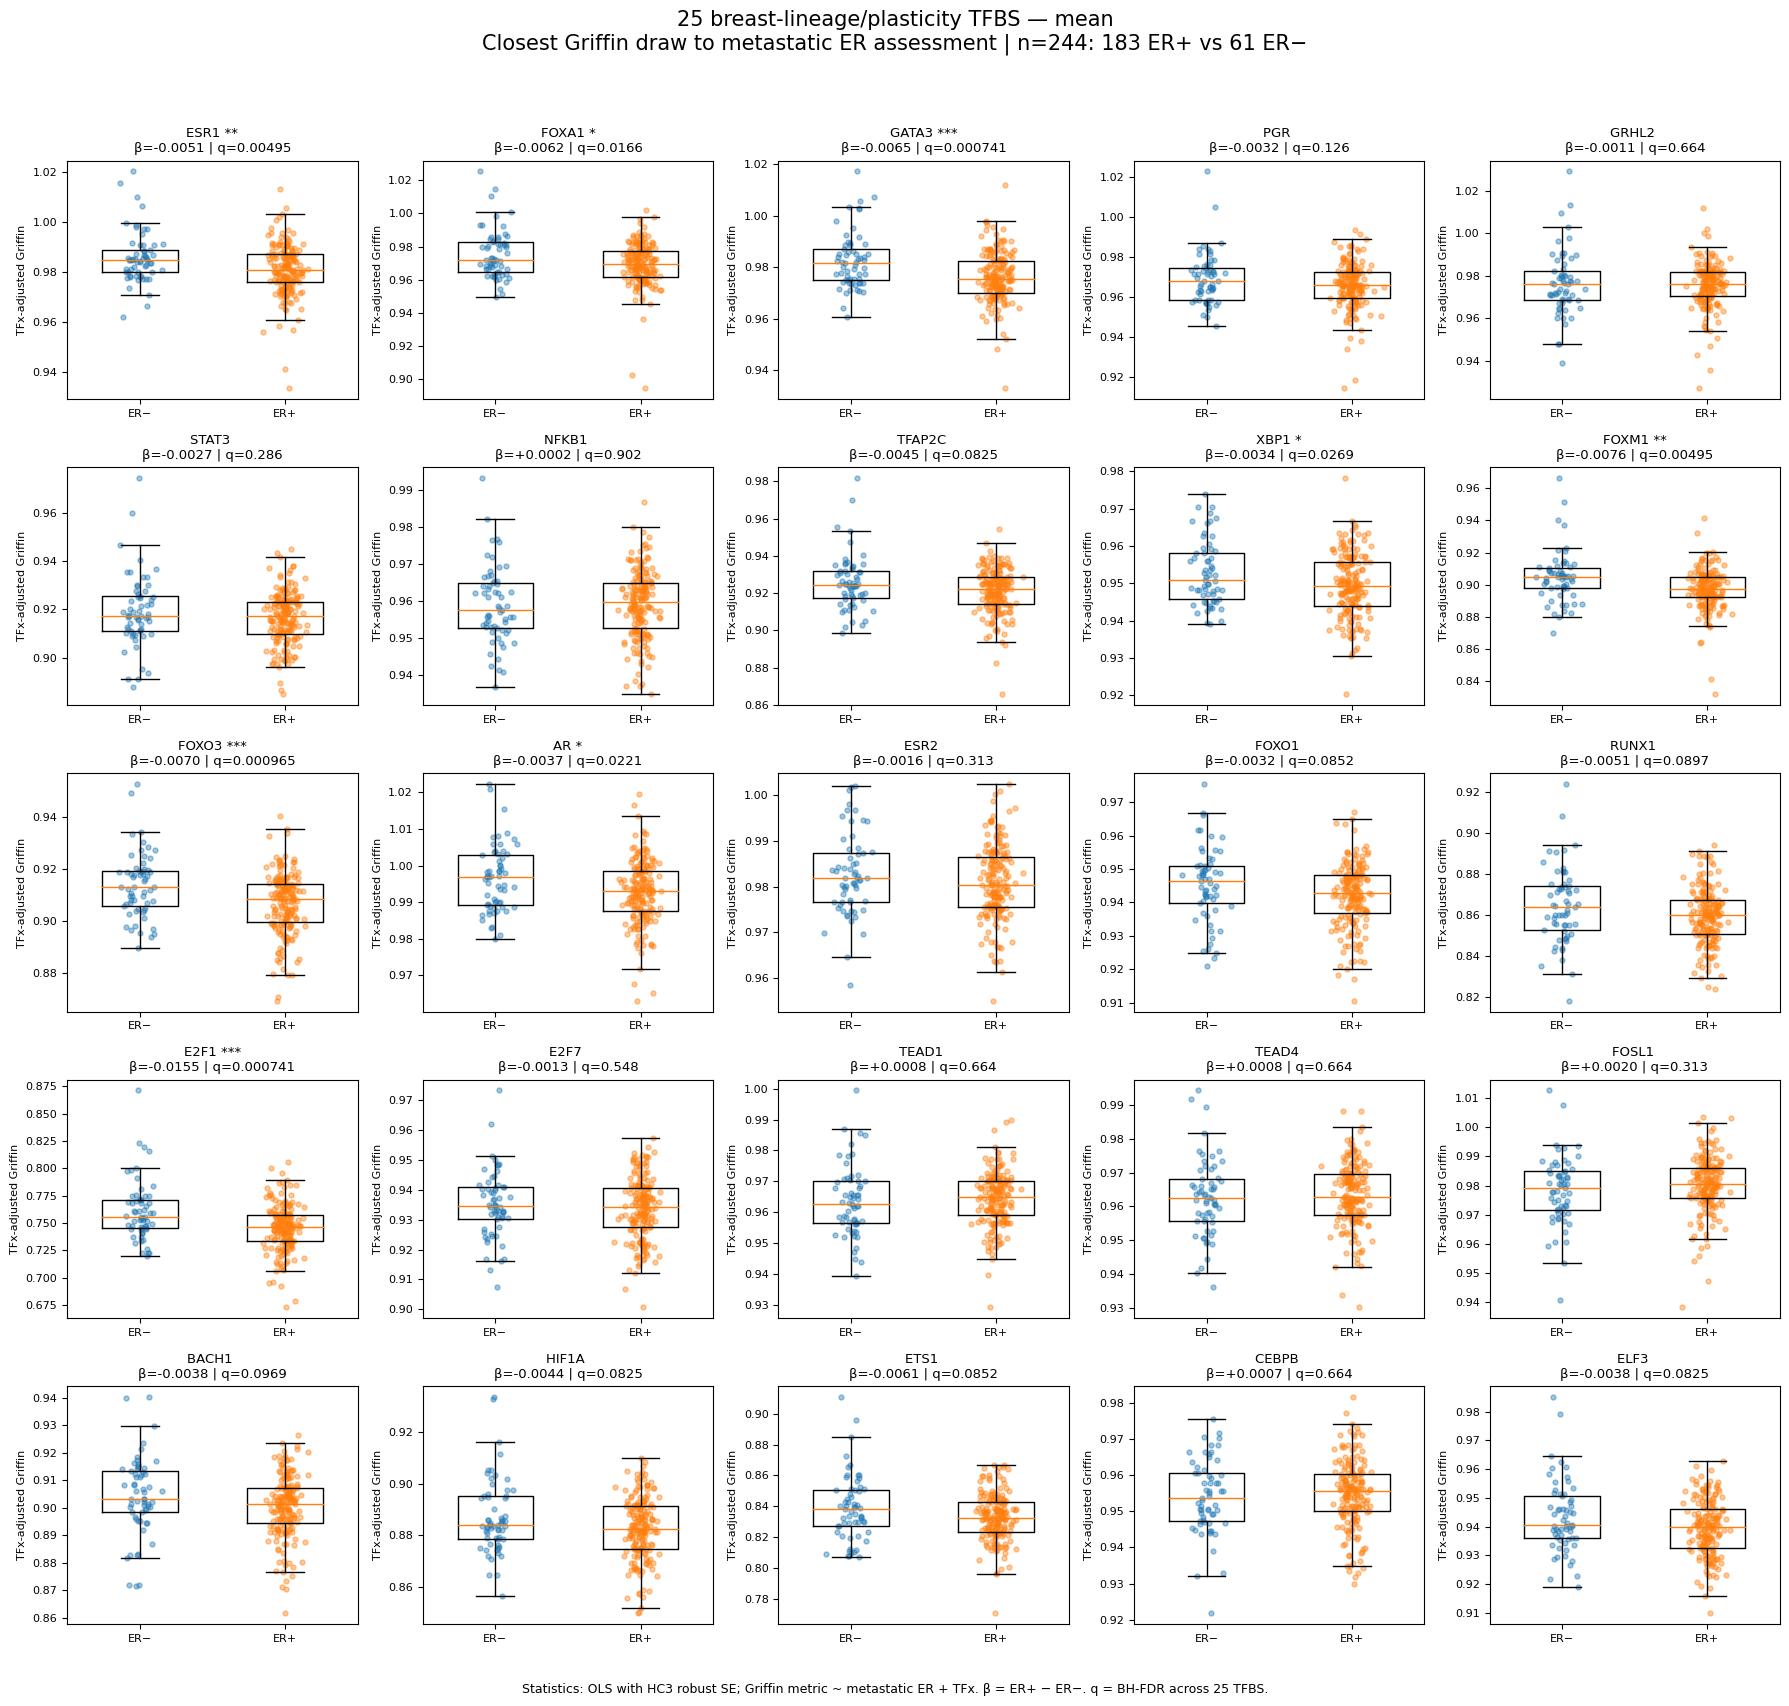

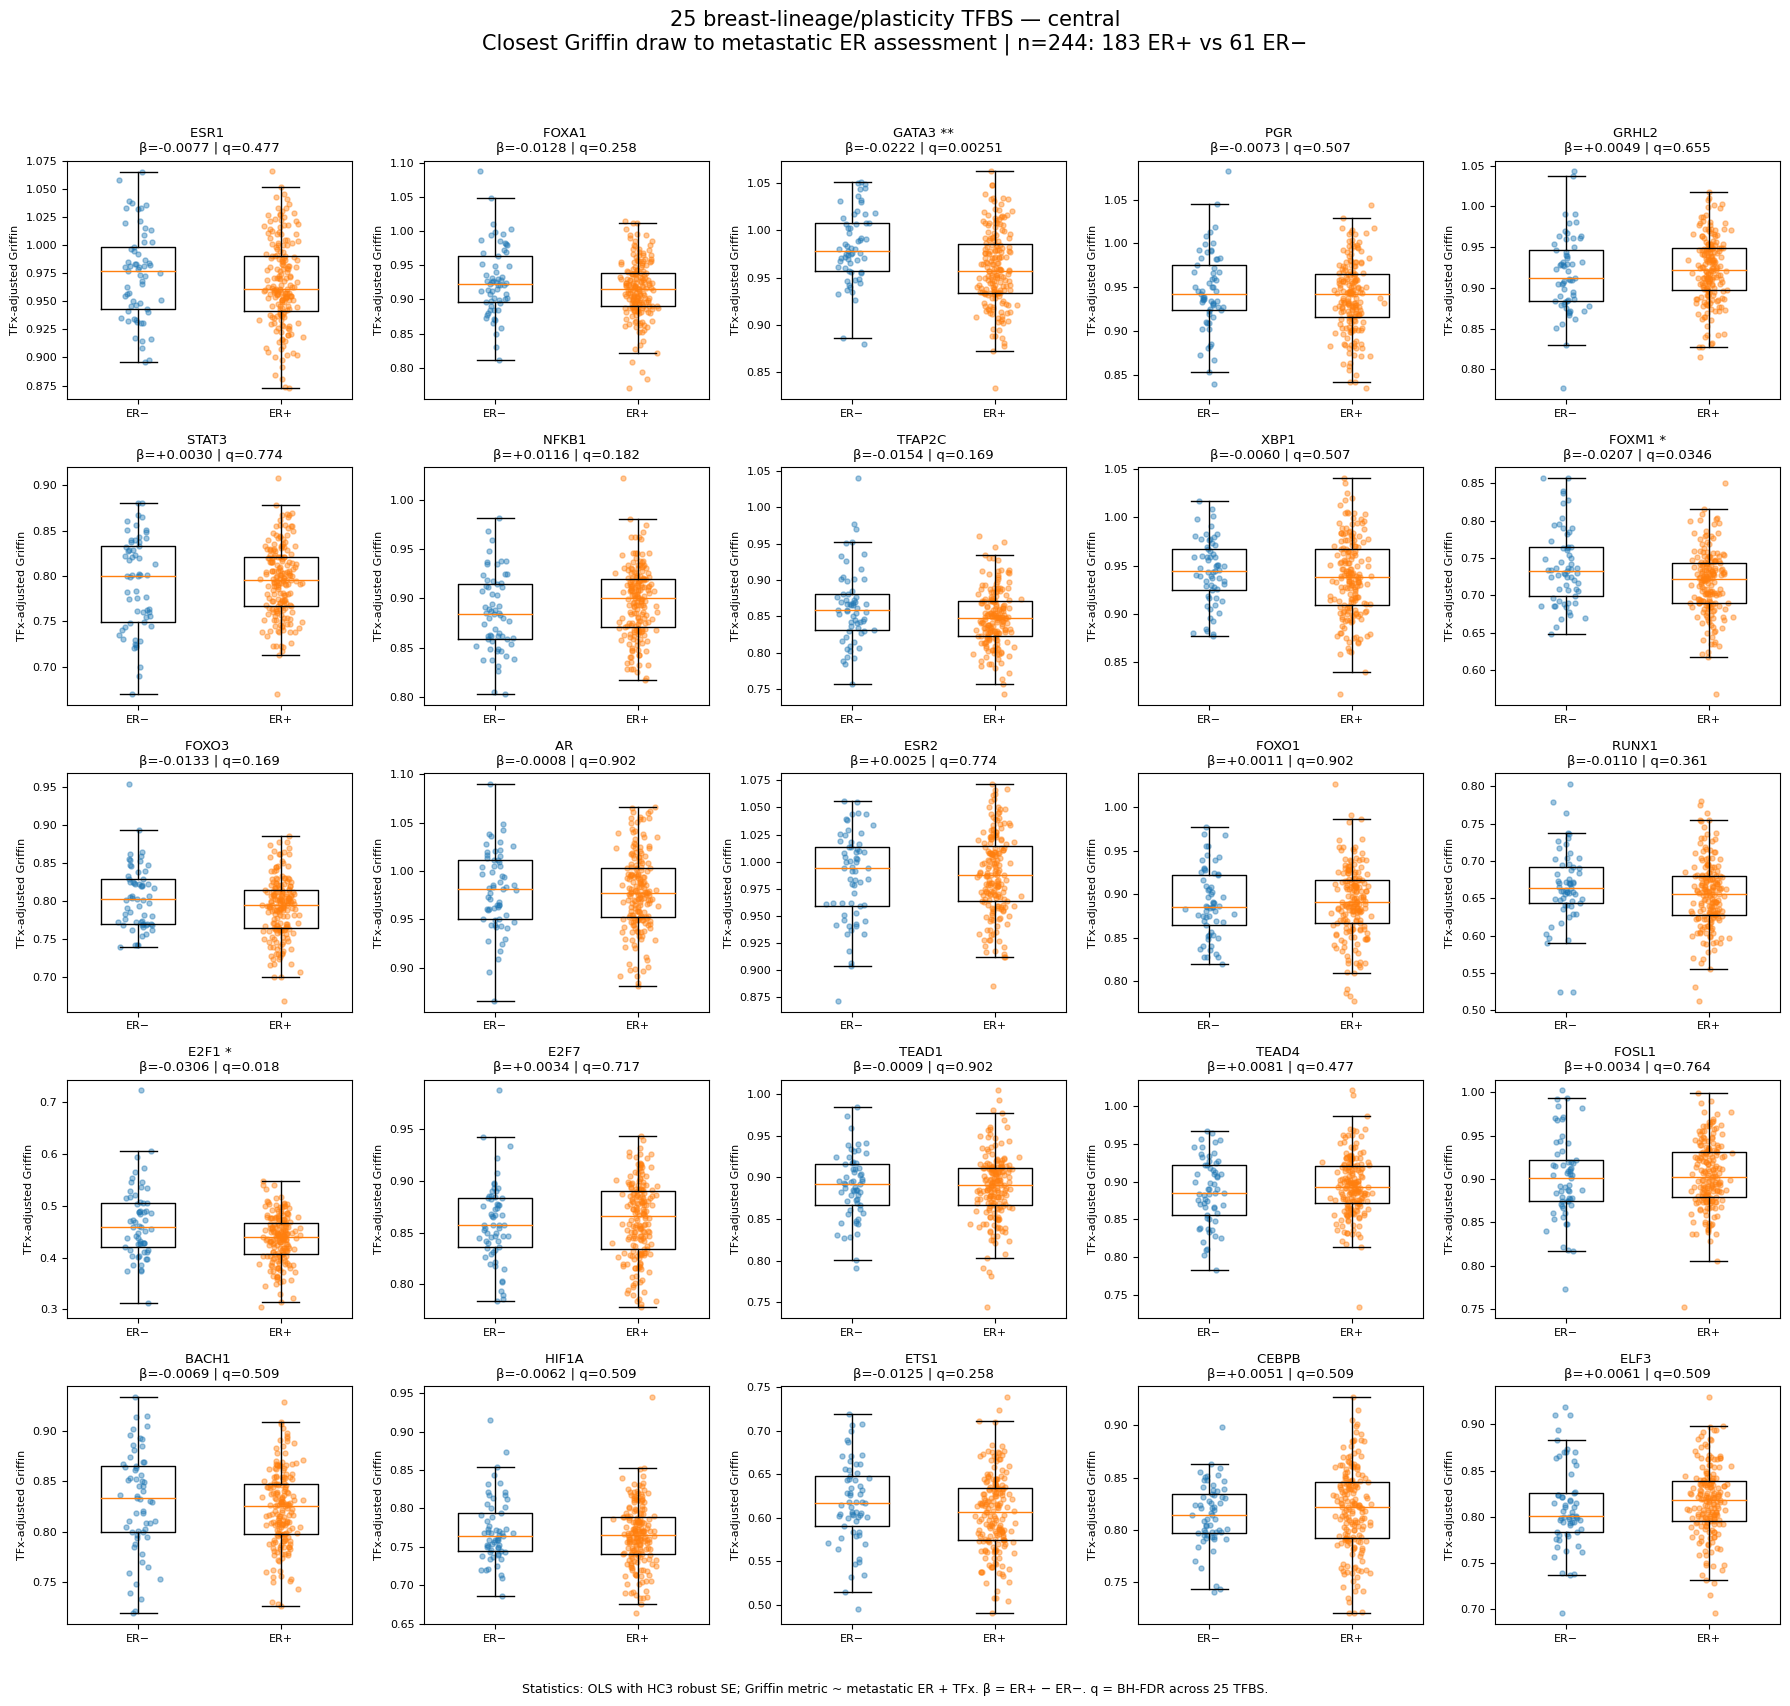

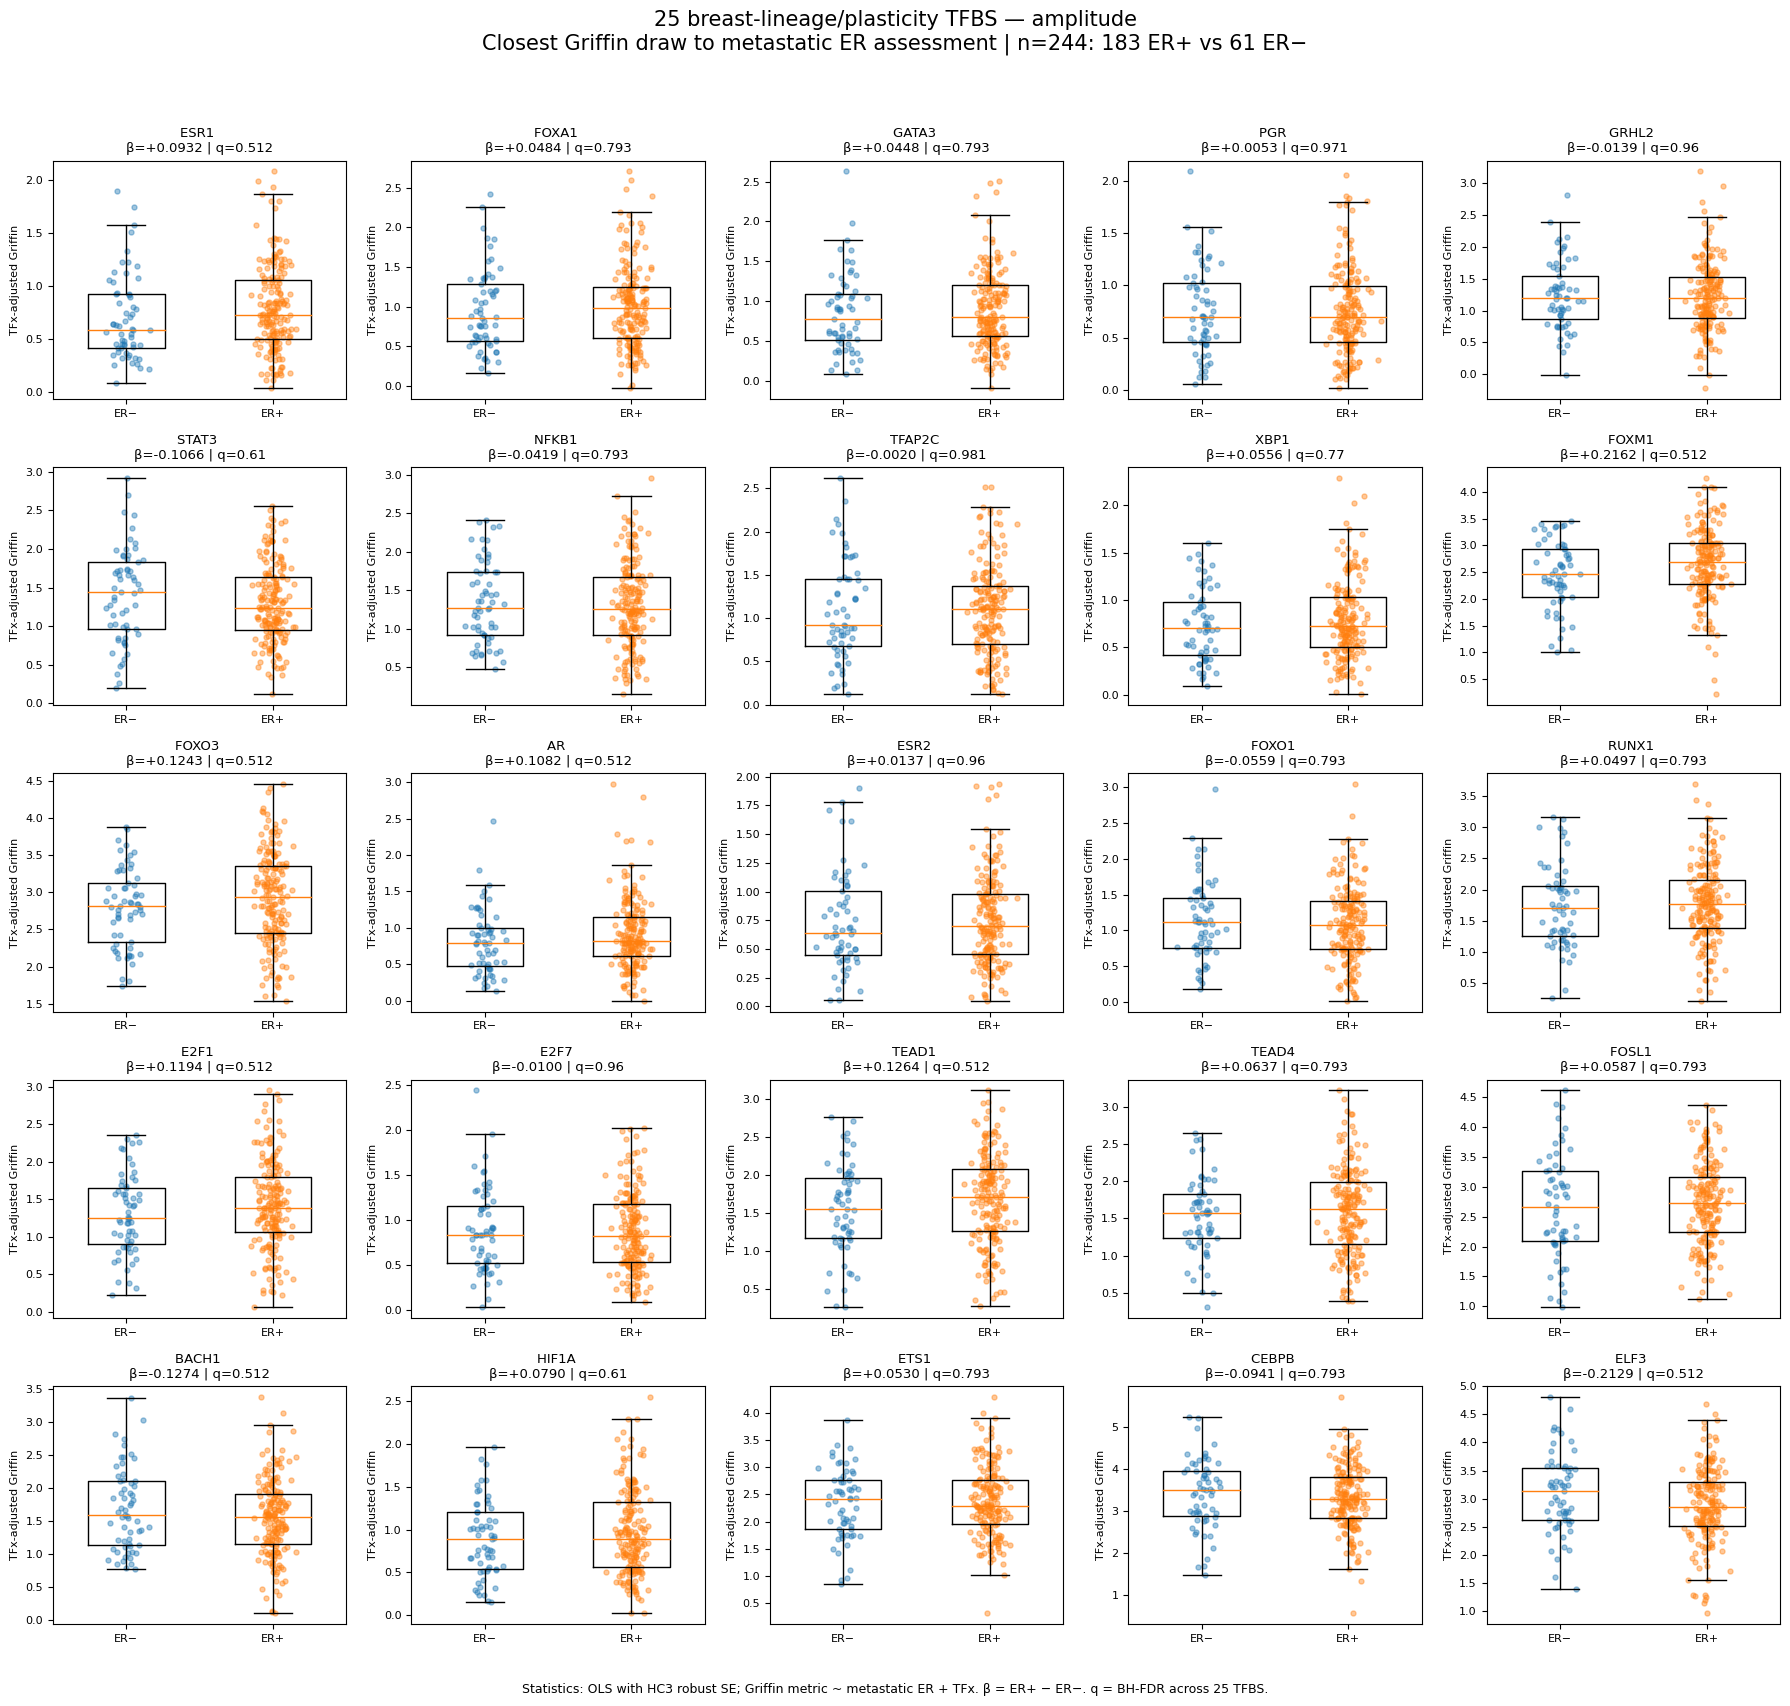

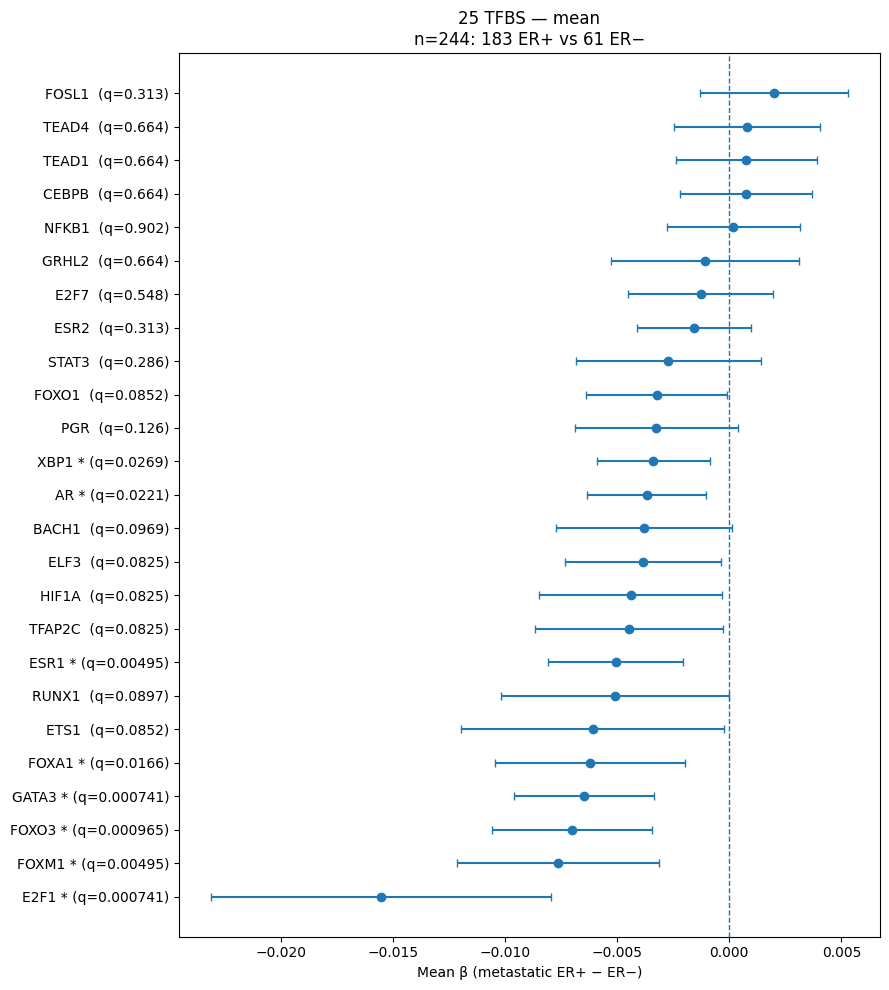

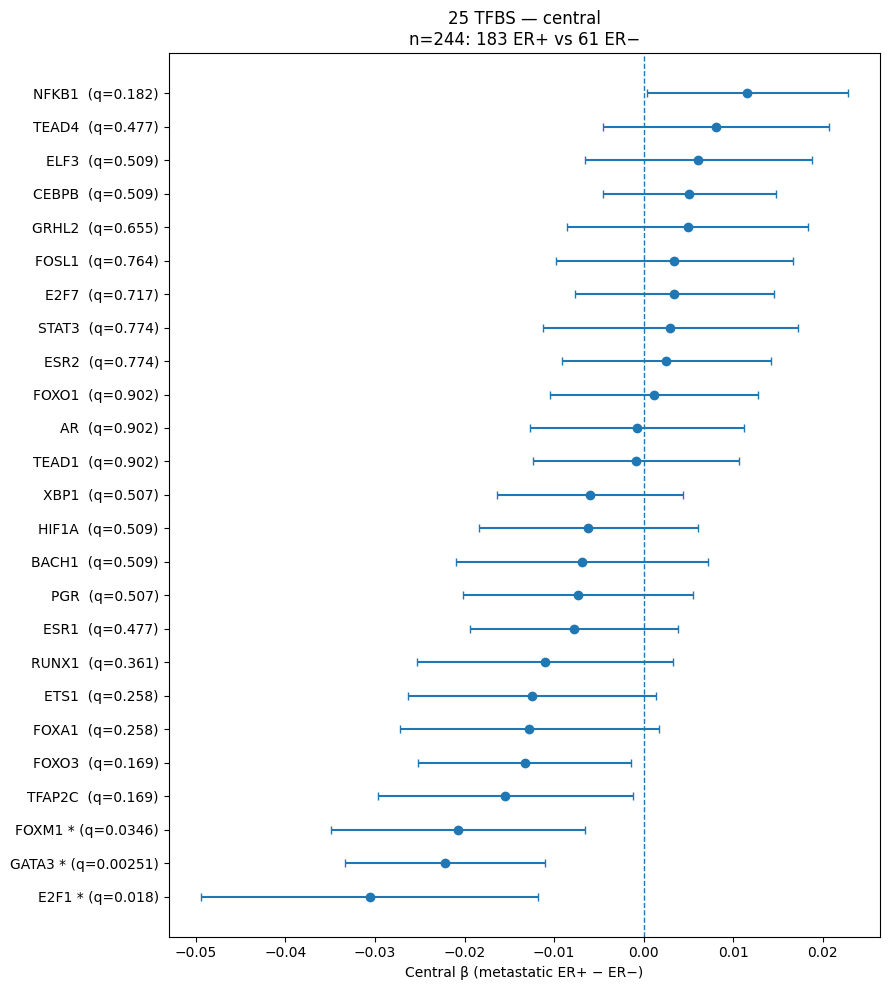

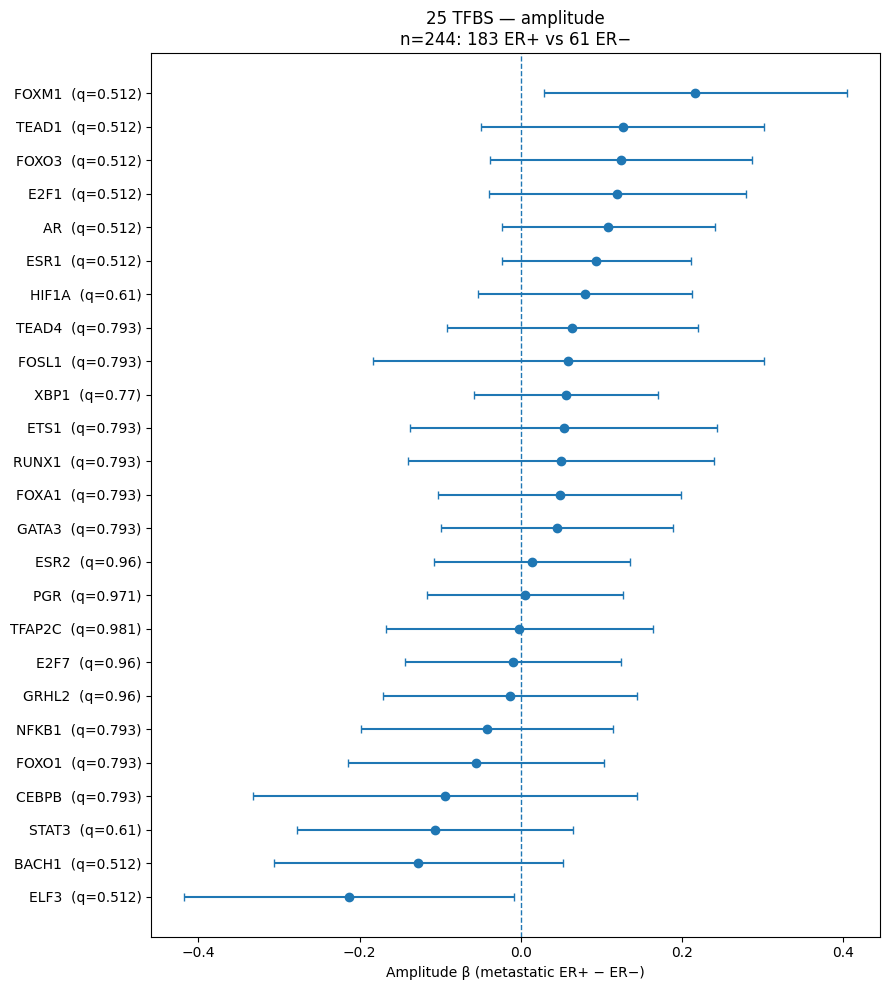


SUMMARY
   Metric  n_patients  ER_positive  ER_negative  Nominal_p_lt_0.05  FDR_q25_lt_0.05                      FDR_significant_TFBS
     Mean         244          183           61                 13                8 ESR1;FOXA1;GATA3;XBP1;FOXM1;FOXO3;AR;E2F1
  Central         244          183           61                  6                3                          GATA3;FOXM1;E2F1
Amplitude         244          183           61                  2                0                                          

ANALYSIS COMPLETE

Output directory:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Met_ER_Closest_Draw_TFBS/AllClosest_25TF_ERpos_vs_ERneg

Main results:
AllClosest_244_25TF_ERpos_vs_ERneg_all3metrics.tsv

Facet plots:
Figure_AllClosest_244_25TF_Mean_facet.png/pdf
Figure_AllClosest_244_25TF_Central_facet.png/pdf
Figure_AllClosest_244_25TF_Amplitude_facet.png/pdf

Forest plots:
Figure_AllClosest_244_25TF_Mean_forest.png/pdf
Figure_AllClosest_

In [11]:
# ======================================================================
# AURORA
# MAIN METASTATIC ER PHENOTYPE ANALYSIS
#
# 25 breast-lineage / plasticity TFBS
# ALL CLOSEST-DRAW PATIENTS ONLY
#
# Expected:
#   n = 244
#   metastatic ER+ = 183
#   metastatic ER- = 61
#
# Metrics:
#   1. Mean coverage
#   2. Central coverage
#   3. Amplitude
#
# Individual TFBS model:
#
#   Griffin_metric ~ metastatic_ER + TFx
#
# ER coding:
#   ER- = 0
#   ER+ = 1
#
# Therefore:
#   beta = ER+ - ER-
#
# Statistics:
#   OLS with HC3 robust standard errors
#
# Multiple testing:
#   Primary q-value = BH-FDR across 25 TFBS
#   SEPARATELY for Mean, Central, and Amplitude.
#
# Additional sensitivity:
#   q75 = BH-FDR across all 75 TFBS x metric tests.
#
# Figures:
#   - 5 x 5 facet plot for Mean
#   - 5 x 5 facet plot for Central
#   - 5 x 5 facet plot for Amplitude
#   - forest plot for each metric
#
# Seed = 1234
# ======================================================================


# ======================================================================
# 0. IMPORTS
# ======================================================================

from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

import statsmodels.api as sm

from statsmodels.stats.multitest import multipletests


SEED = 1234

rng = np.random.default_rng(SEED)


# ======================================================================
# 1. PATHS
# ======================================================================

BASE_DIR = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "Griffin/Downstream/"
    "AURORA_Griffin_Met_ER_Closest_Draw_TFBS"
)

AUDIT_TSV = (
    BASE_DIR /
    "ClosestDraw_MetER_patient_audit.tsv"
)

GRIFFIN_XLSX = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/griffin_nucleosome_profiling/"
    "Griffin_44TF_GC_corrected_summary_by_module.xlsx"
)

OUT_DIR = (
    BASE_DIR /
    "AllClosest_25TF_ERpos_vs_ERneg"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Output directory:")
print(OUT_DIR)


# ======================================================================
# 2. 25-TF PANEL
# ======================================================================

TF25 = [
    "ESR1", "FOXA1", "GATA3", "PGR", "GRHL2",
    "STAT3", "NFKB1", "TFAP2C", "XBP1", "FOXM1", 
    "FOXO3", "AR", "ESR2", "FOXO1", "RUNX1", 
    "E2F1", "E2F7", "TEAD1", "TEAD4", "FOSL1", 
    "BACH1", "HIF1A", "ETS1", "CEBPB", "ELF3"
]


assert len(TF25) == 25


# ======================================================================
# 3. METRIC DEFINITIONS
# ======================================================================

METRICS = {

    "Mean":
        "mean_coverage",

    "Central":
        "central_coverage",

    "Amplitude":
        "amplitude"
}


EXPECTED_FEATURES = [

    f"{tf}_{suffix}"

    for tf in TF25

    for suffix in METRICS.values()
]


print(
    "\nExpected TFBS measurements:",
    len(EXPECTED_FEATURES)
)

# Expected = 75


# ======================================================================
# 4. LOAD CLOSEST-DRAW PATIENT AUDIT
# ======================================================================

audit = pd.read_csv(
    AUDIT_TSV,
    sep="\t"
)


print("\n==============================================")
print("PATIENT AUDIT")
print("==============================================")


print(
    "Rows:",
    len(audit)
)


required_audit_cols = [
    "patient_id",
    "met_ER",
    "selected_sample",
    "TFx_pct",
    "abs_lag_days"
]


missing = [

    x for x in required_audit_cols

    if x not in audit.columns
]


if missing:

    raise ValueError(
        f"Missing audit columns: {missing}"
    )


# Informative ER only
audit = audit.loc[

    audit["met_ER"].isin(
        [
            "Positive",
            "Negative"
        ]
    )

].copy()


audit["TFx_pct"] = pd.to_numeric(
    audit["TFx_pct"],
    errors="coerce"
)


audit["abs_lag_days"] = pd.to_numeric(
    audit["abs_lag_days"],
    errors="coerce"
)


print(
    "\nMetastatic ER:"
)

print(
    audit["met_ER"].value_counts()
)


# ======================================================================
# 5. SAMPLE-ID NORMALIZATION
# ======================================================================

def normalize_sample_id(x):

    if pd.isna(x):
        return np.nan

    x = str(x).strip()

    if x.startswith("AUP-"):
        x = x[4:]

    return x


audit["selected_sample"] = (
    audit["selected_sample"]
    .map(normalize_sample_id)
)


# ======================================================================
# 6. LOAD GRIFFIN 25-TF DATA
# ======================================================================
#
# Workbook uses a two-row header.
# ======================================================================

griffin = pd.read_excel(

    GRIFFIN_XLSX,

    sheet_name="Breast_Lineage",

    header=[
        0,
        1
    ]
)


print("\n==============================================")
print("GRIFFIN")
print("==============================================")


print(
    "Raw shape:",
    griffin.shape
)


# ======================================================================
# 7. FLATTEN TWO-ROW HEADER
# ======================================================================

new_columns = []


for col1, col2 in griffin.columns:

    col1_str = str(col1)
    col2_str = str(col2)


    if col1_str.lower() == "sample":

        new_columns.append(
            "sample"
        )


    elif (
        pd.notna(col2)
        and
        not col2_str.startswith("Unnamed")
    ):

        new_columns.append(
            col2_str
        )


    else:

        new_columns.append(
            col1_str
        )


griffin.columns = new_columns


griffin["sample"] = (
    griffin["sample"]
    .map(normalize_sample_id)
)


# ======================================================================
# 8. VERIFY ALL 25 TFBS x 3 METRICS
# ======================================================================

missing_features = [

    x for x in EXPECTED_FEATURES

    if x not in griffin.columns
]


if missing_features:

    print(
        "\nMissing Griffin measurements:"
    )

    for x in missing_features:
        print(x)


    raise ValueError(

        f"{len(missing_features)} expected features are missing.\n"
        "Check that GRIFFIN_XLSX points to the updated 44-TF workbook."
    )


print(
    "\nAll 75 required measurements found."
)


# ======================================================================
# 9. MERGE THE 244 SELECTED DRAWS WITH GRIFFIN
# ======================================================================

griffin_sub = griffin[
    ["sample"] + EXPECTED_FEATURES
].copy()


df = audit.merge(

    griffin_sub,

    left_on="selected_sample",

    right_on="sample",

    how="left",

    validate="one_to_one"
)


# ======================================================================
# 10. MERGE QC
# ======================================================================

print("\n==============================================")
print("ALL-CLOSEST COHORT QC")
print("==============================================")


print(
    "Patients after merge:",
    len(df)
)


print(
    "\nER distribution:"
)

print(
    df["met_ER"].value_counts()
)


missing_griffin = (

    df[EXPECTED_FEATURES]
    .isna()
    .any(axis=1)
)


print(
    "\nPatients missing >=1 Griffin value:",
    int(missing_griffin.sum())
)


if missing_griffin.any():

    print(

        df.loc[
            missing_griffin,
            [
                "patient_id",
                "selected_sample",
                "met_ER"
            ]
        ]
    )


missing_tfx = df["TFx_pct"].isna()


print(
    "Patients missing TFx:",
    int(missing_tfx.sum())
)


# Analysis complete cases
df = df.loc[
    (~missing_griffin)
    &
    (~missing_tfx)
].copy()


n_total = len(df)

n_pos = (
    df["met_ER"]
    .eq("Positive")
    .sum()
)

n_neg = (
    df["met_ER"]
    .eq("Negative")
    .sum()
)


print("\n==============================================")
print("FINAL ANALYSIS DATA")
print("==============================================")


print(
    "n =", n_total
)

print(
    "ER+ =", n_pos
)

print(
    "ER- =", n_neg
)


if (
    n_total != 244
    or
    n_pos != 183
    or
    n_neg != 61
):

    print(
        "\nWARNING:"
        "\nExpected n=244, ER+=183, ER-=61."
        "\nCheck missing Griffin values or TFx."
    )


# ======================================================================
# 11. ER CODING
# ======================================================================

df["ER_positive"] = (

    df["met_ER"]
    .eq("Positive")
    .astype(int)
)


# ======================================================================
# 12. INDIVIDUAL TFBS MODEL FUNCTION
# ======================================================================
#
# IMPORTANT:
#
# NO Z-SCORING is used for the individual TFBS analysis.
#
# Each TFBS is analyzed on its original Griffin scale:
#
# metric ~ metastatic_ER + TFx
#
# HC3 robust standard errors.
#
# ======================================================================

def fit_tfbs_model(
    data,
    feature
):

    d = data[
        [
            feature,
            "ER_positive",
            "TFx_pct"
        ]
    ].dropna().copy()


    X = sm.add_constant(

        d[
            [
                "ER_positive",
                "TFx_pct"
            ]
        ]
    )


    y = d[feature]


    fit = sm.OLS(
        y,
        X
    ).fit(
        cov_type="HC3"
    )


    ci = (
        fit
        .conf_int()
        .loc["ER_positive"]
    )


    return {

        "n":
            len(d),

        "beta_ERpos_minus_ERneg":
            fit.params["ER_positive"],

        "HC3_SE":
            fit.bse["ER_positive"],

        "CI95_low":
            ci.iloc[0],

        "CI95_high":
            ci.iloc[1],

        "p":
            fit.pvalues["ER_positive"],

        "TFx_beta":
            fit.params["TFx_pct"],

        "TFx_p":
            fit.pvalues["TFx_pct"]
    }


# ======================================================================
# 13. RUN ALL 75 MODELS
# ======================================================================

results = []


for metric_name, suffix in METRICS.items():


    for tf in TF25:


        feature = f"{tf}_{suffix}"


        stats = fit_tfbs_model(
            df,
            feature
        )


        results.append(

            {

                "TF":
                    tf,

                "Metric":
                    metric_name,

                "Feature":
                    feature,

                "n":
                    stats["n"],

                "ER_positive_n":
                    n_pos,

                "ER_negative_n":
                    n_neg,

                "beta_ERpos_minus_ERneg":
                    stats[
                        "beta_ERpos_minus_ERneg"
                    ],

                "HC3_SE":
                    stats["HC3_SE"],

                "CI95_low":
                    stats["CI95_low"],

                "CI95_high":
                    stats["CI95_high"],

                "p":
                    stats["p"],

                "TFx_beta":
                    stats["TFx_beta"],

                "TFx_p":
                    stats["TFx_p"]
            }
        )


results_df = pd.DataFrame(
    results
)


# ======================================================================
# 14. BH-FDR WITHIN EACH 25-TF METRIC FAMILY
# ======================================================================
#
# Mean:
#   25 tests -> q25
#
# Central:
#   25 tests -> q25
#
# Amplitude:
#   25 tests -> q25
#
# ======================================================================

results_df["BH_q25"] = np.nan


for metric_name in METRICS.keys():


    mask = (

        results_df["Metric"]
        ==
        metric_name
    )


    pvals = (

        results_df.loc[
            mask,
            "p"
        ]
        .to_numpy()
    )


    qvals = multipletests(

        pvals,

        alpha=0.05,

        method="fdr_bh"
    )[1]


    results_df.loc[
        mask,
        "BH_q25"
    ] = qvals


# ======================================================================
# 15. OPTIONAL SENSITIVITY:
# BH ACROSS ALL 75 TESTS
# ======================================================================

results_df[
    "BH_q75_sensitivity"
] = multipletests(

    results_df["p"].to_numpy(),

    alpha=0.05,

    method="fdr_bh"
)[1]


# ======================================================================
# 16. SIGNIFICANCE FLAGS
# ======================================================================

results_df[
    "FDR_significant_q25"
] = (

    results_df[
        "BH_q25"
    ] < 0.05
)


results_df[
    "Nominal_p_lt_0.05"
] = (

    results_df[
        "p"
    ] < 0.05
)


# ======================================================================
# 17. SORT
# ======================================================================

results_df["TF"] = pd.Categorical(

    results_df["TF"],

    categories=TF25,

    ordered=True
)


results_df["Metric"] = pd.Categorical(

    results_df["Metric"],

    categories=[
        "Mean",
        "Central",
        "Amplitude"
    ],

    ordered=True
)


results_df = (

    results_df
    .sort_values(
        [
            "Metric",
            "TF"
        ]
    )
    .reset_index(
        drop=True
    )
)


# ======================================================================
# 18. PRINT RESULT TABLES
# ======================================================================

pd.set_option(
    "display.max_rows",
    200
)

pd.set_option(
    "display.max_columns",
    30
)


for metric_name in [
    "Mean",
    "Central",
    "Amplitude"
]:


    temp = results_df.loc[

        results_df["Metric"]
        ==
        metric_name

    ].copy()


    print("\n")
    print("=" * 90)
    print(
        f"{metric_name.upper()} COVERAGE — 25 TFBS"
    )
    print("=" * 90)


    print(

        temp[
            [
                "TF",
                "beta_ERpos_minus_ERneg",
                "CI95_low",
                "CI95_high",
                "p",
                "BH_q25",
                "BH_q75_sensitivity"
            ]
        ]
        .to_string(
            index=False
        )
    )


    print(
        "\nFDR significant q25 < 0.05:"
    )


    sig = temp.loc[
        temp["BH_q25"] < 0.05
    ]


    if len(sig) == 0:

        print(
            "None"
        )

    else:

        print(

            sig[
                [
                    "TF",
                    "beta_ERpos_minus_ERneg",
                    "p",
                    "BH_q25"
                ]
            ]
            .to_string(
                index=False
            )
        )


# ======================================================================
# 19. SAVE FULL RESULT TABLE
# ======================================================================

results_df.to_csv(

    OUT_DIR /
    "AllClosest_244_25TF_ERpos_vs_ERneg_all3metrics.tsv",

    sep="\t",

    index=False
)


# Save separate metric tables

for metric_name in [
    "Mean",
    "Central",
    "Amplitude"
]:


    temp = results_df.loc[

        results_df["Metric"]
        ==
        metric_name

    ]


    temp.to_csv(

        OUT_DIR /
        f"AllClosest_244_25TF_{metric_name}_ERpos_vs_ERneg.tsv",

        sep="\t",

        index=False
    )


# ======================================================================
# 20. CREATE TFx-ADJUSTED VALUES FOR VISUALIZATION
# ======================================================================
#
# Statistical inference above uses:
#
#     metric ~ ER + TFx
#
# For the facet plot we can visualize the values after removing
# the TFx component, WITHOUT removing the ER component.
#
# This aligns the displayed data more closely with the adjusted model.
#
# adjusted_value =
#
#     raw value - beta_TFx * (TFx - mean TFx)
#
# This retains each TFBS on approximately its original Griffin scale.
#
# ======================================================================

def get_tfx_adjusted_values(
    data,
    feature
):

    d = data[
        [
            feature,
            "TFx_pct"
        ]
    ].copy()


    X = sm.add_constant(
        d[
            [
                "TFx_pct"
            ]
        ]
    )


    fit = sm.OLS(
        d[feature],
        X
    ).fit()


    beta_tfx = (
        fit.params[
            "TFx_pct"
        ]
    )


    tfx_centered = (

        d["TFx_pct"]
        -
        d["TFx_pct"].mean()
    )


    adjusted = (

        d[feature]
        -
        beta_tfx
        *
        tfx_centered
    )


    return adjusted


# ======================================================================
# 21. FACET PLOT FUNCTION
# ======================================================================
#
# Each panel:
#
#   ER- vs ER+
#
# Points:
#   TFx-adjusted Griffin values
#
# Boxplot:
#   distribution
#
# Annotation:
#   adjusted ER beta from:
#       Griffin ~ ER + TFx
#
#   BH q-value across 25 TFBS
#
# ======================================================================

def make_25TF_facet(
    data,
    result_table,
    metric_name,
    suffix
):


    plot_df = data.copy()


    # --------------------------------------
    # Add adjusted values
    # --------------------------------------

    for tf in TF25:


        feature = (
            f"{tf}_{suffix}"
        )


        adjusted_col = (
            f"{feature}_TFxAdjusted"
        )


        plot_df[
            adjusted_col
        ] = get_tfx_adjusted_values(

            plot_df,

            feature
        )


    # --------------------------------------
    # Results for current metric
    # --------------------------------------

    stat_df = (

        result_table.loc[
            result_table["Metric"]
            ==
            metric_name
        ]
        .copy()
        .set_index("TF")
    )


    # --------------------------------------
    # 5 x 5 layout
    # --------------------------------------

    fig, axes = plt.subplots(

        5,
        5,

        figsize=(
            18,
            17
        )
    )


    axes = axes.flatten()


    # New random generator for reproducible jitter
    local_rng = np.random.default_rng(
        SEED
    )


    for i, tf in enumerate(TF25):


        ax = axes[i]


        adjusted_col = (

            f"{tf}_{suffix}_TFxAdjusted"
        )


        er_neg = (

            plot_df.loc[
                plot_df["met_ER"]
                ==
                "Negative",
                adjusted_col
            ]
            .dropna()
            .to_numpy()
        )


        er_pos = (

            plot_df.loc[
                plot_df["met_ER"]
                ==
                "Positive",
                adjusted_col
            ]
            .dropna()
            .to_numpy()
        )


        # ----------------------------------
        # Box plots
        # ----------------------------------

        ax.boxplot(

            [
                er_neg,
                er_pos
            ],

            positions=[
                1,
                2
            ],

            widths=0.52,

            showfliers=False,

            patch_artist=False
        )


        # ----------------------------------
        # All individual patient points
        # ----------------------------------

        jitter_neg = local_rng.normal(
            1,
            0.055,
            len(er_neg)
        )


        jitter_pos = local_rng.normal(
            2,
            0.055,
            len(er_pos)
        )


        ax.scatter(

            jitter_neg,
            er_neg,

            s=13,

            alpha=0.42
        )


        ax.scatter(

            jitter_pos,
            er_pos,

            s=13,

            alpha=0.42
        )


        # ----------------------------------
        # Statistical result
        # ----------------------------------

        r = stat_df.loc[
            tf
        ]


        beta = (
            r[
                "beta_ERpos_minus_ERneg"
            ]
        )


        p = r["p"]

        q = r[
            "BH_q25"
        ]


        # ----------------------------------
        # Significance symbol based on q25
        # ----------------------------------

        if q < 0.001:

            star = "***"

        elif q < 0.01:

            star = "**"

        elif q < 0.05:

            star = "*"

        else:

            star = ""


        # ----------------------------------
        # TF title + statistics
        # ----------------------------------

        ax.set_title(

            f"{tf} {star}\n"
            f"β={beta:+.4f} | "
            f"q={q:.3g}",

            fontsize=9.5
        )


        ax.set_xticks(

            [
                1,
                2
            ],

            [
                "ER−",
                "ER+"
            ]
        )


        # Keep label concise
        ax.set_ylabel(
            "TFx-adjusted Griffin",
            fontsize=8
        )


        ax.tick_params(
            axis="both",
            labelsize=8
        )


    # --------------------------------------
    # Main title
    # --------------------------------------

    fig.suptitle(

        f"25 breast-lineage/plasticity TFBS — {metric_name.lower()}\n"
        f"Closest Griffin draw to metastatic ER assessment | "
        f"n={n_total}: {n_pos} ER+ vs {n_neg} ER−",

        fontsize=15,

        y=0.995
    )


    # --------------------------------------
    # Footnote
    # --------------------------------------

    fig.text(

        0.5,
        0.005,

        "Statistics: OLS with HC3 robust SE; "
        "Griffin metric ~ metastatic ER + TFx. "
        "β = ER+ − ER−. "
        "q = BH-FDR across 25 TFBS.",

        ha="center",

        fontsize=9
    )


    plt.tight_layout(

        rect=[
            0,
            0.025,
            1,
            0.97
        ]
    )


    # --------------------------------------
    # Save
    # --------------------------------------

    png = (

        OUT_DIR /
        f"Figure_AllClosest_244_25TF_{metric_name}_facet.png"
    )


    pdf = (

        OUT_DIR /
        f"Figure_AllClosest_244_25TF_{metric_name}_facet.pdf"
    )


    fig.savefig(

        png,

        dpi=600,

        bbox_inches="tight"
    )


    fig.savefig(

        pdf,

        bbox_inches="tight"
    )


    plt.show()


    plt.close(fig)


# ======================================================================
# 22. MAKE THREE 25-TF FACET PLOTS
# ======================================================================

make_25TF_facet(

    df,
    results_df,

    metric_name="Mean",

    suffix="mean_coverage"
)


make_25TF_facet(

    df,
    results_df,

    metric_name="Central",

    suffix="central_coverage"
)


make_25TF_facet(

    df,
    results_df,

    metric_name="Amplitude",

    suffix="amplitude"
)


# ======================================================================
# 23. FOREST PLOT FUNCTION
# ======================================================================

def make_forest_plot(
    result_table,
    metric_name
):


    temp = result_table.loc[

        result_table["Metric"]
        ==
        metric_name

    ].copy()


    # Sort by beta only for visualization
    temp = temp.sort_values(
        "beta_ERpos_minus_ERneg"
    )


    y = np.arange(
        len(temp)
    )


    beta = temp[
        "beta_ERpos_minus_ERneg"
    ].to_numpy()


    low = temp[
        "CI95_low"
    ].to_numpy()


    high = temp[
        "CI95_high"
    ].to_numpy()


    fig, ax = plt.subplots(

        figsize=(
            9,
            10
        )
    )


    ax.errorbar(

        beta,
        y,

        xerr=[
            beta - low,
            high - beta
        ],

        fmt="o",

        capsize=3,

        markersize=6
    )


    ax.axvline(

        0,

        linestyle="--",

        linewidth=1
    )


    labels = []


    for _, r in temp.iterrows():


        sig = (
            "*"
            if r["BH_q25"] < 0.05
            else ""
        )


        labels.append(

            f"{r['TF']} {sig} "
            f"(q={r['BH_q25']:.3g})"
        )


    ax.set_yticks(
        y,
        labels
    )


    ax.set_xlabel(

        f"{metric_name} β "
        "(metastatic ER+ − ER−)"
    )


    ax.set_title(

        f"25 TFBS — {metric_name.lower()}\n"
        f"n={n_total}: {n_pos} ER+ vs {n_neg} ER−"
    )


    plt.tight_layout()


    fig.savefig(

        OUT_DIR /
        f"Figure_AllClosest_244_25TF_{metric_name}_forest.png",

        dpi=600,

        bbox_inches="tight"
    )


    fig.savefig(

        OUT_DIR /
        f"Figure_AllClosest_244_25TF_{metric_name}_forest.pdf",

        bbox_inches="tight"
    )


    plt.show()


    plt.close(fig)


# ======================================================================
# 24. MAKE THREE FOREST PLOTS
# ======================================================================

for metric_name in [

    "Mean",
    "Central",
    "Amplitude"
]:

    make_forest_plot(

        results_df,
        metric_name
    )


# ======================================================================
# 25. SUMMARY OF DISCOVERIES
# ======================================================================

summary = []


for metric_name in [

    "Mean",
    "Central",
    "Amplitude"
]:


    temp = results_df.loc[

        results_df["Metric"]
        ==
        metric_name

    ]


    n_nominal = int(

        (
            temp["p"]
            <
            0.05
        )
        .sum()
    )


    n_fdr = int(

        (
            temp["BH_q25"]
            <
            0.05
        )
        .sum()
    )


    sig_genes = ";".join(

        temp.loc[
            temp["BH_q25"] < 0.05,
            "TF"
        ]
        .astype(str)
        .tolist()
    )


    summary.append(

        {

            "Metric":
                metric_name,

            "n_patients":
                n_total,

            "ER_positive":
                n_pos,

            "ER_negative":
                n_neg,

            "Nominal_p_lt_0.05":
                n_nominal,

            "FDR_q25_lt_0.05":
                n_fdr,

            "FDR_significant_TFBS":
                sig_genes
        }
    )


summary_df = pd.DataFrame(
    summary
)


print("\n==============================================")
print("SUMMARY")
print("==============================================")


print(
    summary_df.to_string(
        index=False
    )
)


summary_df.to_csv(

    OUT_DIR /
    "AllClosest_244_25TF_significance_summary.tsv",

    sep="\t",

    index=False
)


# ======================================================================
# 26. SAVE ANALYSIS DATASET
# ======================================================================

df.to_csv(

    OUT_DIR /
    "AllClosest_244_25TF_analysis_dataset.tsv",

    sep="\t",

    index=False
)


# ======================================================================
# 27. DONE
# ======================================================================

print("\n==============================================")
print("ANALYSIS COMPLETE")
print("==============================================")


print(
    "\nOutput directory:"
)

print(
    OUT_DIR
)


print(
    "\nMain results:"
)

print(
    "AllClosest_244_25TF_ERpos_vs_ERneg_all3metrics.tsv"
)


print(
    "\nFacet plots:"
)

print(
    "Figure_AllClosest_244_25TF_Mean_facet.png/pdf"
)

print(
    "Figure_AllClosest_244_25TF_Central_facet.png/pdf"
)

print(
    "Figure_AllClosest_244_25TF_Amplitude_facet.png/pdf"
)


print(
    "\nForest plots:"
)

print(
    "Figure_AllClosest_244_25TF_Mean_forest.png/pdf"
)

print(
    "Figure_AllClosest_244_25TF_Central_forest.png/pdf"
)

print(
    "Figure_AllClosest_244_25TF_Amplitude_forest.png/pdf"
)

Output directory:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Met_ER_Closest_Draw_TFBS/AllClosest_25TF_ERpos_vs_ERneg_TFx_LagAdjusted

Fixed TFBS panel:
['ESR1', 'FOXA1', 'GATA3', 'PGR', 'GRHL2', 'STAT3', 'NFKB1', 'TFAP2C', 'XBP1', 'FOXM1', 'FOXO3', 'AR', 'ESR2', 'FOXO1', 'RUNX1', 'E2F1', 'E2F7', 'TEAD1', 'TEAD4', 'FOSL1', 'BACH1', 'HIF1A', 'ETS1', 'CEBPB', 'ELF3']

Expected Griffin measurements: 75

AUDIT QC
Rows: 244

Absolute lag summary:
count     244.000000
mean      599.500000
std       805.290401
min         0.000000
25%        11.750000
50%       223.000000
75%       947.000000
max      3928.000000
Name: abs_lag_days, dtype: float64

Log absolute lag summary:
count    244.000000
mean       4.612762
std        2.588843
min        0.000000
25%        2.544939
50%        5.411556
75%        6.854353
max        8.276140
Name: log_abs_lag, dtype: float64

Metastatic ER distribution:
Positive    183
Negative     61
Name: met_ER, dtype: int64

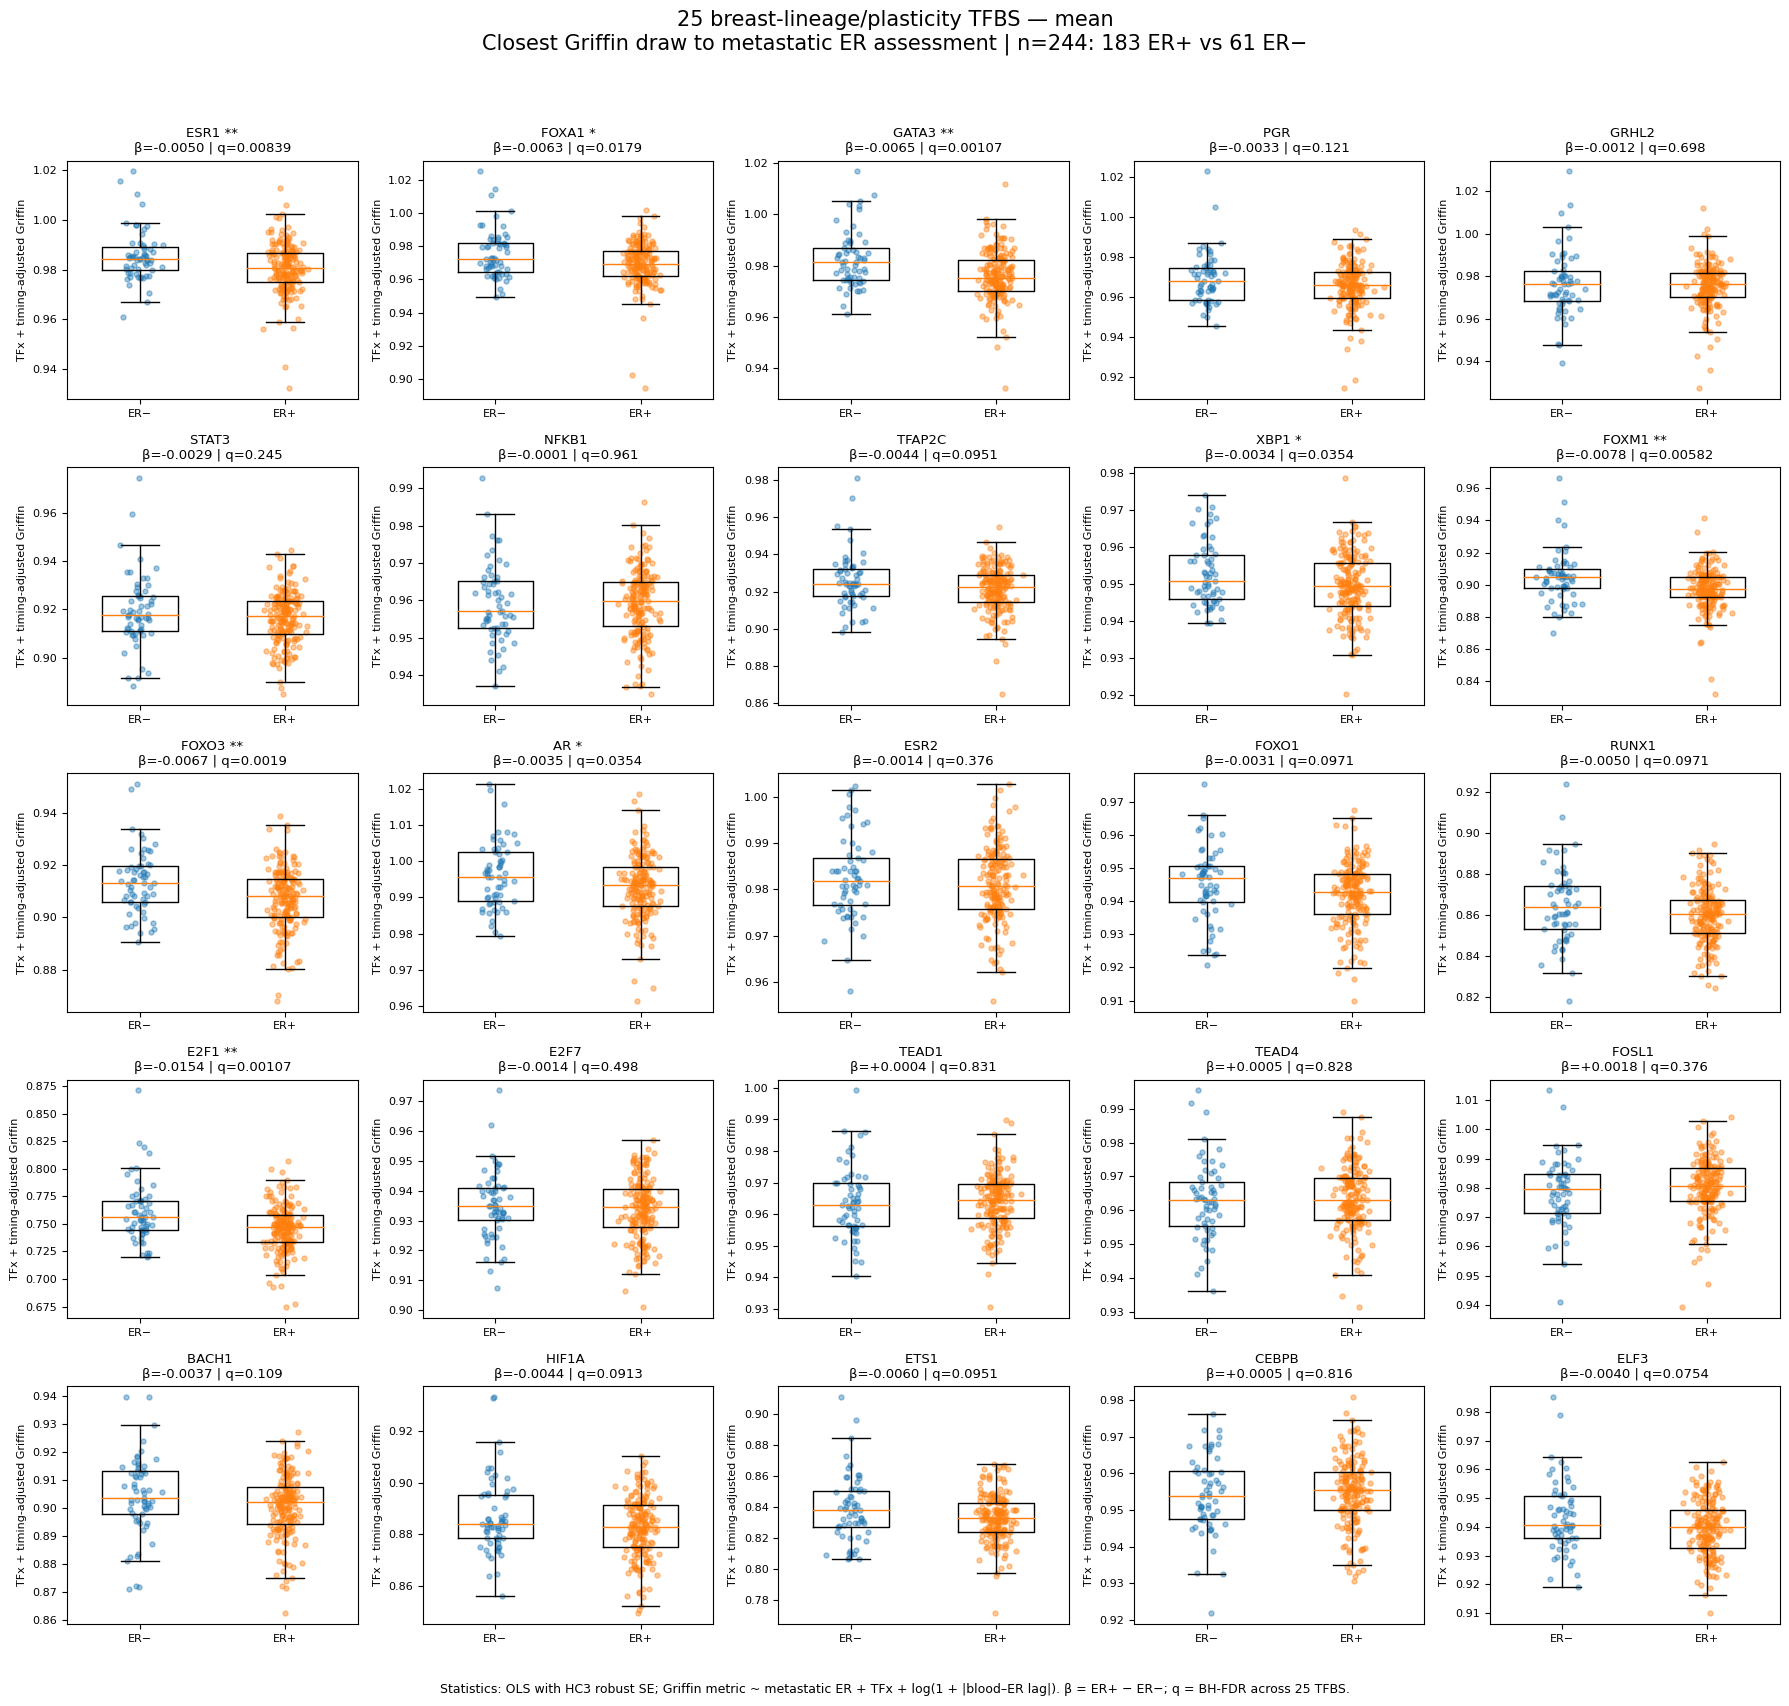

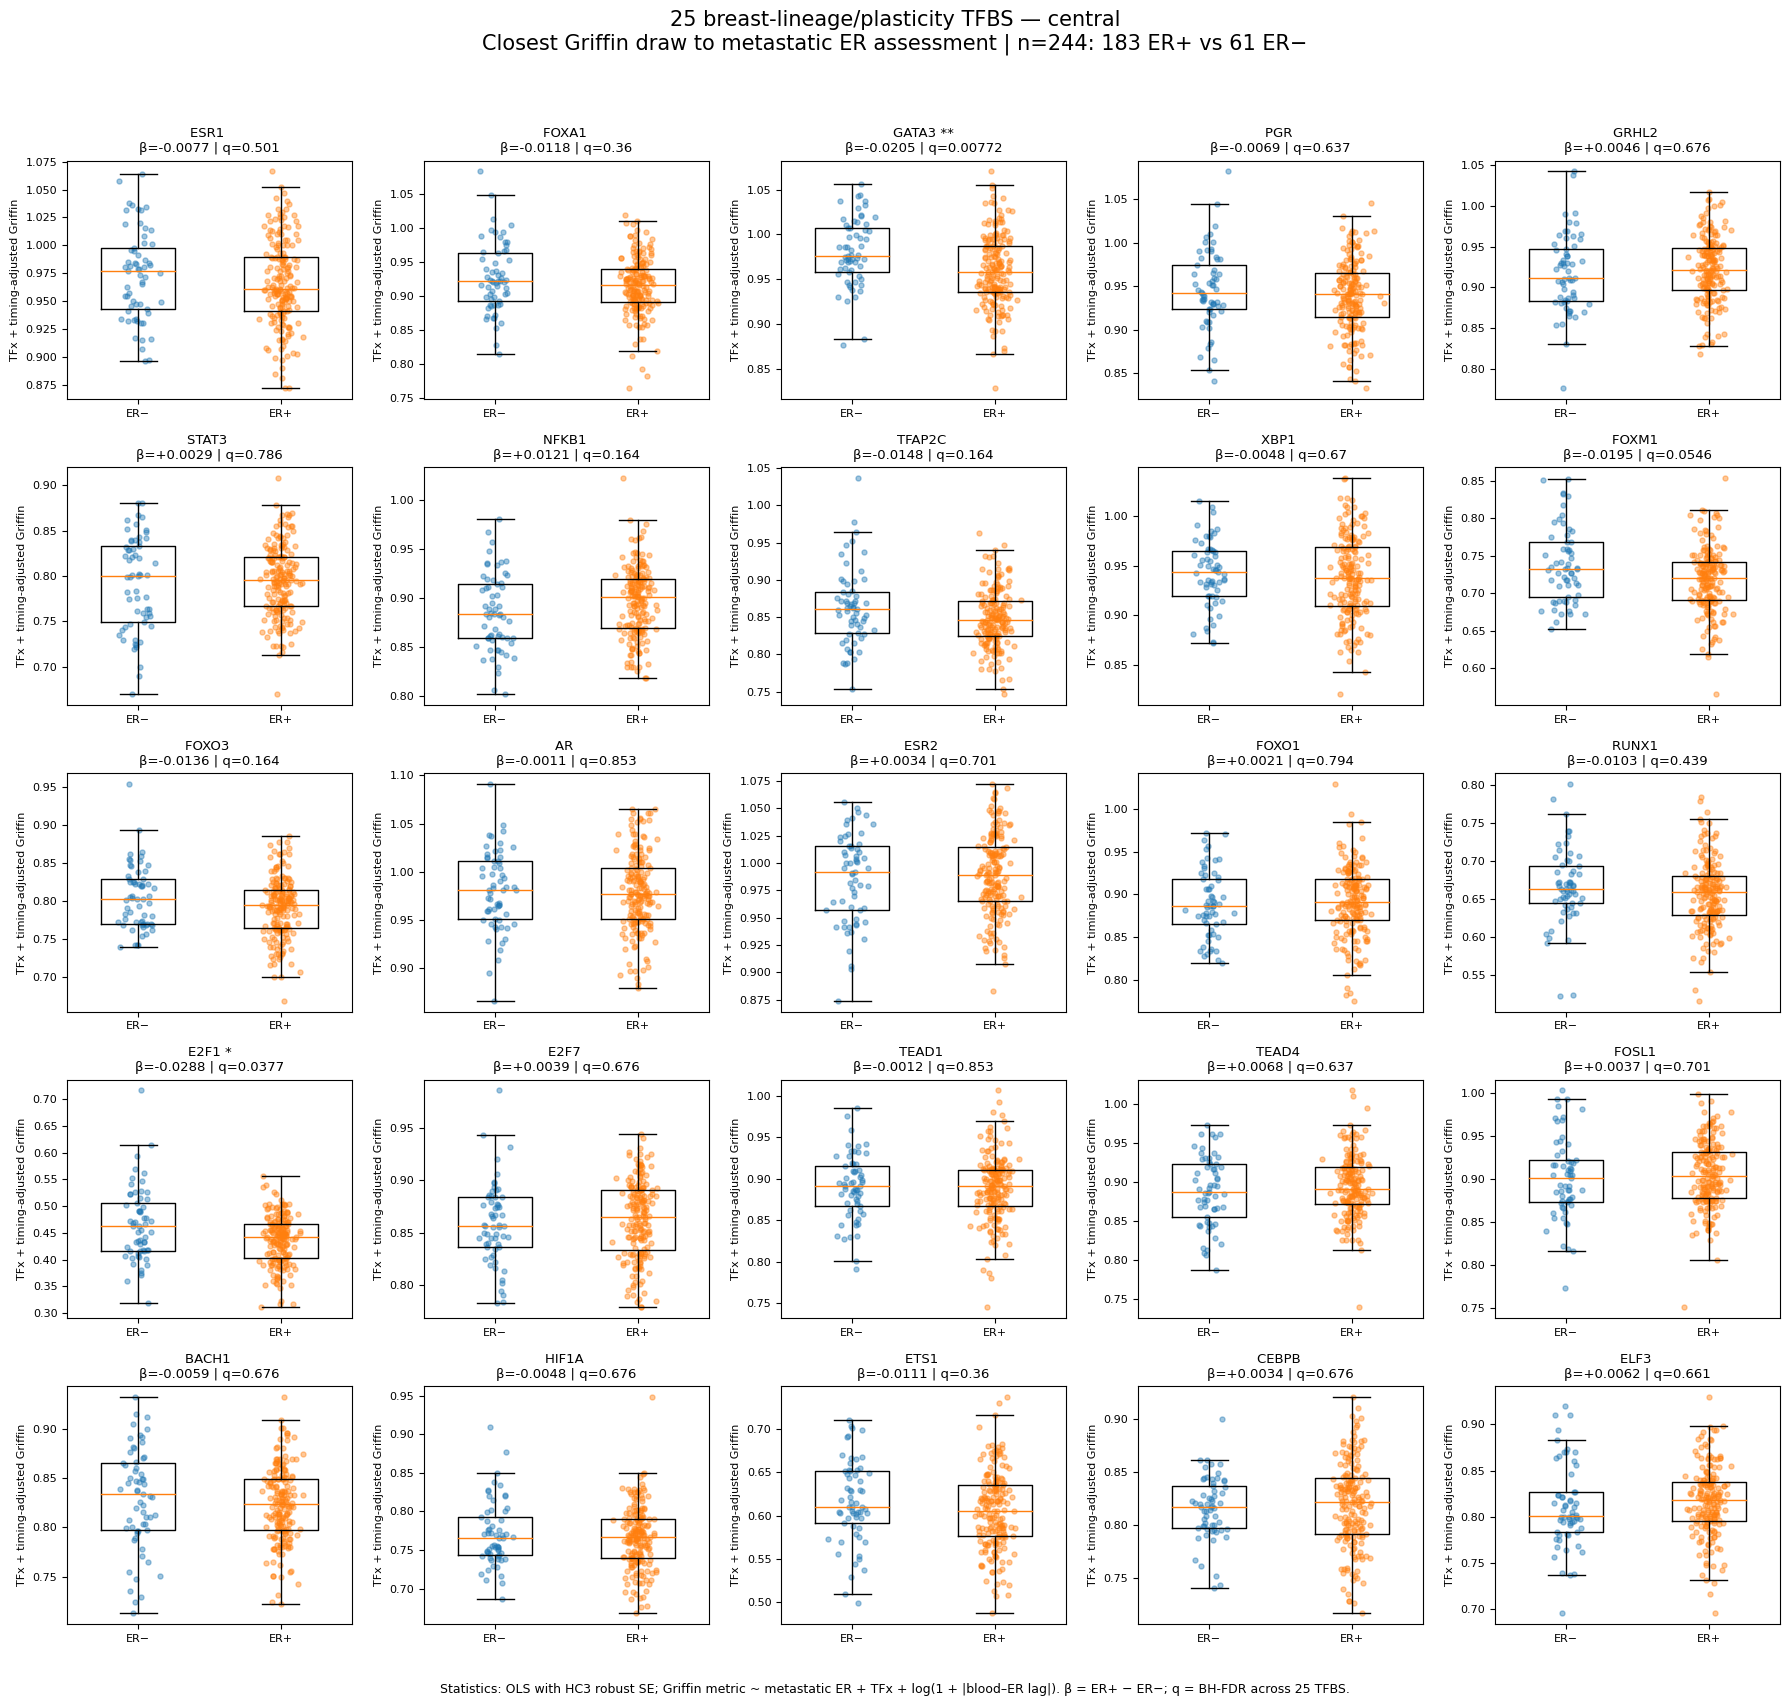

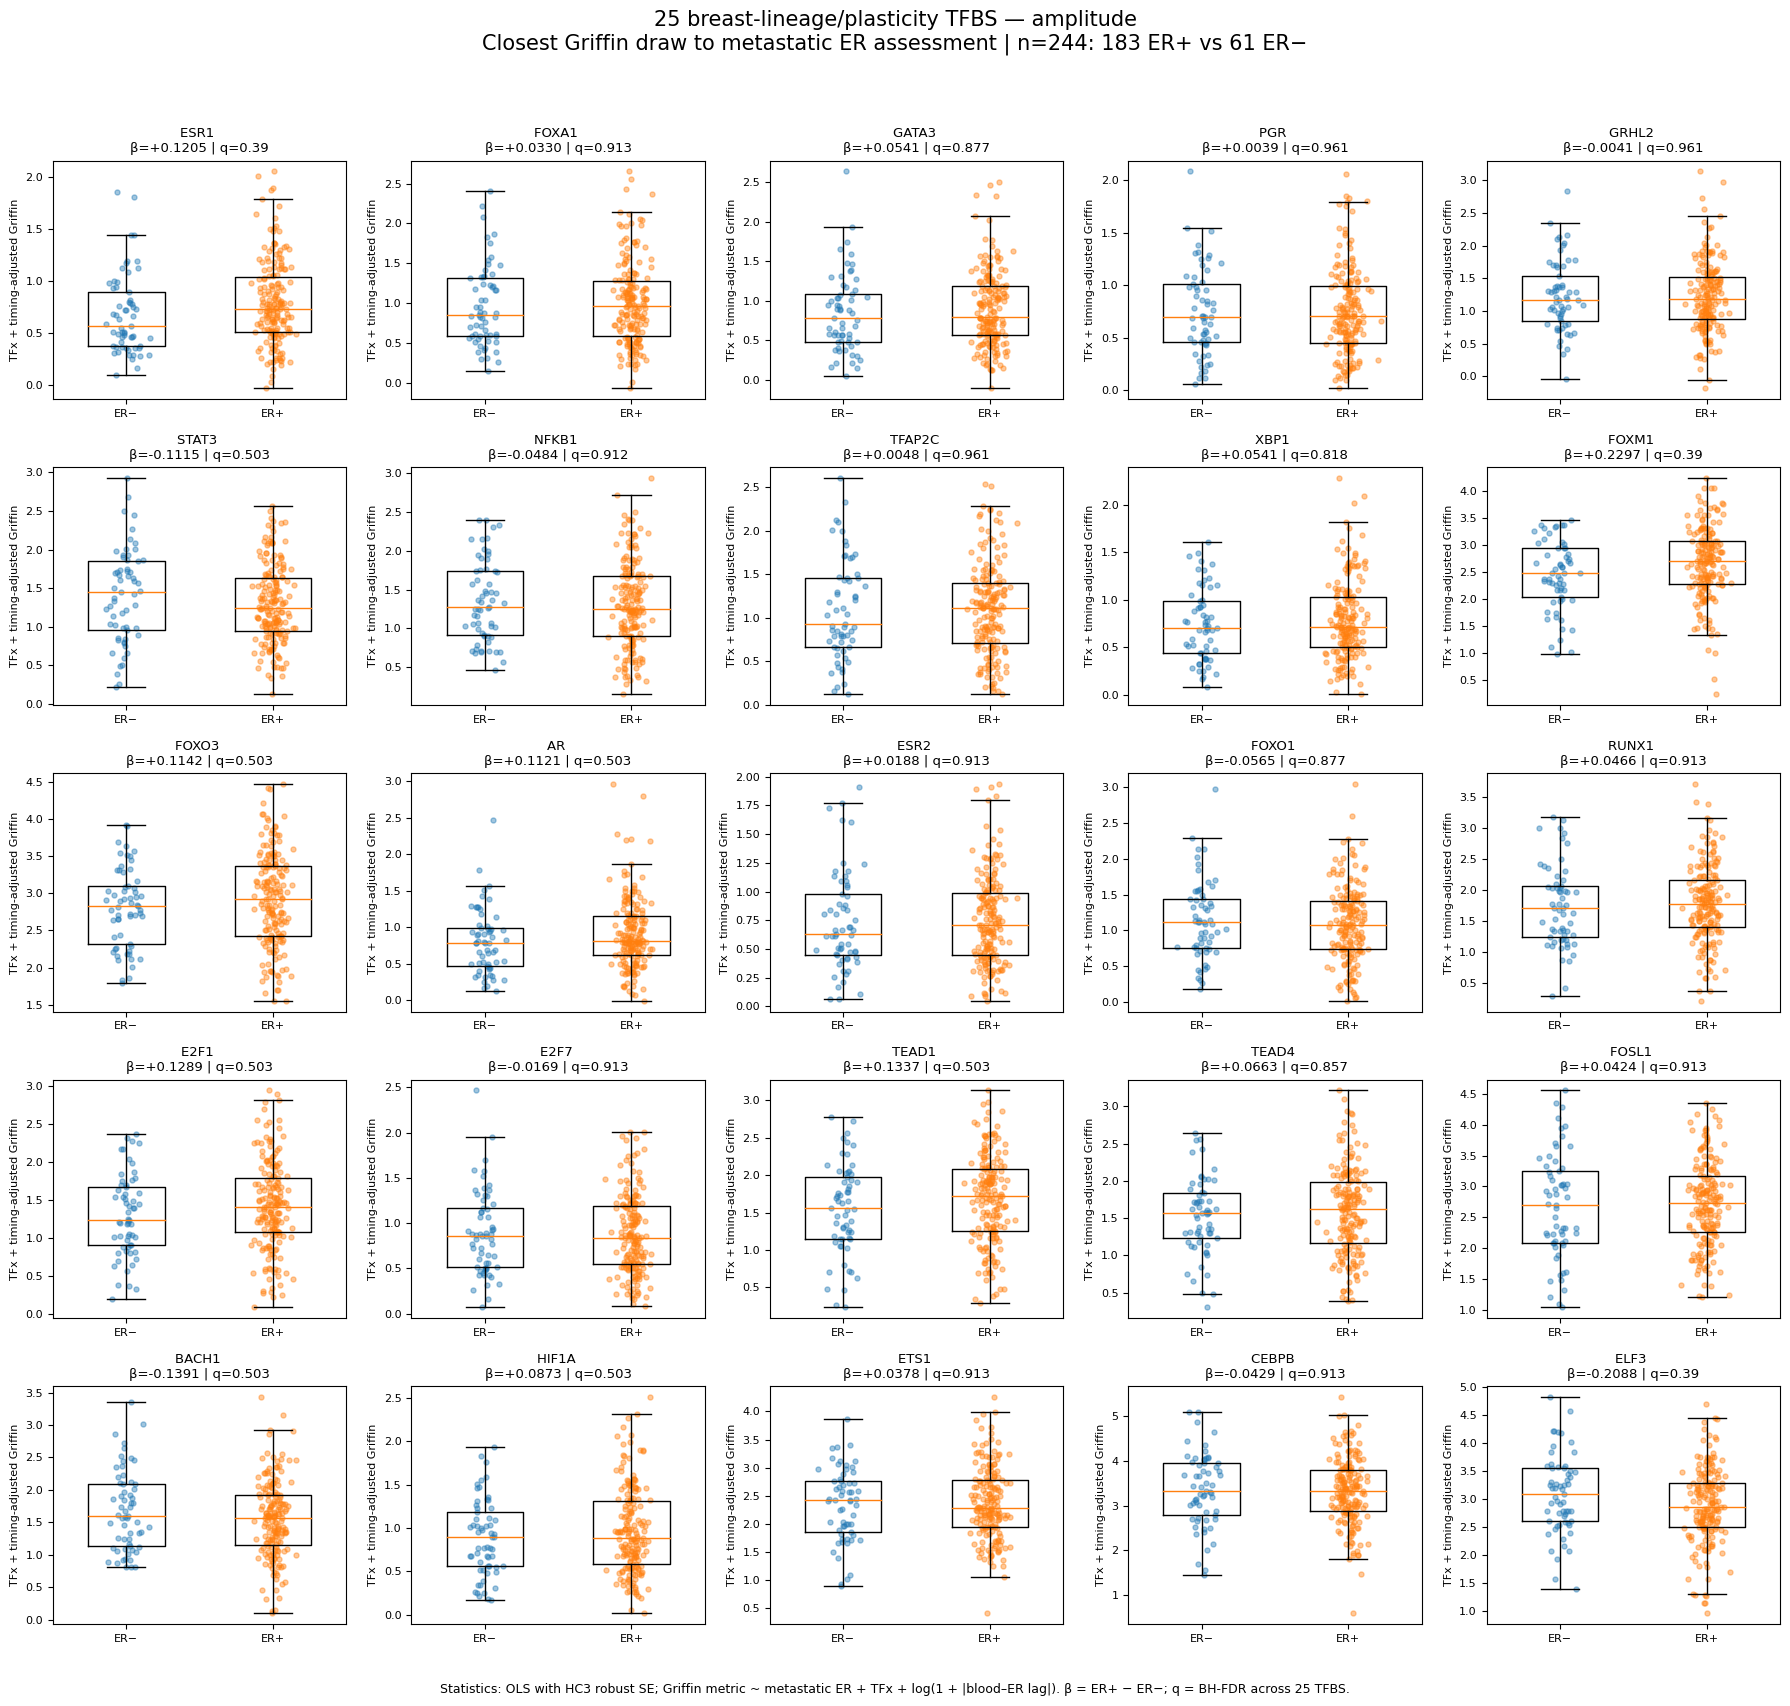

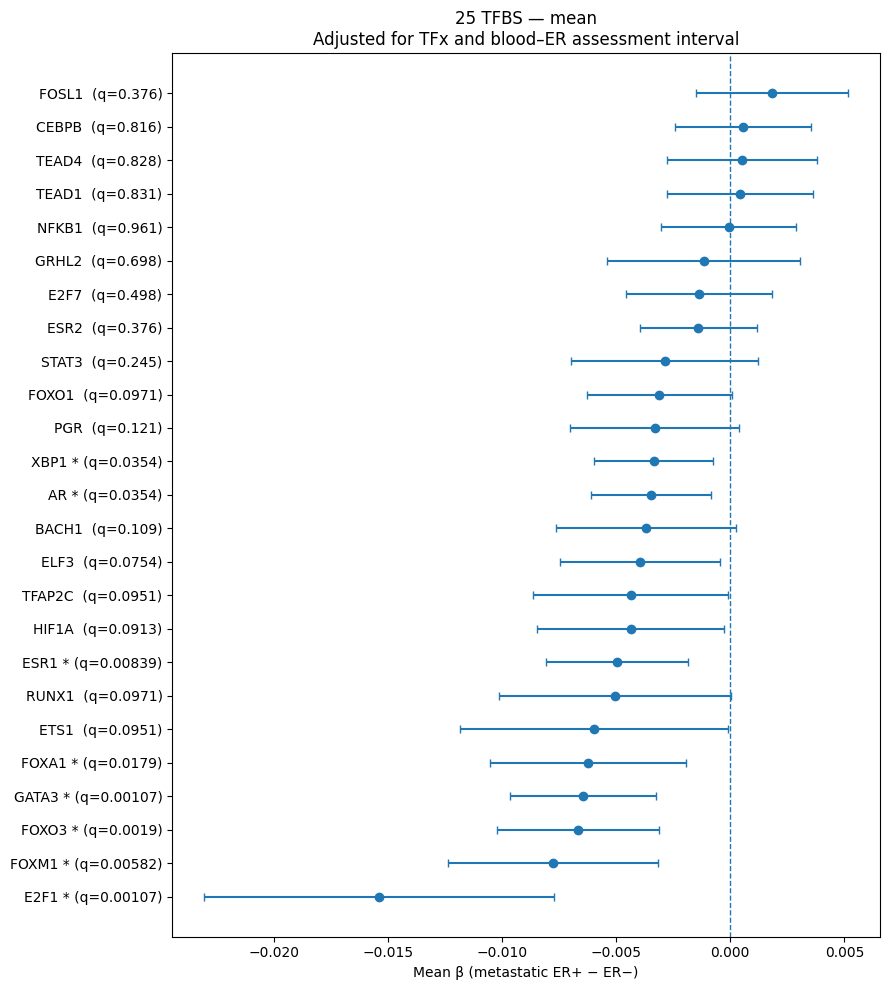

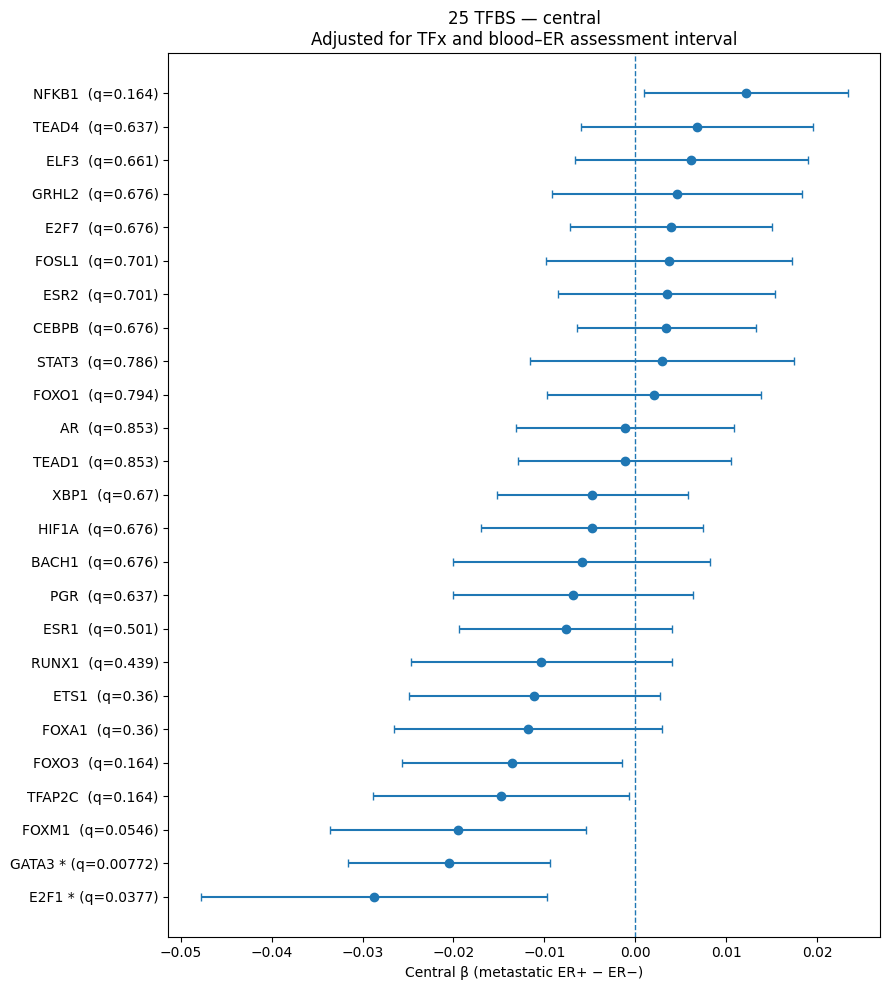

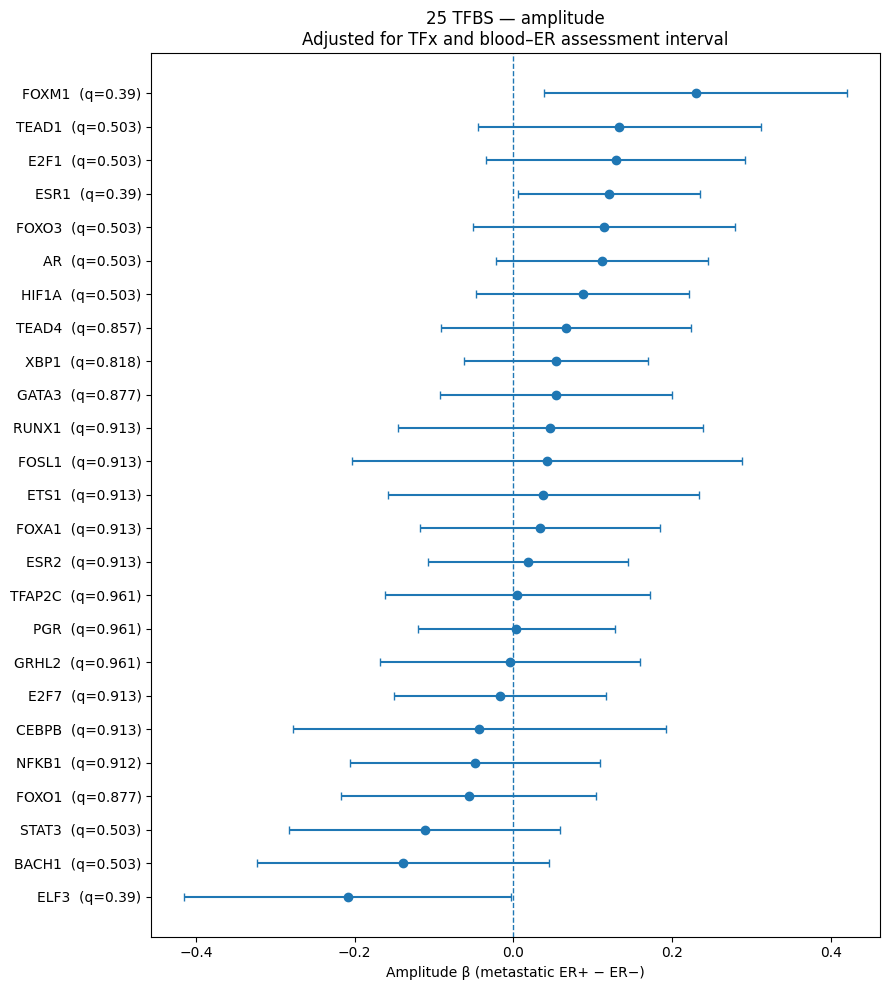


SIGNIFICANCE SUMMARY
   Metric   n  ER_positive  ER_negative  Nominal_ER_p_lt_0.05  FDR_q25_lt_0.05                      FDR_significant_TFBS
     Mean 244          183           61                    12                8 ESR1;FOXA1;GATA3;XBP1;FOXM1;FOXO3;AR;E2F1
  Central 244          183           61                     6                2                                GATA3;E2F1
Amplitude 244          183           61                     3                0                                          

ANALYSIS COMPLETE

Output directory:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Met_ER_Closest_Draw_TFBS/AllClosest_25TF_ERpos_vs_ERneg_TFx_LagAdjusted

Main results:
AllClosest_244_25TF_ER_TFx_LogLag_all3metrics.tsv

Main model:
Griffin metric ~ metastatic ER + TFx + log(1 + |blood–ER lag|)

Primary adjusted p-value:
BH_q25 within Mean, Central, or Amplitude separately


In [12]:
# ======================================================================
# AURORA
# METASTATIC ER PHENOTYPE — TIMING-ADJUSTED MODEL
#
# ALL CLOSEST-DRAW PATIENTS
#
# Expected:
#   n = 244
#   metastatic ER+ = 183
#   metastatic ER- = 61
#
# Fixed 25 breast-lineage / plasticity TFBS
#
# Griffin metrics analyzed separately:
#   1. Mean coverage
#   2. Central coverage
#   3. Amplitude
#
# Main model:
#
#   Griffin_metric ~ metastatic_ER
#                    + TFx
#                    + log(1 + absolute blood-to-ER lag)
#
# ER coding:
#   ER- = 0
#   ER+ = 1
#
# beta_ER therefore represents:
#   metastatic ER+ - metastatic ER-
#
# Statistics:
#   OLS + HC3 robust standard errors
#
# Multiple testing:
#   BH-FDR across 25 TFBS separately for each Griffin metric.
#
# Seed = 1234
# ======================================================================

# ======================================================================
# 0. IMPORTS
# ======================================================================
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import statsmodels.api as sm

from statsmodels.stats.multitest import multipletests

SEED = 1234

rng = np.random.default_rng(SEED)

# ======================================================================
# 1. PATHS
# ======================================================================

BASE_DIR = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "Griffin/Downstream/"
    "AURORA_Griffin_Met_ER_Closest_Draw_TFBS"
)

AUDIT_TSV = (
    BASE_DIR /
    "ClosestDraw_MetER_patient_audit.tsv"
)

# Updated 44-TF Griffin workbook
GRIFFIN_XLSX = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "Griffin/griffin_nucleosome_profiling/"
    "Griffin_44TF_GC_corrected_summary_by_module.xlsx"
)

OUT_DIR = (
    BASE_DIR /
    "AllClosest_25TF_ERpos_vs_ERneg_TFx_LagAdjusted"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Output directory:")
print(OUT_DIR)

# ======================================================================
# 2. 25-TF PANEL
# ======================================================================

TF25 = [
    "ESR1", "FOXA1", "GATA3", "PGR", "GRHL2",
    "STAT3", "NFKB1", "TFAP2C", "XBP1", "FOXM1", 
    "FOXO3", "AR", "ESR2", "FOXO1", "RUNX1", 
    "E2F1", "E2F7", "TEAD1", "TEAD4", "FOSL1", 
    "BACH1", "HIF1A", "ETS1", "CEBPB", "ELF3"
]

assert len(TF25) == 25

print("\nFixed TFBS panel:")
print(TF25)

# ======================================================================
# 3. THREE GRIFFIN METRIC FAMILIES
# ======================================================================

METRICS = {

    "Mean":
        "mean_coverage",

    "Central":
        "central_coverage",

    "Amplitude":
        "amplitude"
}

EXPECTED_FEATURES = [

    f"{tf}_{suffix}"

    for tf in TF25

    for suffix in METRICS.values()
]

print(
    "\nExpected Griffin measurements:",
    len(EXPECTED_FEATURES)
)

# ======================================================================
# 4. LOAD CLOSEST-DRAW PATIENT AUDIT
# ======================================================================

audit = pd.read_csv(
    AUDIT_TSV,
    sep="\t"
)

print("\n==============================================")
print("AUDIT QC")
print("==============================================")

print(
    "Rows:",
    len(audit)
)

required_columns = [

    "patient_id",
    "met_ER",
    "selected_sample",
    "TFx_pct",
    "abs_lag_days"
]

missing = [

    x for x in required_columns

    if x not in audit.columns
]

if missing:

    raise ValueError(
        f"Missing audit columns:\n{missing}"
    )

# Retain informative metastatic ER
audit = audit.loc[

    audit["met_ER"].isin(
        [
            "Positive",
            "Negative"
        ]
    )

].copy()

# numeric columns
audit["TFx_pct"] = pd.to_numeric(
    audit["TFx_pct"],
    errors="coerce"
)

audit["abs_lag_days"] = pd.to_numeric(
    audit["abs_lag_days"],
    errors="coerce"
)

# ======================================================================
# 5. CREATE TIMING COVARIATE
# ======================================================================
#
# log1p(x) = log(1 + x)
#
# Example:
#
# 0 days    -> log(1)   = 0
# 30 days   -> log(31)
# 90 days   -> log(91)
# 365 days  -> log(366)
#
# ======================================================================

audit["log_abs_lag"] = np.log1p(
    audit["abs_lag_days"]
)

print(
    "\nAbsolute lag summary:"
)

print(
    audit["abs_lag_days"].describe()
)

print(
    "\nLog absolute lag summary:"
)

print(
    audit["log_abs_lag"].describe()
)

print(
    "\nMetastatic ER distribution:"
)

print(
    audit["met_ER"].value_counts()
)

# ======================================================================
# 6. NORMALIZE SAMPLE IDs
# ======================================================================

def normalize_sample_id(x):

    if pd.isna(x):
        return np.nan

    x = str(x).strip()

    if x.startswith("AUP-"):
        x = x[4:]

    return x

audit["selected_sample"] = (
    audit["selected_sample"]
    .map(normalize_sample_id)
)

# ======================================================================
# 7. LOAD GRIFFIN WORKBOOK
# ======================================================================

griffin = pd.read_excel(

    GRIFFIN_XLSX,

    sheet_name="Breast_Lineage",

    header=[
        0,
        1
    ]
)

print("\n==============================================")
print("GRIFFIN")
print("==============================================")


print(
    "Raw Griffin shape:",
    griffin.shape
)

# ======================================================================
# 8. FLATTEN TWO-ROW HEADER
# ======================================================================

new_columns = []

for col1, col2 in griffin.columns:


    col1_str = str(col1)
    col2_str = str(col2)

    if col1_str.lower() == "sample":

        new_columns.append(
            "sample"
        )

    elif (
        pd.notna(col2)
        and
        not col2_str.startswith("Unnamed")
    ):

        new_columns.append(
            col2_str
        )

    else:

        new_columns.append(
            col1_str
        )

griffin.columns = new_columns

griffin["sample"] = (
    griffin["sample"]
    .map(normalize_sample_id)
)

# ======================================================================
# 9. VERIFY ALL 75 FEATURES
# ======================================================================

missing_features = [

    feature

    for feature in EXPECTED_FEATURES

    if feature not in griffin.columns
]

if missing_features:

    print(
        "\nMissing Griffin features:"
    )


    for x in missing_features:

        print(x)


    raise ValueError(

        f"{len(missing_features)} Griffin features missing.\n"
        "Check the 44-TF workbook."
    )

print(
    "\nAll 75 measurements found:"
)

print(
    "25 TFBS × 3 metrics"
)

# ======================================================================
# 10. MERGE CLOSEST-DRAW AUDIT WITH GRIFFIN
# ======================================================================

griffin_subset = griffin[

    [
        "sample"
    ]
    +
    EXPECTED_FEATURES

].copy()

df = audit.merge(

    griffin_subset,

    left_on="selected_sample",

    right_on="sample",

    how="left",

    validate="one_to_one"
)

# ======================================================================
# 11. FINAL ANALYSIS QC
# ======================================================================

missing_griffin = (

    df[EXPECTED_FEATURES]
    .isna()
    .any(axis=1)
)

missing_tfx = (
    df["TFx_pct"]
    .isna()
)

missing_lag = (
    df["log_abs_lag"]
    .isna()
)

print("\n==============================================")
print("MERGE QC")
print("==============================================")


print(
    "Rows after merge:",
    len(df)
)

print(
    "Missing Griffin:",
    int(missing_griffin.sum())
)

print(
    "Missing TFx:",
    int(missing_tfx.sum())
)


print(
    "Missing lag:",
    int(missing_lag.sum())
)

# Complete cases
df = df.loc[

    (~missing_griffin)
    &
    (~missing_tfx)
    &
    (~missing_lag)

].copy()


# ======================================================================
# 12. ER CODING
# ======================================================================

df["ER_positive"] = (

    df["met_ER"]
    .eq("Positive")
    .astype(int)
)


n_total = len(df)

n_pos = int(
    df["ER_positive"].sum()
)

n_neg = int(
    n_total - n_pos
)

print("\n==============================================")
print("FINAL ANALYSIS COHORT")
print("==============================================")


print(
    "Total:",
    n_total
)

print(
    "Metastatic ER+:",
    n_pos
)

print(
    "Metastatic ER-:",
    n_neg
)

if not (
    n_total == 244
    and
    n_pos == 183
    and
    n_neg == 61
):

    print(
        "\nWARNING:"
        "\nExpected 244 = 183 ER+ + 61 ER-."
    )

# ======================================================================
# 13. OPTIONAL QC:
# TIMING BY ER STATUS
# ======================================================================

print("\n==============================================")
print("TIMING BY ER STATUS")
print("==============================================")


for er_status in [
    "Positive",
    "Negative"
]:

    temp = df.loc[
        df["met_ER"]
        ==
        er_status
    ]


    print(
        f"\n{er_status}"
    )


    print(
        temp["abs_lag_days"]
        .describe()
    )

# ======================================================================
# 14. MAIN MODEL FUNCTION
# ======================================================================
#
# MODEL:
#
# Griffin metric ~ ER + TFx + log_abs_lag
#
# HC3 robust SE
#
# No z-scoring here.
#
# Each TFBS is analyzed on its original Griffin scale.
#
# ======================================================================

def fit_timing_adjusted_tfbs_model(
    data,
    feature
):


    d = data[
        [
            feature,
            "ER_positive",
            "TFx_pct",
            "log_abs_lag"
        ]
    ].dropna().copy()


    X = sm.add_constant(

        d[
            [
                "ER_positive",
                "TFx_pct",
                "log_abs_lag"
            ]
        ]
    )


    y = d[
        feature
    ]


    model = sm.OLS(
        y,
        X
    ).fit(
        cov_type="HC3"
    )


    er_ci = (

        model
        .conf_int()
        .loc[
            "ER_positive"
        ]
    )


    lag_ci = (

        model
        .conf_int()
        .loc[
            "log_abs_lag"
        ]
    )

    return {

        "n":
            len(d),

        # ----------------------------------
        # ER effect
        # ----------------------------------

        "ER_beta":
            model.params[
                "ER_positive"
            ],

        "ER_HC3_SE":
            model.bse[
                "ER_positive"
            ],

        "ER_CI95_low":
            er_ci.iloc[0],

        "ER_CI95_high":
            er_ci.iloc[1],

        "ER_p":
            model.pvalues[
                "ER_positive"
            ],

        # ----------------------------------
        # TFx
        # ----------------------------------

        "TFx_beta":
            model.params[
                "TFx_pct"
            ],

        "TFx_p":
            model.pvalues[
                "TFx_pct"
            ],

        # ----------------------------------
        # timing
        # ----------------------------------

        "log_abs_lag_beta":
            model.params[
                "log_abs_lag"
            ],

        "log_abs_lag_CI95_low":
            lag_ci.iloc[0],

        "log_abs_lag_CI95_high":
            lag_ci.iloc[1],

        "log_abs_lag_p":
            model.pvalues[
                "log_abs_lag"
            ],

        # ----------------------------------
        # model fit
        # ----------------------------------

        "R_squared":
            model.rsquared,

        "Adj_R_squared":
            model.rsquared_adj
    }

# ======================================================================
# 15. RUN ALL 25 TFBS × 3 METRICS
# ======================================================================

results = []

for metric_name, suffix in METRICS.items():

    for tf in TF25:

        feature = (
            f"{tf}_{suffix}"
        )

        stats = fit_timing_adjusted_tfbs_model(

            df,
            feature
        )

        results.append(

            {

                "TF":
                    tf,

                "Metric":
                    metric_name,

                "Feature":
                    feature,

                "n":
                    stats["n"],

                "ER_positive_n":
                    n_pos,

                "ER_negative_n":
                    n_neg,

                # ER effect
                "beta_ERpos_minus_ERneg":
                    stats["ER_beta"],

                "ER_HC3_SE":
                    stats["ER_HC3_SE"],

                "ER_CI95_low":
                    stats["ER_CI95_low"],

                "ER_CI95_high":
                    stats["ER_CI95_high"],

                "ER_p":
                    stats["ER_p"],

                # TFx
                "TFx_beta":
                    stats["TFx_beta"],

                "TFx_p":
                    stats["TFx_p"],

                # timing
                "log_abs_lag_beta":
                    stats[
                        "log_abs_lag_beta"
                    ],

                "log_abs_lag_CI95_low":
                    stats[
                        "log_abs_lag_CI95_low"
                    ],

                "log_abs_lag_CI95_high":
                    stats[
                        "log_abs_lag_CI95_high"
                    ],

                "log_abs_lag_p":
                    stats[
                        "log_abs_lag_p"
                    ],

                # model
                "R_squared":
                    stats["R_squared"],

                "Adj_R_squared":
                    stats["Adj_R_squared"]
            }
        )

results_df = pd.DataFrame(
    results
)

# ======================================================================
# 16. BH-FDR ACROSS 25 TFBS WITHIN EACH METRIC FAMILY
# ======================================================================

results_df[
    "BH_q25"
] = np.nan


for metric_name in [

    "Mean",
    "Central",
    "Amplitude"
]:

    mask = (

        results_df["Metric"]
        ==
        metric_name
    )

    pvals = (

        results_df.loc[
            mask,
            "ER_p"
        ]
        .to_numpy()
    )

    qvals = multipletests(

        pvals,

        alpha=0.05,

        method="fdr_bh"
    )[1]

    results_df.loc[

        mask,

        "BH_q25"

    ] = qvals

# ======================================================================
# 17. OPTIONAL q75 SENSITIVITY
# ======================================================================

results_df[
    "BH_q75_sensitivity"
] = multipletests(

    results_df[
        "ER_p"
    ].to_numpy(),

    alpha=0.05,

    method="fdr_bh"

)[1]

# ======================================================================
# 18. SIGNIFICANCE FLAGS
# ======================================================================

results_df[
    "FDR_significant_q25"
] = (

    results_df[
        "BH_q25"
    ]
    <
    0.05
)

results_df[
    "Nominal_ER_p_lt_0.05"
] = (

    results_df[
        "ER_p"
    ]
    <
    0.05
)

# ======================================================================
# 19. ORDER TFBS AND METRICS
# ======================================================================

results_df["TF"] = pd.Categorical(

    results_df["TF"],

    categories=TF25,

    ordered=True
)


results_df["Metric"] = pd.Categorical(

    results_df["Metric"],

    categories=[
        "Mean",
        "Central",
        "Amplitude"
    ],

    ordered=True
)


results_df = (

    results_df
    .sort_values(
        [
            "Metric",
            "TF"
        ]
    )
    .reset_index(
        drop=True
    )
)

# ======================================================================
# 20. PRINT RESULTS
# ======================================================================

pd.set_option(
    "display.max_rows",
    200
)


for metric_name in [

    "Mean",
    "Central",
    "Amplitude"
]:


    temp = results_df.loc[

        results_df["Metric"]
        ==
        metric_name

    ].copy()


    print("\n")
    print("=" * 100)

    print(
        f"{metric_name.upper()} — "
        "ER + TFx + log(1+|lag|)"
    )

    print("=" * 100)


    print(

        temp[
            [
                "TF",

                "beta_ERpos_minus_ERneg",

                "ER_CI95_low",
                "ER_CI95_high",

                "ER_p",

                "BH_q25",

                "log_abs_lag_beta",
                "log_abs_lag_p"
            ]
        ]
        .to_string(
            index=False
        )
    )

    # --------------------------------------------------
    # FDR significant
    # --------------------------------------------------

    significant = temp.loc[

        temp["BH_q25"] < 0.05

    ]


    print(
        "\nFDR significant q25 < 0.05:"
    )


    if len(significant) == 0:

        print(
            "None"
        )


    else:

        print(

            significant[
                [
                    "TF",
                    "beta_ERpos_minus_ERneg",
                    "ER_p",
                    "BH_q25"
                ]
            ]
            .to_string(
                index=False
            )
        )

# ======================================================================
# 21. SAVE FULL RESULTS
# ======================================================================

results_df.to_csv(

    OUT_DIR /
    "AllClosest_244_25TF_ER_TFx_LogLag_all3metrics.tsv",

    sep="\t",

    index=False
)


# Separate metric files
for metric_name in [

    "Mean",
    "Central",
    "Amplitude"
]:


    results_df.loc[

        results_df["Metric"]
        ==
        metric_name

    ].to_csv(

        OUT_DIR /
        f"AllClosest_244_25TF_{metric_name}_ER_TFx_LogLag.tsv",

        sep="\t",

        index=False
    )

# ======================================================================
# 22. CREATE TFx + LAG ADJUSTED VALUES FOR FACET VISUALIZATION
# ======================================================================
#
# Statistical inference:
#
#     Griffin ~ ER + TFx + log_abs_lag
#
# For visualization we remove TFx and lag components,
# while preserving the ER-related variation.
#
# Adjusted value:
#
# raw
# - beta_TFx * centered TFx
# - beta_lag * centered log lag
#
# ======================================================================

def create_covariate_adjusted_values(
    data,
    feature
):


    d = data[
        [
            feature,
            "TFx_pct",
            "log_abs_lag"
        ]
    ].copy()


    X = sm.add_constant(

        d[
            [
                "TFx_pct",
                "log_abs_lag"
            ]
        ]
    )

    model = sm.OLS(

        d[feature],
        X

    ).fit()

    beta_tfx = (

        model.params[
            "TFx_pct"
        ]
    )

    beta_lag = (

        model.params[
            "log_abs_lag"
        ]
    )

    centered_tfx = (

        d["TFx_pct"]
        -
        d["TFx_pct"].mean()
    )

    centered_lag = (

        d["log_abs_lag"]
        -
        d["log_abs_lag"].mean()
    )

    adjusted = (

        d[feature]

        -
        beta_tfx
        *
        centered_tfx

        -
        beta_lag
        *
        centered_lag
    )


    return adjusted

# ======================================================================
# 23. 25-TF FACET PLOT FUNCTION
# ======================================================================

def make_25TF_facet(
    data,
    result_table,
    metric_name,
    suffix
):

    plot_df = data.copy()

    # -------------------------------------------------
    # Create TFx + timing-adjusted plotting values
    # -------------------------------------------------

    for tf in TF25:

        feature = (

            f"{tf}_{suffix}"
        )

        adjusted_col = (

            f"{feature}_adjusted"
        )

        plot_df[
            adjusted_col
        ] = create_covariate_adjusted_values(

            plot_df,

            feature
        )

    stat_df = (

        result_table.loc[

            result_table["Metric"]
            ==
            metric_name

        ]
        .copy()
        .set_index(
            "TF"
        )
    )

    fig, axes = plt.subplots(

        5,
        5,

        figsize=(
            18,
            17
        )
    )


    axes = axes.flatten()


    local_rng = np.random.default_rng(
        SEED
    )


    for i, tf in enumerate(TF25):


        ax = axes[i]

        adjusted_col = (

            f"{tf}_{suffix}_adjusted"
        )

        er_neg = (

            plot_df.loc[

                plot_df["met_ER"]
                ==
                "Negative",

                adjusted_col
            ]
            .dropna()
            .to_numpy()
        )

        er_pos = (

            plot_df.loc[

                plot_df["met_ER"]
                ==
                "Positive",

                adjusted_col
            ]
            .dropna()
            .to_numpy()
        )

        # ----------------------------------------------
        # boxplot
        # ----------------------------------------------

        ax.boxplot(

            [
                er_neg,
                er_pos
            ],

            positions=[
                1,
                2
            ],

            widths=0.52,

            showfliers=False
        )

        # ----------------------------------------------
        # jittered patient points
        # ----------------------------------------------

        ax.scatter(

            local_rng.normal(
                1,
                0.055,
                len(er_neg)
            ),

            er_neg,

            s=13,

            alpha=0.42
        )


        ax.scatter(

            local_rng.normal(
                2,
                0.055,
                len(er_pos)
            ),

            er_pos,

            s=13,

            alpha=0.42
        )

        # ----------------------------------------------
        # model statistics
        # ----------------------------------------------

        r = stat_df.loc[
            tf
        ]


        beta = (

            r[
                "beta_ERpos_minus_ERneg"
            ]
        )


        p = (

            r[
                "ER_p"
            ]
        )


        q = (

            r[
                "BH_q25"
            ]
        )

        if q < 0.001:

            star = "***"

        elif q < 0.01:

            star = "**"

        elif q < 0.05:

            star = "*"

        else:

            star = ""


        ax.set_title(

            f"{tf} {star}\n"
            f"β={beta:+.4f} | q={q:.3g}",

            fontsize=9.5
        )

        ax.set_xticks(

            [
                1,
                2
            ],

            [
                "ER−",
                "ER+"
            ]
        )

        ax.set_ylabel(

            "TFx + timing-adjusted Griffin",

            fontsize=8
        )


        ax.tick_params(

            axis="both",

            labelsize=8
        )

    # -------------------------------------------------
    # Main title
    # -------------------------------------------------

    fig.suptitle(

        f"25 breast-lineage/plasticity TFBS — "
        f"{metric_name.lower()}\n"
        f"Closest Griffin draw to metastatic ER assessment | "
        f"n={n_total}: {n_pos} ER+ vs {n_neg} ER−",

        fontsize=15,

        y=0.995
    )

    # -------------------------------------------------
    # Figure footnote
    # -------------------------------------------------

    fig.text(

        0.5,

        0.005,

        "Statistics: OLS with HC3 robust SE; "
        "Griffin metric ~ metastatic ER + TFx + log(1 + |blood–ER lag|). "
        "β = ER+ − ER−; q = BH-FDR across 25 TFBS.",

        ha="center",

        fontsize=9
    )

    plt.tight_layout(

        rect=[
            0,
            0.025,
            1,
            0.97
        ]
    )

    # -------------------------------------------------
    # Save
    # -------------------------------------------------

    fig.savefig(

        OUT_DIR /
        f"Figure_AllClosest_244_25TF_{metric_name}_"
        "ER_TFx_LogLag_facet.png",

        dpi=600,

        bbox_inches="tight"
    )

    fig.savefig(

        OUT_DIR /
        f"Figure_AllClosest_244_25TF_{metric_name}_"
        "ER_TFx_LogLag_facet.pdf",

        bbox_inches="tight"
    )


    plt.show()

    plt.close(fig)

# ======================================================================
# 24. GENERATE THREE FACET PLOTS
# ======================================================================

make_25TF_facet(

    df,
    results_df,

    metric_name="Mean",

    suffix="mean_coverage"
)

make_25TF_facet(

    df,
    results_df,

    metric_name="Central",

    suffix="central_coverage"
)

make_25TF_facet(

    df,
    results_df,

    metric_name="Amplitude",

    suffix="amplitude"
)

# ======================================================================
# 25. FOREST PLOT FUNCTION
# ======================================================================

def make_forest_plot(
    result_table,
    metric_name
):


    temp = result_table.loc[

        result_table["Metric"]
        ==
        metric_name

    ].copy()


    temp = temp.sort_values(

        "beta_ERpos_minus_ERneg"
    )


    beta = (

        temp[
            "beta_ERpos_minus_ERneg"
        ]
        .to_numpy()
    )


    low = (

        temp[
            "ER_CI95_low"
        ]
        .to_numpy()
    )


    high = (

        temp[
            "ER_CI95_high"
        ]
        .to_numpy()
    )


    y = np.arange(
        len(temp)
    )


    fig, ax = plt.subplots(

        figsize=(
            9,
            10
        )
    )


    ax.errorbar(

        beta,

        y,

        xerr=[
            beta - low,
            high - beta
        ],

        fmt="o",

        markersize=6,

        capsize=3
    )


    ax.axvline(

        0,

        linestyle="--",

        linewidth=1
    )


    labels = []


    for _, row in temp.iterrows():


        if row["BH_q25"] < 0.05:

            symbol = "*"

        else:

            symbol = ""


        labels.append(

            f"{row['TF']} {symbol} "
            f"(q={row['BH_q25']:.3g})"
        )

    ax.set_yticks(

        y,

        labels
    )

    ax.set_xlabel(

        f"{metric_name} β "
        "(metastatic ER+ − ER−)"
    )

    ax.set_title(

        f"25 TFBS — {metric_name.lower()}\n"
        "Adjusted for TFx and blood–ER assessment interval"
    )

    plt.tight_layout()

    fig.savefig(

        OUT_DIR /
        f"Figure_AllClosest_244_25TF_{metric_name}_"
        "ER_TFx_LogLag_forest.png",

        dpi=600,

        bbox_inches="tight"
    )

    fig.savefig(

        OUT_DIR /
        f"Figure_AllClosest_244_25TF_{metric_name}_"
        "ER_TFx_LogLag_forest.pdf",

        bbox_inches="tight"
    )

    plt.show()

    plt.close(fig)

# ======================================================================
# 26. GENERATE THREE FOREST PLOTS
# ======================================================================

for metric_name in [

    "Mean",
    "Central",
    "Amplitude"
]:

    make_forest_plot(

        results_df,

        metric_name
    )

# ======================================================================
# 27. SIGNIFICANCE SUMMARY
# ======================================================================

summary_records = []


for metric_name in [

    "Mean",
    "Central",
    "Amplitude"
]:

    temp = results_df.loc[

        results_df["Metric"]
        ==
        metric_name

    ]

    significant = temp.loc[

        temp["BH_q25"]
        <
        0.05

    ]

    summary_records.append(

        {

            "Metric":
                metric_name,

            "n":
                n_total,

            "ER_positive":
                n_pos,

            "ER_negative":
                n_neg,

            "Nominal_ER_p_lt_0.05":
                int(
                    (
                        temp["ER_p"]
                        <
                        0.05
                    )
                    .sum()
                ),

            "FDR_q25_lt_0.05":
                len(
                    significant
                ),

            "FDR_significant_TFBS":
                ";".join(
                    significant[
                        "TF"
                    ]
                    .astype(str)
                    .tolist()
                )
        }
    )

summary_df = pd.DataFrame(

    summary_records
)

print("\n==============================================")
print("SIGNIFICANCE SUMMARY")
print("==============================================")


print(

    summary_df.to_string(
        index=False
    )
)


summary_df.to_csv(

    OUT_DIR /
    "AllClosest_244_25TF_ER_TFx_LogLag_significance_summary.tsv",

    sep="\t",

    index=False
)

# ======================================================================
# 28. SAVE ANALYSIS DATASET
# ======================================================================

df.to_csv(

    OUT_DIR /
    "AllClosest_244_25TF_ER_TFx_LogLag_analysis_dataset.tsv",

    sep="\t",

    index=False
)

# ======================================================================
# 29. DONE
# ======================================================================

print("\n==============================================")
print("ANALYSIS COMPLETE")
print("==============================================")

print(
    "\nOutput directory:"
)

print(
    OUT_DIR
)


print(
    "\nMain results:"
)

print(
    "AllClosest_244_25TF_ER_TFx_LogLag_all3metrics.tsv"
)

print(
    "\nMain model:"
)

print(
    "Griffin metric ~ metastatic ER + TFx + log(1 + |blood–ER lag|)"
)

print(
    "\nPrimary adjusted p-value:"
)

print(
    "BH_q25 within Mean, Central, or Amplitude separately"
)

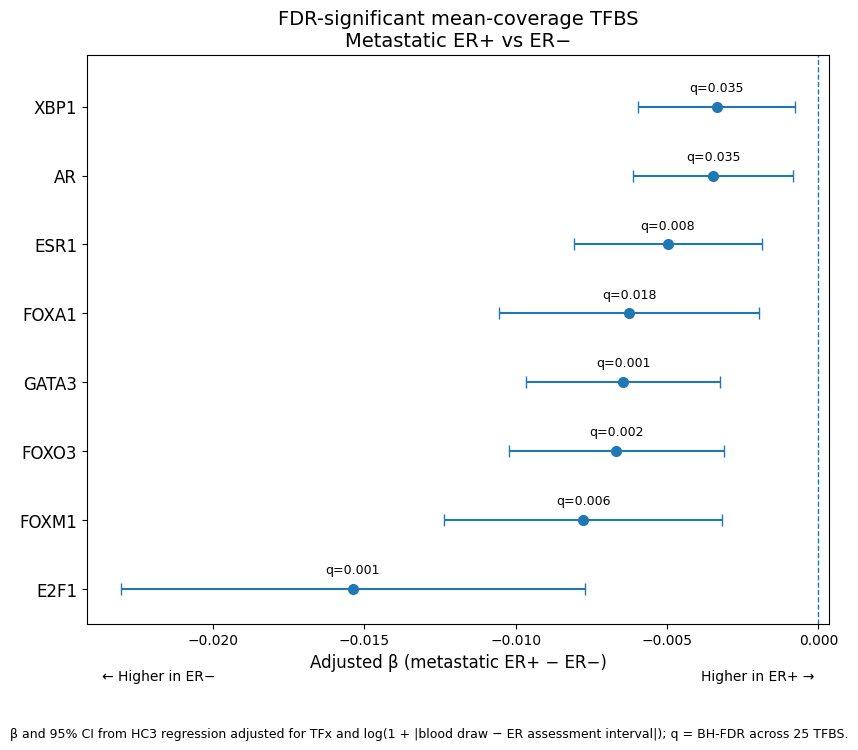

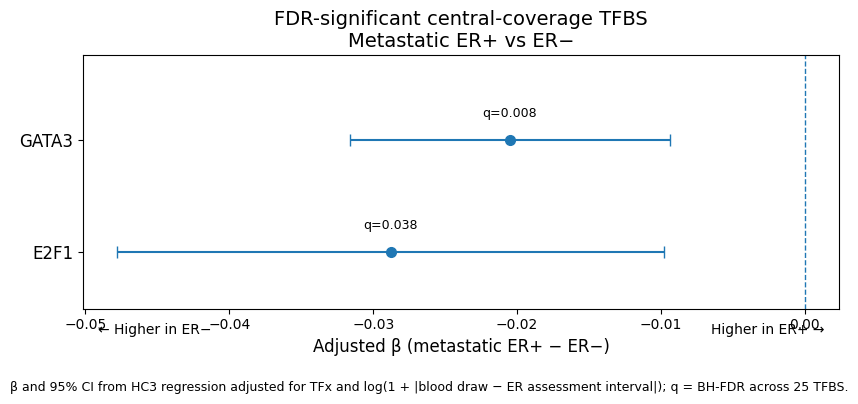

In [15]:
# ======================================================================
# FOREST PLOT — FDR-SIGNIFICANT TFBS ONLY
#
# Y-axis: TFBS name only
# q-value: displayed directly above each CI line
#
# Model:
# Griffin ~ metastatic ER + TFx + log(1 + |blood-ER lag|)
#
# beta = metastatic ER+ - ER-
# ======================================================================
def make_significant_forest_plot(
    result_table,
    metric_name,
    out_dir
):

    # --------------------------------------------------------------
    # Keep only FDR-significant TFBS
    # --------------------------------------------------------------

    temp = result_table.loc[
        (result_table["Metric"] == metric_name)
        &
        (result_table["BH_q25"] < 0.05)
    ].copy()

    if len(temp) == 0:

        print(
            f"{metric_name}: No TFBS significant at BH_q25 < 0.05."
        )

        return

    # --------------------------------------------------------------
    # Sort by effect size
    # --------------------------------------------------------------

    temp = temp.sort_values(
        "beta_ERpos_minus_ERneg",
        ascending=True
    ).reset_index(drop=True)


    beta = temp[
        "beta_ERpos_minus_ERneg"
    ].to_numpy()

    low = temp[
        "ER_CI95_low"
    ].to_numpy()

    high = temp[
        "ER_CI95_high"
    ].to_numpy()

    qvals = temp[
        "BH_q25"
    ].to_numpy()

    tf_names = temp[
        "TF"
    ].astype(str).to_numpy()

    y = np.arange(
        len(temp)
    )

    # --------------------------------------------------------------
    # Figure
    # --------------------------------------------------------------

    fig_height = max(
        4,
        0.75 * len(temp) + 1.5
    )


    fig, ax = plt.subplots(
        figsize=(8.5, fig_height)
    )

    # --------------------------------------------------------------
    # Effect estimates + 95% CI
    # --------------------------------------------------------------

    ax.errorbar(

        beta,
        y,

        xerr=[
            beta - low,
            high - beta
        ],

        fmt="o",

        markersize=7,

        capsize=4,

        linewidth=1.5
    )

    # --------------------------------------------------------------
    # Null line
    # --------------------------------------------------------------

    ax.axvline(
        0,
        linestyle="--",
        linewidth=1
    )

    # --------------------------------------------------------------
    # Y-axis = TF names only
    # --------------------------------------------------------------

    ax.set_yticks(
        y
    )

    ax.set_yticklabels(
        tf_names,
        fontsize=12
    )

    # --------------------------------------------------------------
    # Add q-value ABOVE each confidence interval
    # --------------------------------------------------------------

    # Small vertical offset
    q_y_offset = 0.18

    for i in range(len(temp)):

        # Put q approximately at center of CI
        x_position = (
            low[i] + high[i]
        ) / 2

        # Formatting
        if qvals[i] < 0.001:

            q_text = f"q={qvals[i]:.1e}"

        else:

            q_text = f"q={qvals[i]:.3f}"

        ax.text(

            x_position,
            y[i] + q_y_offset,

            q_text,

            ha="center",
            va="bottom",

            fontsize=9
        )

    # --------------------------------------------------------------
    # Axis labels
    # --------------------------------------------------------------

    ax.set_xlabel(
        "Adjusted β (metastatic ER+ − ER−)",
        fontsize=12
    )

    ax.set_ylabel(
        "",
        fontsize=12
    )

    # --------------------------------------------------------------
    # Title
    # --------------------------------------------------------------

    ax.set_title(

        f"FDR-significant {metric_name.lower()}-coverage TFBS\n"
        "Metastatic ER+ vs ER−",

        fontsize=14
    )

    # --------------------------------------------------------------
    # Direction labels
    # --------------------------------------------------------------

    ax.text(

        0.02,
        -0.10,

        "← Higher in ER−",

        transform=ax.transAxes,

        ha="left",

        fontsize=10
    )

    ax.text(

        0.98,
        -0.10,

        "Higher in ER+ →",

        transform=ax.transAxes,

        ha="right",

        fontsize=10
    )

    # --------------------------------------------------------------
    # Footnote
    # --------------------------------------------------------------

    fig.text(

        0.5,
        0.01,

        "β and 95% CI from HC3 regression adjusted for TFx and "
        "log(1 + |blood draw − ER assessment interval|); "
        "q = BH-FDR across 25 TFBS.",

        ha="center",

        fontsize=9
    )

    # --------------------------------------------------------------
    # Add a little vertical spacing
    # --------------------------------------------------------------

    ax.set_ylim(
        -0.5,
        len(temp) - 0.25
    )

    plt.tight_layout(
        rect=[
            0,
            0.06,
            1,
            1
        ]
    )

    # --------------------------------------------------------------
    # Save
    # --------------------------------------------------------------

    png_file = (
        out_dir /
        f"Figure_Significant_25TF_{metric_name}_"
        "ER_TFx_LogLag_forest.png"
    )

    pdf_file = (
        out_dir /
        f"Figure_Significant_25TF_{metric_name}_"
        "ER_TFx_LogLag_forest.pdf"
    )

    fig.savefig(
        png_file,
        dpi=600,
        bbox_inches="tight"
    )

    fig.savefig(
        pdf_file,
        bbox_inches="tight"
    )

    plt.show()

    plt.close(fig)

# ======================================================================
# MAIN FOREST — MEAN
# ======================================================================

make_significant_forest_plot(
    results_df,
    metric_name="Mean",
    out_dir=OUT_DIR
)

# ======================================================================
# SECONDARY FOREST — CENTRAL
# ======================================================================

make_significant_forest_plot(
    results_df,
    metric_name="Central",
    out_dir=OUT_DIR
)

In [19]:
# ======================================================================
# AURORA
# GENERATE CLOSEST-DRAW METASTATIC ER AUDIT
#
# Purpose:
#   For every Griffin patient with an informative metastatic ER assessment:
#
#   1. Identify FIRST informative metastatic ER assessment
#      (Met_Diagnosis + ER Positive/Negative)
#
#   2. Consider ALL available Griffin blood draws
#      (NOT restricted to NB1)
#
#   3. Select the blood draw closest to the ER assessment:
#
#          min |draw_day - ER_assessment_day|
#
#   4. Calculate:
#        signed lag
#        absolute lag
#        ±30 / ±60 / ±90 / ±180 / ±365 day flags
#
# Expected final cohort:
#   n = 244
#   ER+ = 183
#   ER- = 61
#
# Seed = 1234
# ======================================================================

# ======================================================================
# 0. IMPORTS
# ======================================================================

from pathlib import Path

import re
import numpy as np
import pandas as pd


SEED = 1234

# ======================================================================
# 1. PATHS
# ======================================================================

AURORA_ROOT = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA"
)

CLINICAL_XLSX = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/AUP_ClinicalData_20260609.xlsx"
)

METASHEET_XLSX = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/Metasheet_Analysis.with_Histology_Receptor_status.Earliest_Met_Diagnosis.xlsx"
)

# ----------------------------------------------------------------------
# Griffin workbook
# ----------------------------------------------------------------------

GRIFFIN_XLSX = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "Griffin/griffin_nucleosome_profiling/"
    "Griffin_44TF_GC_corrected_summary_by_module.xlsx"
)

# ----------------------------------------------------------------------
# Output
# ----------------------------------------------------------------------

BASE_DIR = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "Griffin/Downstream/"
    "AURORA_Griffin_Met_ER_Closest_Draw_TFBS"
)


BASE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


CLOSEST_AUDIT = (
    BASE_DIR /
    "ClosestDraw_MetER_patient_audit.tsv"
)

print("Output directory:")
print(BASE_DIR)


# ======================================================================
# 2. HELPERS
# ======================================================================

def normalize_patient_id(x):
    """
    Convert patient IDs to clean strings.
    Handles Excel IDs such as 2.0 -> 2.
    """

    if pd.isna(x):
        return np.nan

    x = str(x).strip()

    if x.endswith(".0"):

        try:
            float(x)
            x = x[:-2]

        except ValueError:
            pass

    return x

def normalize_sample_id(x):
    """
    Standardize sample names.

    Examples:
        AUP-AMCZ-NB1 -> AMCZ-NB1
        AMCZ-NB1     -> AMCZ-NB1
    """

    if pd.isna(x):
        return np.nan

    x = str(x).strip()

    x = re.sub(
        r"^AUP-",
        "",
        x
    )

    return x

def get_nb_number(sample):
    """
    Extract NB number from sample.

    AMCZ-NB1 -> 1
    ABCD-NB4 -> 4
    """

    if pd.isna(sample):
        return np.nan

    match = re.search(
        r"-NB(\d+)",
        str(sample)
    )

    if match:

        return int(
            match.group(1)
        )

    return np.nan

# ======================================================================
# 3. CHECK FILES
# ======================================================================

for f in [
    CLINICAL_XLSX,
    METASHEET_XLSX,
    GRIFFIN_XLSX
]:

    if not f.exists():

        raise FileNotFoundError(
            f"\nFile not found:\n{f}"
        )

# ======================================================================
# 4. LOAD CLINICAL DATA
# ======================================================================

clinical = pd.read_excel(

    CLINICAL_XLSX,

    sheet_name="AUP_ClinicalData_20260609.NO.DA"
)

print("\n==============================================")
print("CLINICAL DATA")
print("==============================================")

print(
    "Clinical rows:",
    len(clinical)
)

clinical[
    "patient_id_norm"
] = clinical[
    "patient_id"
].map(
    normalize_patient_id
)

clinical[
    "Days_From_Primary_Diagnosis"
] = pd.to_numeric(

    clinical[
        "Days_From_Primary_Diagnosis"
    ],

    errors="coerce"
)

print(
    "Unique clinical patients:",
    clinical[
        "patient_id_norm"
    ].nunique()
)

# ======================================================================
# 5. LOAD METASHEET
# ======================================================================

metasheet = pd.read_excel(

    METASHEET_XLSX,

    sheet_name="Sheet1"
)

print("\n==============================================")
print("METASHEET")
print("==============================================")

print(
    "Metasheet rows:",
    len(metasheet)
)

metasheet[
    "patient_id_norm"
] = metasheet[
    "Patient_id"
].map(
    normalize_patient_id
)


metasheet[
    "sample_norm"
] = metasheet[
    "Collaborator_sample_id"
].map(
    normalize_sample_id
)

# Tumor fraction is stored as fraction in metasheet:
# 0.10 = 10%

metasheet[
    "TFx_pct"
] = (

    pd.to_numeric(
        metasheet[
            "Tumor_Fraction"
        ],
        errors="coerce"
    )
    *
    100
)

print(
    "Unique metasheet samples:",
    metasheet[
        "sample_norm"
    ].nunique()
)

print(
    "Unique metasheet patients:",
    metasheet[
        "patient_id_norm"
    ].nunique()
)

# ======================================================================
# 6. LOAD GRIFFIN SAMPLE UNIVERSE
# ======================================================================
#
# We only need the sample column here.
# Breast_Lineage contains all Griffin samples.
# ======================================================================

griffin = pd.read_excel(

    GRIFFIN_XLSX,

    sheet_name="Breast_Lineage",

    header=[
        0,
        1
    ]
)

griffin_samples = (

    griffin.iloc[
        :,
        0
    ]
    .map(
        normalize_sample_id
    )
)

griffin_sample_set = set(

    griffin_samples
    .dropna()
)

print("\n==============================================")
print("GRIFFIN")
print("==============================================")


print(
    "Griffin unique samples:",
    len(
        griffin_sample_set
    )
)

# ======================================================================
# 7. IDENTIFY INFORMATIVE METASTATIC ER ROWS
# ======================================================================
#
# Definition:
#
#   Category == Met_Diagnosis
#
# AND
#
#   ER_Status in Positive / Negative
#
# ======================================================================

met_er_rows = clinical.loc[

    (
        clinical[
            "Category"
        ]
        ==
        "Met_Diagnosis"
    )

    &

    (
        clinical[
            "ER_Status"
        ]
        .isin(
            [
                "Positive",
                "Negative"
            ]
        )
    )

].copy()

met_er_rows[
    "ER_assessment_day"
] = pd.to_numeric(

    met_er_rows[
        "Days_From_Primary_Diagnosis"
    ],

    errors="coerce"
)

met_er_rows = met_er_rows.dropna(

    subset=[
        "patient_id_norm",
        "ER_assessment_day"
    ]
)

print("\n==============================================")
print("INFORMATIVE METASTATIC ER")
print("==============================================")


print(
    "Informative metastatic ER rows:",
    len(
        met_er_rows
    )
)

print(
    "Patients with >=1 informative metastatic ER:",
    met_er_rows[
        "patient_id_norm"
    ].nunique()
)

# ======================================================================
# 8. DEFINE FIRST INFORMATIVE METASTATIC ER ASSESSMENT
# ======================================================================
#
# For every patient:
#
#   earliest day having Positive/Negative metastatic ER.
#
# If multiple metastatic sites occur on that exact day:
#   - combine sites
#   - check ER consistency
#
# If Positive AND Negative occur on the same first informative day:
#   flag as ambiguous.
# ======================================================================

anchor_records = []

ambiguous_records = []

for patient_id, g in met_er_rows.groupby(
    "patient_id_norm"
):

    # First informative metastatic ER day
    first_day = (
        g[
            "ER_assessment_day"
        ].min()
    )

    same_day = g.loc[

        g[
            "ER_assessment_day"
        ]
        ==
        first_day

    ].copy()

    statuses = sorted(

        same_day[
            "ER_Status"
        ]
        .dropna()
        .unique()
    )

    sites = sorted(

        {

            str(x).strip()

            for x in same_day[
                "Tissue_Site"
            ].dropna()

            if (
                str(x).strip()
                and
                str(x).strip().lower()
                !=
                "nan"
            )
        }
    )


    site_string = "; ".join(
        sites
    )

    # --------------------------------------------------------------
    # Unique ER status on first informative day
    # --------------------------------------------------------------

    if len(statuses) == 1:


        anchor_records.append({

            "patient_id_norm":
                patient_id,

            "met_ER":
                statuses[0],

            "ER_assessment_day":
                first_day,

            "ER_assessment_sites":
                site_string
        })

    # --------------------------------------------------------------
    # Contradictory ER status on same earliest day
    # --------------------------------------------------------------

    else:


        ambiguous_records.append({

            "patient_id_norm":
                patient_id,

            "ER_assessment_day":
                first_day,

            "ER_statuses":
                ";".join(
                    statuses
                ),

            "ER_assessment_sites":
                site_string
        })


anchors = pd.DataFrame(
    anchor_records
)

ambiguous = pd.DataFrame(
    ambiguous_records
)

print(
    "\nUsable first metastatic ER assessments:",
    len(
        anchors
    )
)


print(
    "\nER distribution:"
)

print(
    anchors[
        "met_ER"
    ].value_counts()
)

print(
    "\nAmbiguous first ER assessment:",
    len(
        ambiguous
    )
)

# ======================================================================
# 9. SAVE AMBIGUOUS CASES
# ======================================================================

if len(ambiguous) > 0:

    ambiguous.to_csv(

        BASE_DIR /
        "Ambiguous_first_metastatic_ER_assessment.tsv",

        sep="\t",

        index=False
    )

# ======================================================================
# 10. EXTRACT CLINICAL BLOOD DRAWS
# ======================================================================

blood = clinical.loc[

    clinical[
        "Category"
    ]
    ==
    "Blood_Draw"

].copy()

blood[
    "draw_day"
] = pd.to_numeric(

    blood[
        "Days_From_Primary_Diagnosis"
    ],

    errors="coerce"
)

blood[
    "sample_norm"
] = blood[
    "Barcode"
].map(
    normalize_sample_id
)

blood = blood.dropna(

    subset=[
        "patient_id_norm",
        "draw_day",
        "sample_norm"
    ]
)

print("\n==============================================")
print("CLINICAL BLOOD DRAWS")
print("==============================================")

print(
    "Clinical blood-draw rows:",
    len(
        blood
    )
)

print(
    "Unique clinical blood samples:",
    blood[
        "sample_norm"
    ].nunique()
)

# ======================================================================
# 11. PREPARE METASHEET BLOOD DATA
# ======================================================================

meta_blood = metasheet[
    [
        "sample_norm",
        "patient_id_norm",
        "TFx_pct"
    ]
].copy()

# ======================================================================
# 12. MATCH CLINICAL BLOOD DRAWS TO METASHEET
# ======================================================================

blood_matched = blood.merge(

    meta_blood,

    on="sample_norm",

    how="inner",

    suffixes=(
        "_clinical",
        "_meta"
    )
)

# ======================================================================
# 13. REQUIRE SAMPLE TO EXIST IN GRIFFIN
# ======================================================================

blood_matched = blood_matched.loc[

    blood_matched[
        "sample_norm"
    ].isin(
        griffin_sample_set
    )

].copy()

print("\n==============================================")
print("BLOOD + METASHEET + GRIFFIN")
print("==============================================")

print(
    "Matched blood draws:",
    len(
        blood_matched
    )
)

print(
    "Unique matched samples:",
    blood_matched[
        "sample_norm"
    ].nunique()
)

print(
    "Unique Griffin patients:",
    blood_matched[
        "patient_id_norm_clinical"
    ].nunique()
)

# ======================================================================
# 14. VERIFY PATIENT-ID MATCH BETWEEN CLINICAL AND METASHEET
# ======================================================================

pid_mismatch = (

    blood_matched[
        "patient_id_norm_clinical"
    ]
    !=
    blood_matched[
        "patient_id_norm_meta"
    ]
)

print(
    "\nClinical vs metasheet patient-ID mismatches:",
    int(
        pid_mismatch.sum()
    )
)

if pid_mismatch.any():

    print(

        blood_matched.loc[
            pid_mismatch,
            [
                "sample_norm",
                "patient_id_norm_clinical",
                "patient_id_norm_meta"
            ]
        ].to_string(
            index=False
        )
    )

    raise ValueError(
        "Patient ID mismatch detected."
    )

# Restore one common patient ID
blood_matched[
    "patient_id_norm"
] = blood_matched[
    "patient_id_norm_clinical"
]

# ======================================================================
# 15. EXTRACT NB NUMBER
# ======================================================================

blood_matched[
    "selected_NB"
] = blood_matched[
    "sample_norm"
].map(
    get_nb_number
)

# ======================================================================
# 16. INTERSECT ER ANCHORS WITH ALL GRIFFIN BLOOD DRAWS
# ======================================================================

candidates = anchors.merge(

    blood_matched,

    on="patient_id_norm",

    how="inner"
)

# ======================================================================
# 17. CALCULATE BLOOD-TO-ER LAG
# ======================================================================
#
# signed lag:
#
#   draw_day - ER_assessment_day
#
# Negative:
#   blood BEFORE ER assessment
#
# Zero:
#   same day
#
# Positive:
#   blood AFTER ER assessment
#
# ======================================================================

candidates[
    "signed_lag_days"
] = (

    candidates[
        "draw_day"
    ]

    -

    candidates[
        "ER_assessment_day"
    ]
)

candidates[
    "abs_lag_days"
] = candidates[
    "signed_lag_days"
].abs()

# ======================================================================
# 18. TIE-BREAKING VARIABLES
# ======================================================================
#
# Primary rule:
#   minimum absolute lag
#
# Exact tie:
#   prefer before/on assessment over after assessment
#
# Next tie:
#   lower NB number
#
# ======================================================================

candidates[
    "after_ER_flag"
] = (

    candidates[
        "signed_lag_days"
    ]
    >
    0
).astype(int)

candidates[
    "NB_sort"
] = candidates[
    "selected_NB"
].fillna(
    9999
)

# ======================================================================
# 19. SELECT CLOSEST AVAILABLE GRIFFIN DRAW
# ======================================================================

candidates = candidates.sort_values(

    [
        "patient_id_norm",
        "abs_lag_days",
        "after_ER_flag",
        "NB_sort",
        "sample_norm"
    ]
)

closest = (

    candidates
    .groupby(
        "patient_id_norm",
        as_index=False
    )
    .first()
)

# ======================================================================
# 20. CLEAN FINAL AUDIT COLUMN NAMES
# ======================================================================

closest[
    "patient_id"
] = closest[
    "patient_id_norm"
]


closest[
    "selected_sample"
] = closest[
    "sample_norm"
]

# ======================================================================
# 21. TIMING RELATION
# ======================================================================

closest[
    "draw_relative_to_ER"
] = np.select(

    [
        closest[
            "signed_lag_days"
        ] < 0,

        closest[
            "signed_lag_days"
        ] == 0
    ],

    [
        "Before",
        "Same day"
    ],

    default="After"
)

# ======================================================================
# 22. TIMING WINDOWS
# ======================================================================

for window in [
    30,
    60,
    90,
    180,
    365
]:

    closest[
        f"within_{window}d"
    ] = (

        closest[
            "abs_lag_days"
        ]
        <=
        window
    )

# ======================================================================
# 23. FINAL AUDIT TABLE
# ======================================================================

audit_final = closest[
    [
        "patient_id",
        "met_ER",

        "ER_assessment_day",
        "ER_assessment_sites",

        "selected_sample",
        "selected_NB",

        "draw_day",

        "signed_lag_days",
        "abs_lag_days",
        "draw_relative_to_ER",

        "TFx_pct",

        "within_30d",
        "within_60d",
        "within_90d",
        "within_180d",
        "within_365d"
    ]
].copy()

audit_final = audit_final.sort_values(
    "patient_id"
)

# ======================================================================
# 24. SAVE CLOSEST-DRAW AUDIT
# ======================================================================

audit_final.to_csv(

    CLOSEST_AUDIT,

    sep="\t",

    index=False
)

# ======================================================================
# 25. PATIENTS WITHOUT INFORMATIVE METASTATIC ER
# ======================================================================

griffin_patients = set(

    blood_matched[
        "patient_id_norm"
    ].dropna()
)

informative_er_patients = set(

    anchors[
        "patient_id_norm"
    ].dropna()
)

without_er = sorted(

    griffin_patients
    -
    informative_er_patients
)

without_er_df = pd.DataFrame({

    "patient_id":
        without_er
})

without_er_df.to_csv(

    BASE_DIR /
    "Patients_without_informative_metastatic_ER.tsv",

    sep="\t",

    index=False
)

# ======================================================================
# 26. TIMING-WINDOW SUMMARY
# ======================================================================

window_records = []

for window in [
    30,
    60,
    90,
    180,
    365
]:

    temp = audit_final.loc[

        audit_final[
            "abs_lag_days"
        ]
        <=
        window

    ]


    window_records.append({

        "Window":
            f"±{window} d",

        "n":
            len(temp),

        "ER_positive":
            int(
                (
                    temp[
                        "met_ER"
                    ]
                    ==
                    "Positive"
                ).sum()
            ),

        "ER_negative":
            int(
                (
                    temp[
                        "met_ER"
                    ]
                    ==
                    "Negative"
                ).sum()
            )
    })


window_summary = pd.DataFrame(
    window_records
)

window_summary.to_csv(

    BASE_DIR /
    "ClosestDraw_MetER_window_QC.tsv",

    sep="\t",

    index=False
)

# ======================================================================
# 27. PRINT FINAL QC
# ======================================================================

print("\n")
print("=" * 70)
print("FINAL CLOSEST-DRAW AUDIT")
print("=" * 70)


print(
    "\nPatients in audit:",
    len(
        audit_final
    )
)

print(
    "\nMetastatic ER:"
)

print(
    audit_final[
        "met_ER"
    ].value_counts()
)


print(
    "\nSelected NB:"
)

print(

    audit_final[
        "selected_NB"
    ]
    .value_counts()
    .sort_index()
)

print(
    "\nDraw relative to ER assessment:"
)

print(
    audit_final[
        "draw_relative_to_ER"
    ].value_counts()
)

print(
    "\nAbsolute lag:"
)

print(
    audit_final[
        "abs_lag_days"
    ].describe()
)

print(
    "\nTiming windows:"
)

print(
    window_summary.to_string(
        index=False
    )
)

print(
    "\nGriffin patients without informative metastatic ER:",
    len(
        without_er_df
    )
)

print("\nAudit saved to:")
print(CLOSEST_AUDIT)

Output directory:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Met_ER_Closest_Draw_TFBS

CLINICAL DATA
Clinical rows: 6728
Unique clinical patients: 274

METASHEET
Metasheet rows: 769
Unique metasheet samples: 769
Unique metasheet patients: 262

GRIFFIN
Griffin unique samples: 769

INFORMATIVE METASTATIC ER
Informative metastatic ER rows: 386
Patients with >=1 informative metastatic ER: 254

Usable first metastatic ER assessments: 254

ER distribution:
Positive    188
Negative     66
Name: met_ER, dtype: int64

Ambiguous first ER assessment: 0

CLINICAL BLOOD DRAWS
Clinical blood-draw rows: 769
Unique clinical blood samples: 769

BLOOD + METASHEET + GRIFFIN
Matched blood draws: 769
Unique matched samples: 769
Unique Griffin patients: 262

Clinical vs metasheet patient-ID mismatches: 0


FINAL CLOSEST-DRAW AUDIT

Patients in audit: 244

Metastatic ER:
Positive    183
Negative     61
Name: met_ER, dtype: int64

Selected NB:
1    235
2      7
3   

Output directory:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Met_ER_Closest_Draw_TFBS/ClosestDraw_ER_Retained_vs_Loss_25TF

CLOSEST-DRAW AUDIT
Rows: 244

Closest-draw metastatic ER:
Positive    183
Negative     61
Name: met_ER, dtype: int64

ER EVOLUTION COHORT
ER retained    179
ER loss         20
Name: ER_group, dtype: int64

Total: 199

EVOLUTION × CLOSEST-DRAW MATCHING
both          199
left_only       0
right_only      0
Name: _merge, dtype: int64

ER GROUP CONCORDANCE QC
met_ER       Negative  Positive
ER_group                       
ER loss            20         0
ER retained         0       179

Discordant patients: 0

CLOSEST-DRAW ER EVOLUTION COHORT
Total: 199
ER retained    179
ER loss         20
Name: ER_group, dtype: int64

Selected closest NB:
1    192
2      5
3      1
4      1
Name: selected_NB, dtype: int64

TIMING BY ER EVOLUTION GROUP
             count  median        mean  min   max
ER_group                                

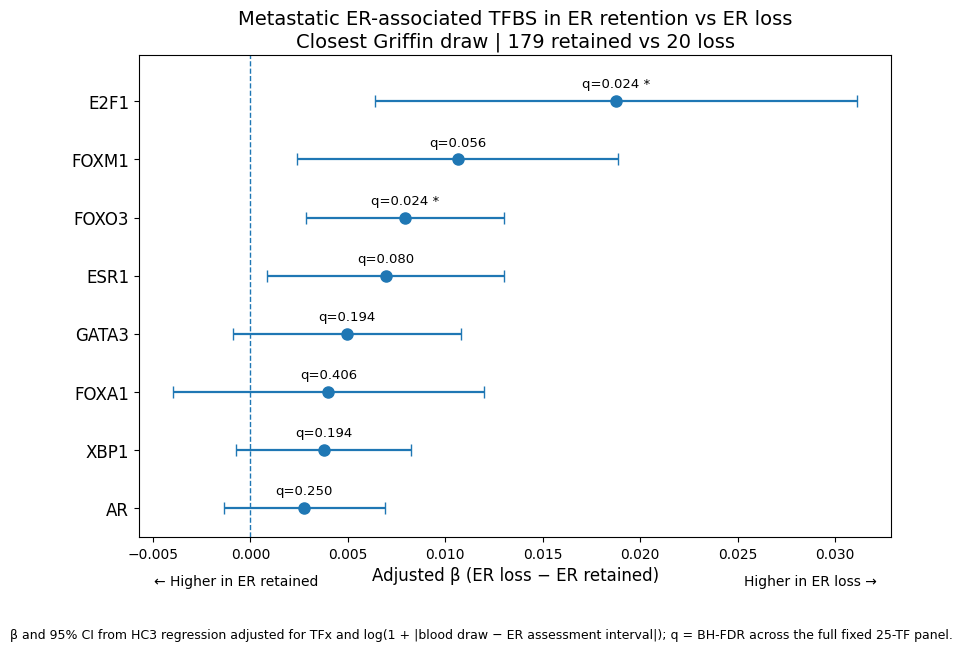


FINAL SUMMARY
Cohort: 199
ER retained: 179
ER loss: 20
Full 25-TF FDR-significant: 4/25
Focused 8 directionally consistent: 8/8
Focused 8 q25-significant: 2/8

Model:
mean coverage ~ ER_loss + TFx_pct + log(1 + abs_lag_days)

β interpretation:
positive = higher in ER loss
negative = higher in ER retained

Output directory:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Met_ER_Closest_Draw_TFBS/ClosestDraw_ER_Retained_vs_Loss_25TF


In [21]:
# ======================================================================
# AURORA
# ER EVOLUTION ANALYSIS
# Q 3.1 Which features appear to drive different patterns?
# Primary ER+ patients:
#   ER retained: 179
#   ER loss:      20
#
# Griffin sample:
#   Closest available Griffin blood draw to the
#   first informative metastatic ER assessment
#
# PRIMARY INFERENCE:
#   Run ALL fixed 25 TFBS using mean coverage
#
# Model:
#   TFBS mean coverage ~ ER_loss
#                        + TFx_pct
#                        + log(1 + abs_lag_days)
#
# Coding:
#   ER retained = 0
#   ER loss     = 1
#
# Therefore:
#   beta > 0 = higher Griffin coverage in ER-loss
#   beta < 0 = lower Griffin coverage in ER-loss
#
# Multiple testing:
#   BH-FDR across ALL 25 TFBS
#
# Focused figure:
#   Plot the 8 TFBS identified in the metastatic ER analysis,
#   but retain q25 values calculated across all 25 TFBS.
#
# Seed = 1234
# ======================================================================

# ======================================================================
# 0. IMPORTS
# ======================================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import statsmodels.api as sm

from statsmodels.stats.multitest import multipletests

SEED = 1234

# ======================================================================
# 1. PATHS
# ======================================================================

BASE_DIR = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "Griffin/Downstream/"
    "AURORA_Griffin_Met_ER_Closest_Draw_TFBS"
)

# Closest-draw audit already generated
CLOSEST_AUDIT = (
    BASE_DIR /
    "ClosestDraw_MetER_patient_audit.tsv"
)

# 44-TF Griffin workbook
GRIFFIN_XLSX = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "Griffin/griffin_nucleosome_profiling/"
    "Griffin_44TF_GC_corrected_summary_by_module.xlsx"
)

# ----------------------------------------------------------------------
# ER evolution mapping
#
# This file only provides patient-level:
#   Primary ER+
#   ER retained / ER loss
#
# The "sample" column in this file is NOT used.
# We will use the closest selected sample from CLOSEST_AUDIT instead.
#
# ----------------------------------------------------------------------

SPLIT_TSV = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "Griffin/Downstream/AURORA_Griffin_Heldout_Test_ER/"
    "Cohort_split.tsv"
)

OUT_DIR = (
    BASE_DIR /
    "ClosestDraw_ER_Retained_vs_Loss_25TF"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Output directory:")
print(OUT_DIR)

# ======================================================================
# 2. 25-TF PANEL
# ======================================================================

TF25 = [
    "ESR1", "FOXA1", "GATA3", "PGR", "GRHL2",
    "STAT3", "NFKB1", "TFAP2C", "XBP1", "FOXM1", 
    "FOXO3", "AR", "ESR2", "FOXO1", "RUNX1", 
    "E2F1", "E2F7", "TEAD1", "TEAD4", "FOSL1", 
    "BACH1", "HIF1A", "ETS1", "CEBPB", "ELF3"
]

assert len(TF25) == 25

# ======================================================================
# 3. EIGHT TFBS FROM METASTATIC ER ANALYSIS
# ======================================================================

TF8 = [

    "ESR1", "FOXA1", "GATA3", "XBP1",
    "FOXM1", "FOXO3", "AR", "E2F1"
]

assert set(TF8).issubset(set(TF25))

# ======================================================================
# 4. SAMPLE/PATIENT ID NORMALIZATION
# ======================================================================

def normalize_id(x):

    if pd.isna(x):
        return np.nan

    x = str(x).strip()

    # Excel sometimes converts numeric IDs to strings such as "10.0"
    if x.endswith(".0"):

        try:

            float(x)

            x = x[:-2]

        except:

            pass

    return x

def normalize_sample_id(x):

    if pd.isna(x):
        return np.nan

    x = str(x).strip()

    if x.startswith("AUP-"):
        x = x[4:]

    return x

# ======================================================================
# 5. LOAD CLOSEST-DRAW AUDIT
# ======================================================================

closest = pd.read_csv(
    CLOSEST_AUDIT,
    sep="\t"
)

print("\n==============================================")
print("CLOSEST-DRAW AUDIT")
print("==============================================")

print(
    "Rows:",
    len(closest)
)

required_cols = [

    "patient_id",
    "met_ER",
    "selected_sample",
    "TFx_pct",
    "abs_lag_days"
]

missing = [

    x for x in required_cols

    if x not in closest.columns
]

if missing:

    raise ValueError(
        f"Missing closest-audit columns: {missing}"
    )

closest["patient_id_norm"] = (
    closest["patient_id"]
    .map(normalize_id)
)

closest["selected_sample"] = (
    closest["selected_sample"]
    .map(normalize_sample_id)
)

closest["TFx_pct"] = pd.to_numeric(
    closest["TFx_pct"],
    errors="coerce"
)


closest["abs_lag_days"] = pd.to_numeric(
    closest["abs_lag_days"],
    errors="coerce"
)

closest["log_abs_lag"] = np.log1p(
    closest["abs_lag_days"]
)

print(
    "\nClosest-draw metastatic ER:"
)

print(
    closest["met_ER"].value_counts()
)

# ======================================================================
# 6. LOAD ER RETAINED / LOSS PATIENT MAPPING
# ======================================================================
# ======================================================================
# LOAD ER-EVOLUTION PATIENT MAPPING DIRECTLY FROM COHORT_SPLIT
# ======================================================================

split = pd.read_csv(
    SPLIT_TSV,
    sep="\t",
    dtype={"patient_id": str}
)

print("\n==============================================")
print("ER EVOLUTION COHORT")
print("==============================================")

# Normalize patient ID
split["patient_id_norm"] = (
    split["patient_id"]
    .map(normalize_id)
)

# Normalize receptor values
def normalize_er(x):

    if pd.isna(x):
        return np.nan

    x = str(x).strip().lower()

    if x in {"positive", "pos", "+", "er+"}:
        return "Positive"

    if x in {"negative", "neg", "-", "er-"}:
        return "Negative"

    return np.nan

split["Primary_tumor_ER"] = (
    split["Primary_tumor_ER"]
    .map(normalize_er)
)

# Handle either possible metastatic ER column name
if "Earliest_metastatic_ER" in split.columns:

    split["Metastatic_ER"] = (
        split["Earliest_metastatic_ER"]
        .map(normalize_er)
    )

elif "Metastatic_ER" in split.columns:

    split["Metastatic_ER"] = (
        split["Metastatic_ER"]
        .map(normalize_er)
    )

else:

    raise ValueError(
        "Could not find metastatic ER column."
    )

# ======================================================================
# PRIMARY ER+ ONLY
# ======================================================================

evolution = split.loc[

    (split["Primary_tumor_ER"] == "Positive")
    &
    (split["Metastatic_ER"].isin(
        ["Positive", "Negative"]
    ))

].copy()

# ======================================================================
# DEFINE ER EVOLUTION
# ======================================================================

evolution["ER_group"] = np.where(

    evolution["Metastatic_ER"] == "Positive",

    "ER retained",

    "ER loss"
)

# Patient-level information only.
# IMPORTANT:
# Ignore the sample column from Cohort_split.
# The Griffin sample will come from the NEW closest-draw audit.
evolution = (

    evolution[
        [
            "patient_id_norm",
            "ER_group"
        ]
    ]
    .drop_duplicates(
        subset="patient_id_norm"
    )
)

print(
    evolution["ER_group"]
    .value_counts()
)

print(
    "\nTotal:",
    len(evolution)
)

# ======================================================================
# 7. MERGE ER-EVOLUTION GROUP WITH CLOSEST-DRAW AUDIT
# ======================================================================

analysis = evolution.merge(

    closest,

    on="patient_id_norm",

    how="left",

    validate="one_to_one",

    indicator=True
)

print("\n==============================================")
print("EVOLUTION × CLOSEST-DRAW MATCHING")
print("==============================================")

print(
    analysis["_merge"].value_counts()
)

if (
    analysis["_merge"]
    !=
    "both"
).any():

    print(
        "\nPatients not found in closest-draw audit:"
    )

    print(

        analysis.loc[
            analysis["_merge"] != "both",
            [
                "patient_id_norm",
                "ER_group"
            ]
        ].to_string(
            index=False
        )
    )

analysis = analysis.loc[
    analysis["_merge"] == "both"
].copy()

analysis = analysis.drop(
    columns="_merge"
)

# ======================================================================
# 8. CRITICAL QC:
# CHECK METASTATIC ER STATUS AGREES WITH EVOLUTION GROUP
# ======================================================================
#
# Expected:
#
# ER retained -> metastatic ER Positive
# ER loss     -> metastatic ER Negative
#
# ======================================================================

analysis[
    "expected_met_ER"
] = np.where(

    analysis["ER_group"]
    ==
    "ER retained",

    "Positive",

    "Negative"
)

analysis[
    "met_ER_concordant"
] = (

    analysis["met_ER"]
    ==
    analysis["expected_met_ER"]
)

print("\n==============================================")
print("ER GROUP CONCORDANCE QC")
print("==============================================")

print(

    pd.crosstab(

        analysis["ER_group"],

        analysis["met_ER"]
    )
)

discordant = analysis.loc[
    ~analysis["met_ER_concordant"]
]

print(
    "\nDiscordant patients:",
    len(discordant)
)

if len(discordant) > 0:

    print(

        discordant[
            [
                "patient_id_norm",
                "ER_group",
                "met_ER",
                "ER_assessment_day"
            ]
        ].to_string(
            index=False
        )
    )

    raise ValueError(
        "ER evolution group does not match closest-draw metastatic ER."
    )

# ======================================================================
# 9. EXPECTED COHORT COUNTS
# ======================================================================

print("\n==============================================")
print("CLOSEST-DRAW ER EVOLUTION COHORT")
print("==============================================")

print(
    "Total:",
    len(analysis)
)

print(

    analysis[
        "ER_group"
    ].value_counts()
)

# Expected:
# ER retained = 179
# ER loss      = 20
# Total        = 199

if not (
    len(analysis) == 199
    and
    (analysis["ER_group"] == "ER retained").sum() == 179
    and
    (analysis["ER_group"] == "ER loss").sum() == 20
):

    print(
        "\nWARNING:"
        "\nExpected 199 patients = "
        "179 ER retained + 20 ER loss."
    )

# ======================================================================
# 10. PRINT WHICH CLOSEST NB WAS SELECTED
# ======================================================================

if "selected_NB" in analysis.columns:

    print(
        "\nSelected closest NB:"
    )

    print(
        analysis[
            "selected_NB"
        ].value_counts(
            sort=False
        ).sort_index()
    )

# ======================================================================
# 11. TIMING SUMMARY BY ER EVOLUTION
# ======================================================================

print("\n==============================================")
print("TIMING BY ER EVOLUTION GROUP")
print("==============================================")

timing_summary = (

    analysis
    .groupby(
        "ER_group"
    )
    ["abs_lag_days"]
    .agg(
        [
            "count",
            "median",
            "mean",
            "min",
            "max"
        ]
    )
)

print(
    timing_summary
)

# ======================================================================
# 12. LOAD GRIFFIN 44-TF WORKBOOK
# ======================================================================

griffin = pd.read_excel(

    GRIFFIN_XLSX,

    sheet_name="Breast_Lineage",

    header=[
        0,
        1
    ]
)

print("\n==============================================")
print("GRIFFIN DATA")
print("==============================================")

print(
    "Raw shape:",
    griffin.shape
)

# ======================================================================
# 13. FLATTEN TWO-ROW HEADER
# ======================================================================

new_columns = []

for col1, col2 in griffin.columns:

    col1_str = str(col1)
    col2_str = str(col2)

    if col1_str.lower() == "sample":

        new_columns.append(
            "sample"
        )

    elif (
        pd.notna(col2)
        and
        not col2_str.startswith("Unnamed")
    ):

        new_columns.append(
            col2_str
        )

    else:

        new_columns.append(
            col1_str
        )

griffin.columns = new_columns

griffin[
    "sample"
] = griffin[
    "sample"
].map(
    normalize_sample_id
)

# ======================================================================
# 14. MEAN-COVERAGE FEATURES
# ======================================================================

MEAN_FEATURES = [

    f"{tf}_mean_coverage"

    for tf in TF25
]

missing_features = [

    x for x in MEAN_FEATURES

    if x not in griffin.columns
]

if missing_features:

    print(
        "\nMissing Griffin features:"
    )

    for x in missing_features:

        print(x)

    raise ValueError(
        "Some fixed 25-TF mean-coverage features are missing."
    )

print(
    "\nAll 25 mean-coverage TFBS found."
)

# ======================================================================
# 15. MERGE SELECTED CLOSEST DRAWS WITH GRIFFIN
# ======================================================================

griffin_sub = griffin[
    [
        "sample"
    ]
    +
    MEAN_FEATURES
].copy()

df = analysis.merge(

    griffin_sub,

    left_on="selected_sample",

    right_on="sample",

    how="left",

    validate="one_to_one"
)

# ======================================================================
# 16. COMPLETE-CASE QC
# ======================================================================

missing_griffin = (

    df[
        MEAN_FEATURES
    ]
    .isna()
    .any(
        axis=1
    )
)

missing_tfx = (
    df["TFx_pct"]
    .isna()
)

missing_lag = (
    df["log_abs_lag"]
    .isna()
)

print("\n==============================================")
print("FINAL MERGE QC")
print("==============================================")

print(
    "Missing Griffin:",
    int(missing_griffin.sum())
)

print(
    "Missing TFx:",
    int(missing_tfx.sum())
)

print(
    "Missing timing:",
    int(missing_lag.sum())
)

df = df.loc[

    (~missing_griffin)
    &
    (~missing_tfx)
    &
    (~missing_lag)

].copy()

# ======================================================================
# 17. ER-LOSS CODING
# ======================================================================

df[
    "ER_loss"
] = (

    df[
        "ER_group"
    ]
    .eq(
        "ER loss"
    )
    .astype(int)
)

n_total = len(df)

n_retained = int(
    (
        df["ER_loss"]
        ==
        0
    ).sum()
)

n_loss = int(
    df[
        "ER_loss"
    ].sum()
)

print("\n==============================================")
print("FINAL MODELING COHORT")
print("==============================================")

print(
    "Total:",
    n_total
)

print(
    "ER retained:",
    n_retained
)

print(
    "ER loss:",
    n_loss
)

# ======================================================================
# 18. MODEL FUNCTION
# ======================================================================
#
# Mean coverage ~ ER_loss + TFx + log_abs_lag
#
# HC3 robust SE
#
# beta ER_loss:
#   positive -> higher in ER loss
#   negative -> lower in ER loss
#
# ======================================================================

def fit_model(
    data,
    feature
):

    d = data[
        [
            feature,
            "ER_loss",
            "TFx_pct",
            "log_abs_lag"
        ]
    ].dropna().copy()

    X = sm.add_constant(

        d[
            [
                "ER_loss",
                "TFx_pct",
                "log_abs_lag"
            ]
        ]
    )

    y = d[
        feature
    ]


    fit = sm.OLS(
        y,
        X
    ).fit(
        cov_type="HC3"
    )

    ci = (
        fit
        .conf_int()
        .loc[
            "ER_loss"
        ]
    )

    return {

        "n":
            len(d),

        "beta_loss_minus_retained":
            fit.params[
                "ER_loss"
            ],

        "HC3_SE":
            fit.bse[
                "ER_loss"
            ],

        "CI95_low":
            ci.iloc[0],

        "CI95_high":
            ci.iloc[1],

        "p":
            fit.pvalues[
                "ER_loss"
            ],

        "TFx_beta":
            fit.params[
                "TFx_pct"
            ],

        "TFx_p":
            fit.pvalues[
                "TFx_pct"
            ],

        "lag_beta":
            fit.params[
                "log_abs_lag"
            ],

        "lag_p":
            fit.pvalues[
                "log_abs_lag"
            ],

        "R2":
            fit.rsquared
    }

# ======================================================================
# 19. RUN ALL 25 TFBS
# ======================================================================

results = []

for tf in TF25:

    feature = (
        f"{tf}_mean_coverage"
    )


    r = fit_model(
        df,
        feature
    )

    results.append({

        "TF":
            tf,

        "Feature":
            feature,

        "n":
            r["n"],

        "n_ER_retained":
            n_retained,

        "n_ER_loss":
            n_loss,

        "beta_loss_minus_retained":
            r[
                "beta_loss_minus_retained"
            ],

        "HC3_SE":
            r["HC3_SE"],

        "CI95_low":
            r["CI95_low"],

        "CI95_high":
            r["CI95_high"],

        "p":
            r["p"],

        "TFx_beta":
            r["TFx_beta"],

        "TFx_p":
            r["TFx_p"],

        "log_abs_lag_beta":
            r["lag_beta"],

        "log_abs_lag_p":
            r["lag_p"],

        "R2":
            r["R2"]
    })

results_df = pd.DataFrame(
    results
)

# ======================================================================
# 20. BH-FDR ACROSS ALL 25 TFBS
# ======================================================================

results_df[
    "BH_q25"
] = multipletests(

    results_df[
        "p"
    ].to_numpy(),

    method="fdr_bh"

)[1]

results_df[
    "FDR_significant_q25"
] = (

    results_df[
        "BH_q25"
    ]
    <
    0.05
)

# ======================================================================
# 21. FLAG THE PREVIOUSLY IDENTIFIED 8 TFBS
# ======================================================================

results_df[
    "MetER_8TF"
] = (

    results_df[
        "TF"
    ]
    .isin(
        TF8
    )
)

# Because previous metastatic ER beta was:
#
#   ER+ - ER- < 0
#
# ER loss is metastatic ER-.
#
# Therefore, directionally consistent evolution signal:
#
#   ER loss - ER retained > 0
#
# ======================================================================

results_df[
    "Direction_consistent"
] = (

    results_df[
        "beta_loss_minus_retained"
    ]
    >
    0
)

# ======================================================================
# 22. PRINT ALL 25 RESULTS
# ======================================================================

print("\n")
print("=" * 100)
print("ALL 25 TFBS — ER RETAINED VS ER LOSS")
print("=" * 100)

print(

    results_df[
        [
            "TF",
            "beta_loss_minus_retained",
            "CI95_low",
            "CI95_high",
            "p",
            "BH_q25"
        ]
    ]
    .sort_values(
        "p"
    )
    .to_string(
        index=False
    )
)

# ======================================================================
# 23. PRINT FDR-SIGNIFICANT TFBS FROM FULL 25
# ======================================================================

sig25 = results_df.loc[
    results_df[
        "BH_q25"
    ] < 0.05
].copy()

print("\n==============================================")
print("FDR SIGNIFICANT ACROSS FULL 25-TF PANEL")
print("==============================================")

if len(sig25) == 0:

    print(
        "None"
    )

else:

    print(

        sig25[
            [
                "TF",
                "beta_loss_minus_retained",
                "p",
                "BH_q25"
            ]
        ]
        .sort_values(
            "BH_q25"
        )
        .to_string(
            index=False
        )
    )

# ======================================================================
# 24. FOCUSED 8-TF RESULT TABLE
# ======================================================================

focus8 = (

    results_df.loc[
        results_df[
            "MetER_8TF"
        ]
    ]
    .copy()
)

# Keep predefined order
focus8[
    "TF_order"
] = focus8[
    "TF"
].map({

    tf: i

    for i, tf in enumerate(
        TF8
    )
})

focus8 = (

    focus8
    .sort_values(
        "TF_order"
    )
    .drop(
        columns="TF_order"
    )
)

print("\n==============================================")
print("FOCUSED 8 TFBS")
print("==============================================")

print(

    focus8[
        [
            "TF",
            "beta_loss_minus_retained",
            "CI95_low",
            "CI95_high",
            "p",
            "BH_q25",
            "Direction_consistent"
        ]
    ].to_string(
        index=False
    )
)

# ======================================================================
# 25. DIRECTION CONSISTENCY SUMMARY
# ======================================================================

n_consistent = int(
    focus8[
        "Direction_consistent"
    ].sum()
)

print(
    f"\nDirectionally consistent TFBS: "
    f"{n_consistent}/8"
)

print(
    "\nExpected direction:"
    "\npositive beta = higher Griffin coverage in ER loss"
)

# ======================================================================
# 26. SAVE TABLES
# ======================================================================

results_df.to_csv(

    OUT_DIR /
    "ClosestDraw_ERretained_vs_ERloss_ALL25_mean_TFx_LogLag.tsv",

    sep="\t",

    index=False
)

focus8.to_csv(

    OUT_DIR /
    "ClosestDraw_ERretained_vs_ERloss_Focused8_mean_TFx_LogLag.tsv",

    sep="\t",

    index=False
)

# ======================================================================
# 27. FOREST PLOT — ALL 8 TARGETED TFBS
#
# IMPORTANT:
#
# Plot ALL eight, regardless of their significance in this analysis.
#
# q-values shown are q25 values from the full 25-TF analysis.
#
# ======================================================================

plot_df = focus8.copy()

# Sort for forest visualization
plot_df = plot_df.sort_values(
    "beta_loss_minus_retained",
    ascending=True
).reset_index(
    drop=True
)

beta = plot_df[
    "beta_loss_minus_retained"
].to_numpy()

low = plot_df[
    "CI95_low"
].to_numpy()

high = plot_df[
    "CI95_high"
].to_numpy()

qvals = plot_df[
    "BH_q25"
].to_numpy()

genes = plot_df[
    "TF"
].astype(str).to_numpy()

y = np.arange(
    len(plot_df)
)

fig, ax = plt.subplots(
    figsize=(8.5, 6.5)
)

# ======================================================================
# 28. EFFECT + 95% CI
# ======================================================================

ax.errorbar(

    beta,
    y,

    xerr=[
        beta - low,
        high - beta
    ],

    fmt="o",

    markersize=8,

    capsize=4,

    linewidth=1.6
)

# Null line
ax.axvline(
    0,
    linestyle="--",
    linewidth=1
)

# ======================================================================
# 29. GENE LABELS
# ======================================================================

ax.set_yticks(
    y
)

ax.set_yticklabels(
    genes,
    fontsize=12
)

# ======================================================================
# 30. Q-VALUE ABOVE EACH CI
# ======================================================================

for i in range(
    len(plot_df)
):

    # Center q-value above its CI
    x_position = (
        low[i] + high[i]
    ) / 2

    if qvals[i] < 0.001:

        q_text = (
            f"q={qvals[i]:.1e}"
        )

    else:

        q_text = (
            f"q={qvals[i]:.3f}"
        )

    # Add star only if q25 < 0.05
    if qvals[i] < 0.05:

        q_text += " *"

    ax.text(

        x_position,

        y[i] + 0.18,

        q_text,

        ha="center",
        va="bottom",

        fontsize=9.5
    )

# ======================================================================
# 31. LABELS
# ======================================================================

ax.set_xlabel(

    "Adjusted β (ER loss − ER retained)",

    fontsize=12
)

ax.set_ylabel(
    ""
)

ax.set_title(

    "Metastatic ER-associated TFBS in ER retention vs ER loss\n"
    f"Closest Griffin draw | "
    f"{n_retained} retained vs {n_loss} loss",

    fontsize=14
)

# Direction labels
ax.text(

    0.02,
    -0.10,

    "← Higher in ER retained",

    transform=ax.transAxes,

    ha="left",

    fontsize=10
)

ax.text(

    0.98,
    -0.10,

    "Higher in ER loss →",

    transform=ax.transAxes,

    ha="right",

    fontsize=10
)

# Footnote
fig.text(

    0.5,
    0.01,

    "β and 95% CI from HC3 regression adjusted for TFx and "
    "log(1 + |blood draw − ER assessment interval|); "
    "q = BH-FDR across the full fixed 25-TF panel.",

    ha="center",

    fontsize=9
)

ax.set_ylim(
    -0.5,
    len(plot_df) - 0.20
)

plt.tight_layout(
    rect=[
        0,
        0.06,
        1,
        1
    ]
)

# ======================================================================
# 32. SAVE FOREST
# ======================================================================

fig.savefig(

    OUT_DIR /
    "Figure_ERretained_vs_ERloss_Focused8_mean_forest.png",

    dpi=600,

    bbox_inches="tight"
)

fig.savefig(

    OUT_DIR /
    "Figure_ERretained_vs_ERloss_Focused8_mean_forest.pdf",

    bbox_inches="tight"
)

plt.show()

plt.close(fig)

# ======================================================================
# 33. FINAL SUMMARY
# ======================================================================

print("\n==============================================")
print("FINAL SUMMARY")
print("==============================================")

print(
    f"Cohort: {n_total}"
)

print(
    f"ER retained: {n_retained}"
)


print(
    f"ER loss: {n_loss}"
)

print(
    f"Full 25-TF FDR-significant: "
    f"{len(sig25)}/25"
)

print(
    f"Focused 8 directionally consistent: "
    f"{n_consistent}/8"
)

print(
    f"Focused 8 q25-significant: "
    f"{int((focus8['BH_q25'] < 0.05).sum())}/8"
)

print(
    "\nModel:"
)

print(
    "mean coverage ~ ER_loss + TFx_pct + "
    "log(1 + abs_lag_days)"
)

print(
    "\nβ interpretation:"
)

print(
    "positive = higher in ER loss"
)

print(
    "negative = higher in ER retained"
)

print(
    "\nOutput directory:"
)

print(
    OUT_DIR
)

Output directory:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Met_ER_Closest_Draw_TFBS/ClosestDraw_StableERneg_vs_ERretained_25TF

COHORT SPLIT
Rows: 241

ER EVOLUTION GROUPS
ER retained    179
Stable ER-      40
ER loss         20
ER gain          2
Name: Evolution_group, dtype: int64

TARGET TWO-GROUP COHORT
ER retained    179
Stable ER-      40
Name: Evolution_group, dtype: int64

Total: 219

CLOSEST-DRAW AUDIT
Patients: 244
Positive    183
Negative     61
Name: met_ER, dtype: int64

MATCH TO CLOSEST-DRAW AUDIT
both          219
left_only       0
right_only      0
Name: _merge, dtype: int64

METASTATIC ER CONCORDANCE
met_ER           Negative  Positive
Evolution_group                    
ER retained             0       179
Stable ER-             40         0

Discordant: 0

ANALYSIS GROUP COUNTS
ER retained    179
Stable ER-      40
Name: Evolution_group, dtype: int64

Total: 219

BLOOD–ER TIMING BY GROUP
                 count  median     

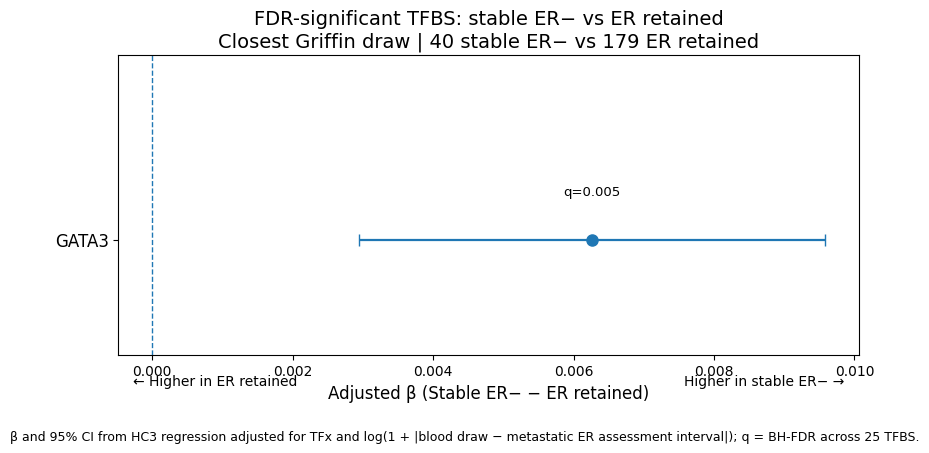


FINAL SUMMARY
ER retained: 179
Stable ER-: 40
Total: 219
FDR-significant TFBS: 1/25

Model:
mean coverage ~ Stable_ERneg + TFx_pct + log(1 + abs_lag_days)

β interpretation:
positive beta = higher Griffin mean coverage in stable ER-
negative beta = higher Griffin mean coverage in ER retained

Results saved to:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Met_ER_Closest_Draw_TFBS/ClosestDraw_StableERneg_vs_ERretained_25TF


In [1]:
# ======================================================================
# AURORA
# STABLE ER- VS ER-RETAINED ANALYSIS
# Q3.2) Which features appear to drive different patterns?
# Groups:
#
# ER retained:
#   Primary ER+ -> Metastatic ER+
#   expected n = 179
#
# Stable ER-:
#   Primary ER- -> Metastatic ER-
#   expected n = 40
#
# Total expected n = 219
#
# Griffin sample:
#   Closest available Griffin blood draw to the
#   first informative metastatic ER assessment.
#
# Primary metric:
#   Mean coverage
#
# Model:
#
#   TFBS mean coverage ~ Stable_ERneg
#                        + TFx_pct
#                        + log(1 + abs_lag_days)
#
# Coding:
#
#   ER retained = 0
#   Stable ER-  = 1
#
# Therefore:
#
#   beta > 0 = higher mean coverage in stable ER-
#   beta < 0 = higher mean coverage in ER retained
#
# Statistics:
#   OLS with HC3 robust standard errors
#
# Multiple testing:
#   BH-FDR across ALL 25 TFBS
#
# Seed = 1234
# ======================================================================

# ======================================================================
# 0. IMPORTS
# ======================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import statsmodels.api as sm

from statsmodels.stats.multitest import multipletests

SEED = 1234

# ======================================================================
# 1. PATHS
# ======================================================================

AURORA_BASE = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA"
)

SPLIT_TSV = (
    AURORA_BASE
    / "Griffin"
    / "Downstream"
    / "AURORA_Griffin_Heldout_Test_ER"
    / "Cohort_split.tsv"
)

BASE_DIR = (
    AURORA_BASE
    / "Griffin"
    / "Downstream"
    / "AURORA_Griffin_Met_ER_Closest_Draw_TFBS"
)

CLOSEST_AUDIT = (
    BASE_DIR
    / "ClosestDraw_MetER_patient_audit.tsv"
)

GRIFFIN_XLSX = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "Griffin/griffin_nucleosome_profiling/"
    "Griffin_44TF_GC_corrected_summary_by_module.xlsx"
)

OUT_DIR = (
    BASE_DIR
    / "ClosestDraw_StableERneg_vs_ERretained_25TF"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Output directory:")
print(OUT_DIR)

# ======================================================================
# 2. 25-TF PANEL
# ======================================================================

TF25 = [
    "ESR1", "FOXA1", "GATA3", "PGR", "GRHL2",
    "STAT3", "NFKB1", "TFAP2C", "XBP1", "FOXM1", 
    "FOXO3", "AR", "ESR2", "FOXO1", "RUNX1", 
    "E2F1", "E2F7", "TEAD1", "TEAD4", "FOSL1", 
    "BACH1", "HIF1A", "ETS1", "CEBPB", "ELF3"
]
assert len(TF25) == 25

# ======================================================================
# 3. PRIOR 8 METASTATIC-ER ASSOCIATED TFBS
#
# These are NOT used for multiple-testing selection.
# They are only flagged in the output for comparison.
# ======================================================================

TF8_MET_ER = [

    "ESR1", "FOXA1", "GATA3", "XBP1",
    "FOXM1", "FOXO3", "AR", "E2F1"
]

# ======================================================================
# 4. ID NORMALIZATION
# ======================================================================

def normalize_patient_id(x):

    if pd.isna(x):
        return np.nan

    x = str(x).strip()

    try:

        f = float(x)

        if f.is_integer():
            return str(int(f))

    except (TypeError, ValueError):

        pass

    return x


def normalize_sample_id(x):

    if pd.isna(x):
        return np.nan

    x = str(x).strip()

    if x.startswith("AUP-"):
        x = x[4:]

    return x


def normalize_er(x):

    if pd.isna(x):
        return np.nan

    x = str(x).strip().lower()

    if x in {
        "positive",
        "pos",
        "+",
        "er+"
    }:
        return "Positive"

    if x in {
        "negative",
        "neg",
        "-",
        "er-"
    }:
        return "Negative"

    return np.nan

# ======================================================================
# 5. LOAD COHORT SPLIT
# ======================================================================

split = pd.read_csv(
    SPLIT_TSV,
    sep="\t",
    dtype={"patient_id": str}
)

print("\n==============================================")
print("COHORT SPLIT")
print("==============================================")

print(
    "Rows:",
    len(split)
)

split["patient_id_norm"] = (
    split["patient_id"]
    .map(normalize_patient_id)
)

split["Primary_tumor_ER"] = (
    split["Primary_tumor_ER"]
    .map(normalize_er)
)

# ======================================================================
# 6. METASTATIC ER ENDPOINT
# ======================================================================

if "Earliest_metastatic_ER" in split.columns:

    split["Metastatic_ER"] = (
        split["Earliest_metastatic_ER"]
        .map(normalize_er)
    )

elif "Metastatic_ER" in split.columns:

    split["Metastatic_ER"] = (
        split["Metastatic_ER"]
        .map(normalize_er)
    )

else:

    raise ValueError(
        "Could not find Earliest_metastatic_ER or Metastatic_ER."
    )

# ======================================================================
# 7. DEFINE EVOLUTION GROUPS
# ======================================================================

split["Evolution_group"] = np.select(

    [

        (
            split["Primary_tumor_ER"].eq("Positive")
            &
            split["Metastatic_ER"].eq("Positive")
        ),

        (
            split["Primary_tumor_ER"].eq("Positive")
            &
            split["Metastatic_ER"].eq("Negative")
        ),

        (
            split["Primary_tumor_ER"].eq("Negative")
            &
            split["Metastatic_ER"].eq("Negative")
        ),

        (
            split["Primary_tumor_ER"].eq("Negative")
            &
            split["Metastatic_ER"].eq("Positive")
        )

    ],

    [

        "ER retained",
        "ER loss",
        "Stable ER-",
        "ER gain"

    ],

    default="Other/Unknown"
)

print("\n==============================================")
print("ER EVOLUTION GROUPS")
print("==============================================")

print(
    split["Evolution_group"]
    .value_counts()
)

# ======================================================================
# 8. KEEP ONLY RETAINED + STABLE ER-
# ======================================================================

evolution = split.loc[

    split["Evolution_group"].isin(
        [
            "ER retained",
            "Stable ER-"
        ]
    )

].copy()

# We only need patient-level labels from Cohort_split.

evolution = (

    evolution[
        [
            "patient_id_norm",
            "Primary_tumor_ER",
            "Metastatic_ER",
            "Evolution_group"
        ]
    ]

    .drop_duplicates(
        subset="patient_id_norm"
    )
)

print("\n==============================================")
print("TARGET TWO-GROUP COHORT")
print("==============================================")


print(
    evolution["Evolution_group"]
    .value_counts()
)

print(
    "\nTotal:",
    len(evolution)
)

# ======================================================================
# 9. LOAD CLOSEST-DRAW AUDIT
# ======================================================================

closest = pd.read_csv(
    CLOSEST_AUDIT,
    sep="\t",
    dtype={"patient_id": str}
)

closest["patient_id_norm"] = (
    closest["patient_id"]
    .map(normalize_patient_id)
)

closest["selected_sample"] = (
    closest["selected_sample"]
    .map(normalize_sample_id)
)

closest["TFx_pct"] = pd.to_numeric(
    closest["TFx_pct"],
    errors="coerce"
)

closest["abs_lag_days"] = pd.to_numeric(
    closest["abs_lag_days"],
    errors="coerce"
)

closest["log_abs_lag"] = np.log1p(
    closest["abs_lag_days"]
)

print("\n==============================================")
print("CLOSEST-DRAW AUDIT")
print("==============================================")

print(
    "Patients:",
    len(closest)
)

print(
    closest["met_ER"]
    .value_counts()
)

# ======================================================================
# 10. MERGE EVOLUTION LABEL WITH CLOSEST-DRAW SAMPLE
# ======================================================================

analysis = evolution.merge(

    closest,

    on="patient_id_norm",

    how="left",

    validate="one_to_one",

    indicator=True
)

print("\n==============================================")
print("MATCH TO CLOSEST-DRAW AUDIT")
print("==============================================")

print(
    analysis["_merge"]
    .value_counts()
)

# Show unmatched if any

unmatched = analysis.loc[
    analysis["_merge"] != "both"
]

if len(unmatched) > 0:

    print(
        "\nPatients not found in closest-draw audit:"
    )

    print(

        unmatched[
            [
                "patient_id_norm",
                "Evolution_group"
            ]
        ]
        .to_string(
            index=False
        )
    )

analysis = analysis.loc[
    analysis["_merge"] == "both"
].copy()

analysis = analysis.drop(
    columns="_merge"
)

# ======================================================================
# 11. CRITICAL ER CONCORDANCE QC
#
# ER retained:
#     closest metastatic ER must be Positive
#
# Stable ER-:
#     closest metastatic ER must be Negative
# ======================================================================

analysis["Expected_met_ER"] = np.where(

    analysis["Evolution_group"].eq(
        "ER retained"
    ),

    "Positive",

    "Negative"
)

analysis["MetER_concordant"] = (

    analysis["met_ER"]
    ==
    analysis["Expected_met_ER"]
)

print("\n==============================================")
print("METASTATIC ER CONCORDANCE")
print("==============================================")

print(

    pd.crosstab(

        analysis["Evolution_group"],

        analysis["met_ER"]
    )
)

discordant = analysis.loc[
    ~analysis["MetER_concordant"]
]

print(
    "\nDiscordant:",
    len(discordant)
)

if len(discordant) > 0:

    print(

        discordant[
            [
                "patient_id_norm",
                "Evolution_group",
                "Metastatic_ER",
                "met_ER"
            ]
        ].to_string(
            index=False
        )
    )

    raise ValueError(
        "Evolution endpoint does not match closest-draw ER anchor."
    )

# ======================================================================
# 12. FINAL GROUP QC BEFORE GRIFFIN MERGE
# ======================================================================

print("\n==============================================")
print("ANALYSIS GROUP COUNTS")
print("==============================================")

print(
    analysis["Evolution_group"]
    .value_counts()
)

print(
    "\nTotal:",
    len(analysis)
)

# ======================================================================
# 13. TIMING BY GROUP
# ======================================================================

timing_summary = (

    analysis
    .groupby(
        "Evolution_group"
    )
    ["abs_lag_days"]
    .agg(
        [
            "count",
            "median",
            "mean",
            "std",
            "min",
            "max"
        ]
    )
)

print("\n==============================================")
print("BLOOD–ER TIMING BY GROUP")
print("==============================================")

print(
    timing_summary
)

# ======================================================================
# 14. TUMOR FRACTION BY GROUP
# ======================================================================

tfx_summary = (

    analysis
    .groupby(
        "Evolution_group"
    )
    ["TFx_pct"]
    .agg(
        [
            "count",
            "median",
            "mean",
            "std",
            "min",
            "max"
        ]
    )
)

print("\n==============================================")
print("TFx BY GROUP")
print("==============================================")

print(
    tfx_summary
)

# ======================================================================
# 15. LOAD GRIFFIN WORKBOOK
# ======================================================================

griffin = pd.read_excel(

    GRIFFIN_XLSX,

    sheet_name="Breast_Lineage",

    header=[
        0,
        1
    ]
)

print("\n==============================================")
print("GRIFFIN")
print("==============================================")

print(
    "Raw shape:",
    griffin.shape
)

# ======================================================================
# 16. FLATTEN HEADER
# ======================================================================

new_columns = []

for col1, col2 in griffin.columns:

    col1_str = str(col1)

    col2_str = str(col2)


    if col1_str.lower() == "sample":

        new_columns.append(
            "sample"
        )

    elif (
        pd.notna(col2)
        and
        not col2_str.startswith("Unnamed")
    ):

        new_columns.append(
            col2_str
        )

    else:

        new_columns.append(
            col1_str
        )

griffin.columns = new_columns

griffin["sample"] = (
    griffin["sample"]
    .map(normalize_sample_id)
)

# ======================================================================
# 17. DEFINE 25 MEAN-COVERAGE FEATURES
# ======================================================================

MEAN_FEATURES = [

    f"{tf}_mean_coverage"

    for tf in TF25
]


missing_features = [

    x for x in MEAN_FEATURES

    if x not in griffin.columns
]


if missing_features:

    print(
        "\nMissing Griffin features:"
    )

    print(
        "\n".join(
            missing_features
        )
    )


    raise ValueError(
        "Missing fixed 25-TF mean-coverage features."
    )

print(
    "\nAll 25 mean-coverage features found."
)

# ======================================================================
# 18. MERGE CLOSEST-DRAW SAMPLE WITH GRIFFIN
# ======================================================================

griffin_sub = griffin[

    [
        "sample"
    ]
    +
    MEAN_FEATURES

].copy()


df = analysis.merge(

    griffin_sub,

    left_on="selected_sample",

    right_on="sample",

    how="left",

    validate="one_to_one"
)

# ======================================================================
# 19. COMPLETE CASE QC
# ======================================================================

missing_griffin = (

    df[
        MEAN_FEATURES
    ]
    .isna()
    .any(
        axis=1
    )
)

missing_tfx = (
    df["TFx_pct"]
    .isna()
)

missing_lag = (
    df["log_abs_lag"]
    .isna()
)

print("\n==============================================")
print("FINAL MERGE QC")
print("==============================================")


print(
    "Missing Griffin:",
    int(
        missing_griffin.sum()
    )
)

print(
    "Missing TFx:",
    int(
        missing_tfx.sum()
    )
)

print(
    "Missing lag:",
    int(
        missing_lag.sum()
    )
)

df = df.loc[

    (~missing_griffin)
    &
    (~missing_tfx)
    &
    (~missing_lag)

].copy()

# ======================================================================
# 20. GROUP CODING
#
# ER retained = 0
# Stable ER-  = 1
# ======================================================================

df["Stable_ERneg"] = (

    df["Evolution_group"]
    .eq("Stable ER-")
    .astype(int)
)

n_total = len(df)

n_retained = int(
    (
        df["Stable_ERneg"]
        ==
        0
    ).sum()
)

n_stable_neg = int(
    df["Stable_ERneg"].sum()
)

print("\n==============================================")
print("FINAL MODELING COHORT")
print("==============================================")

print(
    "Total:",
    n_total
)

print(
    "ER retained:",
    n_retained
)

print(
    "Stable ER-:",
    n_stable_neg
)

if not (

    n_total == 219
    and
    n_retained == 179
    and
    n_stable_neg == 40

):

    print(
        "\nWARNING: Expected "
        "219 = 179 retained + 40 stable ER-."
    )

# ======================================================================
# 21. MODEL FUNCTION
#
# mean coverage ~ Stable_ERneg + TFx + log_abs_lag
#
# HC3 robust SE
#
# beta:
#
#   Stable ER- minus ER retained
# ======================================================================

def fit_model(
    data,
    feature
):

    d = data[
        [
            feature,
            "Stable_ERneg",
            "TFx_pct",
            "log_abs_lag"
        ]
    ].dropna().copy()

    X = sm.add_constant(

        d[
            [
                "Stable_ERneg",
                "TFx_pct",
                "log_abs_lag"
            ]
        ]
    )

    y = d[
        feature
    ]

    fit = sm.OLS(
        y,
        X
    ).fit(
        cov_type="HC3"
    )

    ci = (
        fit
        .conf_int()
        .loc[
            "Stable_ERneg"
        ]
    )

    return {

        "n":
            len(d),

        "beta_stableERneg_minus_retained":
            fit.params[
                "Stable_ERneg"
            ],

        "HC3_SE":
            fit.bse[
                "Stable_ERneg"
            ],

        "CI95_low":
            ci.iloc[0],

        "CI95_high":
            ci.iloc[1],

        "p":
            fit.pvalues[
                "Stable_ERneg"
            ],

        "TFx_beta":
            fit.params[
                "TFx_pct"
            ],

        "TFx_p":
            fit.pvalues[
                "TFx_pct"
            ],

        "log_abs_lag_beta":
            fit.params[
                "log_abs_lag"
            ],

        "log_abs_lag_p":
            fit.pvalues[
                "log_abs_lag"
            ],

        "R2":
            fit.rsquared,

        "Adj_R2":
            fit.rsquared_adj
    }

# ======================================================================
# 22. RUN ALL 25 TFBS
# ======================================================================

results = []


for tf in TF25:


    feature = (
        f"{tf}_mean_coverage"
    )


    r = fit_model(
        df,
        feature
    )


    results.append({

        "TF":
            tf,

        "Feature":
            feature,

        "n":
            r["n"],

        "n_ER_retained":
            n_retained,

        "n_Stable_ERneg":
            n_stable_neg,

        "beta_stableERneg_minus_retained":
            r[
                "beta_stableERneg_minus_retained"
            ],

        "HC3_SE":
            r[
                "HC3_SE"
            ],

        "CI95_low":
            r[
                "CI95_low"
            ],

        "CI95_high":
            r[
                "CI95_high"
            ],

        "p":
            r[
                "p"
            ],

        "TFx_beta":
            r[
                "TFx_beta"
            ],

        "TFx_p":
            r[
                "TFx_p"
            ],

        "log_abs_lag_beta":
            r[
                "log_abs_lag_beta"
            ],

        "log_abs_lag_p":
            r[
                "log_abs_lag_p"
            ],

        "R2":
            r[
                "R2"
            ],

        "Adj_R2":
            r[
                "Adj_R2"
            ]

    })

results_df = pd.DataFrame(
    results
)

# ======================================================================
# 23. BH-FDR ACROSS ALL 25 TFBS
# ======================================================================

results_df["BH_q25"] = multipletests(

    results_df["p"]
    .to_numpy(),

    alpha=0.05,

    method="fdr_bh"

)[1]

results_df["FDR_significant_q25"] = (

    results_df["BH_q25"]
    <
    0.05
)

# ======================================================================
# 24. FLAG PREVIOUS METASTATIC-ER 8 TFBS
# ======================================================================

results_df["Previously_MetER_significant8"] = (

    results_df["TF"]
    .isin(
        TF8_MET_ER
    )
)

# ======================================================================
# 25. SORT AND PRINT
# ======================================================================

results_df = results_df.sort_values(
    [
        "BH_q25",
        "p"
    ]
).reset_index(
    drop=True
)

print("\n")
print("=" * 110)

print(
    "ALL 25 TFBS — STABLE ER- VS ER RETAINED"
)

print("=" * 110)

print(

    results_df[
        [
            "TF",
            "beta_stableERneg_minus_retained",
            "CI95_low",
            "CI95_high",
            "p",
            "BH_q25"
        ]
    ]
    .to_string(
        index=False
    )
)

# ======================================================================
# 26. PRINT SIGNIFICANT TFBS
# ======================================================================

sig = results_df.loc[

    results_df[
        "BH_q25"
    ]
    <
    0.05

].copy()

print("\n==============================================")
print("FDR SIGNIFICANT ACROSS FULL 25-TF PANEL")
print("==============================================")


if len(sig) == 0:

    print(
        "None"
    )

else:

    print(

        sig[
            [
                "TF",
                "beta_stableERneg_minus_retained",
                "CI95_low",
                "CI95_high",
                "p",
                "BH_q25"
            ]
        ]
        .to_string(
            index=False
        )
    )

# ======================================================================
# 27. FOCUSED 8-TF TABLE
# ======================================================================

focus8 = (

    results_df.loc[
        results_df[
            "Previously_MetER_significant8"
        ]
    ]
    .copy()
)

focus8["TF_order"] = focus8["TF"].map({

    tf: i

    for i, tf in enumerate(
        TF8_MET_ER
    )
})

focus8 = (

    focus8
    .sort_values(
        "TF_order"
    )
    .drop(
        columns="TF_order"
    )
)

print("\n==============================================")
print("PREVIOUS METASTATIC-ER 8 TFBS")
print("==============================================")

print(

    focus8[
        [
            "TF",
            "beta_stableERneg_minus_retained",
            "CI95_low",
            "CI95_high",
            "p",
            "BH_q25"
        ]
    ]
    .to_string(
        index=False
    )
)

# ======================================================================
# 28. SAVE RESULTS
# ======================================================================

results_df.to_csv(

    OUT_DIR /
    "StableERneg_vs_ERretained_ALL25_mean_TFx_LogLag.tsv",

    sep="\t",

    index=False
)

focus8.to_csv(

    OUT_DIR /
    "StableERneg_vs_ERretained_Focused8_mean_TFx_LogLag.tsv",

    sep="\t",

    index=False
)

timing_summary.to_csv(

    OUT_DIR /
    "StableERneg_vs_ERretained_timing_summary.tsv",

    sep="\t"
)

tfx_summary.to_csv(

    OUT_DIR /
    "StableERneg_vs_ERretained_TFx_summary.tsv",

    sep="\t"
)

# ======================================================================
# 29. FOREST PLOT — FDR SIGNIFICANT TFBS ONLY
# ======================================================================

if len(sig) > 0:

    plot_df = sig.sort_values(

        "beta_stableERneg_minus_retained",

        ascending=True

    ).reset_index(
        drop=True
    )

    beta = plot_df[
        "beta_stableERneg_minus_retained"
    ].to_numpy()

    low = plot_df[
        "CI95_low"
    ].to_numpy()


    high = plot_df[
        "CI95_high"
    ].to_numpy()

    qvals = plot_df[
        "BH_q25"
    ].to_numpy()

    genes = plot_df[
        "TF"
    ].astype(str).to_numpy()

    y = np.arange(
        len(plot_df)
    )

    fig_height = max(
        4.5,
        len(plot_df) * 0.72 + 1.8
    )

    fig, ax = plt.subplots(
        figsize=(
            8.5,
            fig_height
        )
    )

    ax.errorbar(

        beta,
        y,

        xerr=[
            beta - low,
            high - beta
        ],

        fmt="o",

        markersize=8,

        capsize=4,

        linewidth=1.6
    )

    ax.axvline(
        0,
        linestyle="--",
        linewidth=1
    )

    ax.set_yticks(
        y
    )

    ax.set_yticklabels(
        genes,
        fontsize=12
    )

    # --------------------------------------------------------------
    # q-values above each CI
    # --------------------------------------------------------------

    for i in range(
        len(plot_df)
    ):

        x_position = (
            low[i]
            +
            high[i]
        ) / 2


        if qvals[i] < 0.001:

            q_text = (
                f"q={qvals[i]:.1e}"
            )

        else:

            q_text = (
                f"q={qvals[i]:.3f}"
            )

        ax.text(

            x_position,

            y[i] + 0.18,

            q_text,

            ha="center",

            va="bottom",

            fontsize=9.5
        )

    ax.set_xlabel(

        "Adjusted β (Stable ER− − ER retained)",

        fontsize=12
    )

    ax.set_ylabel(
        ""
    )

    ax.set_title(

        "FDR-significant TFBS: stable ER− vs ER retained\n"
        f"Closest Griffin draw | "
        f"{n_stable_neg} stable ER− vs "
        f"{n_retained} ER retained",

        fontsize=14
    )

    ax.text(

        0.02,
        -0.10,

        "← Higher in ER retained",

        transform=ax.transAxes,

        ha="left",

        fontsize=10
    )

    ax.text(

        0.98,
        -0.10,

        "Higher in stable ER− →",

        transform=ax.transAxes,

        ha="right",

        fontsize=10
    )

    fig.text(

        0.5,
        0.01,

        "β and 95% CI from HC3 regression adjusted for TFx and "
        "log(1 + |blood draw − metastatic ER assessment interval|); "
        "q = BH-FDR across 25 TFBS.",

        ha="center",

        fontsize=9
    )

    ax.set_ylim(
        -0.5,
        len(plot_df) - 0.20
    )

    plt.tight_layout(
        rect=[
            0,
            0.06,
            1,
            1
        ]
    )

    fig.savefig(

        OUT_DIR /
        "Figure_StableERneg_vs_ERretained_"
        "Significant25_mean_forest.png",

        dpi=600,

        bbox_inches="tight"
    )

    fig.savefig(

        OUT_DIR /
        "Figure_StableERneg_vs_ERretained_"
        "Significant25_mean_forest.pdf",

        bbox_inches="tight"
    )

    plt.show()

    plt.close(fig)

# ======================================================================
# 30. FINAL SUMMARY
# ======================================================================

print("\n==============================================")
print("FINAL SUMMARY")
print("==============================================")

print(
    f"ER retained: {n_retained}"
)

print(
    f"Stable ER-: {n_stable_neg}"
)


print(
    f"Total: {n_total}"
)

print(
    f"FDR-significant TFBS: "
    f"{len(sig)}/25"
)

print(
    "\nModel:"
)

print(
    "mean coverage ~ Stable_ERneg + TFx_pct + "
    "log(1 + abs_lag_days)"
)

print(
    "\nβ interpretation:"
)

print(
    "positive beta = higher Griffin mean coverage in stable ER-"
)

print(
    "negative beta = higher Griffin mean coverage in ER retained"
)

print(
    "\nResults saved to:"
)

print(
    OUT_DIR
)

In [4]:
# ======================================================================
# AURORA
# ER LOSS vs STABLE ER- — DIRECT COMPARISON
# Q3.3) Which features appear to drive different patterns?
# Groups:
#
# ER loss:
#   Primary ER+ -> Metastatic ER-
#   expected n = 20
#
# Stable ER-:
#   Primary ER- -> Metastatic ER-
#   expected n = 40
#
# Expected total = 60
#
# Griffin sample:
#   Closest available Griffin blood draw to first informative
#   metastatic ER assessment
#
# PRIMARY METRIC:
#   Mean coverage
#
# Model:
#
#   TFBS mean coverage ~ ER_loss
#                        + TFx_pct
#                        + log(1 + abs_lag_days)
#
# Coding:
#   Stable ER- = 0
#   ER loss    = 1
#
# beta > 0 = higher in ER loss
# beta < 0 = higher in stable ER-
#
# Statistics:
#   OLS + HC3 robust standard errors
#
# Multiple testing:
#   BH-FDR across full fixed 25-TF panel
#
# Seed = 1234
# ======================================================================

# ======================================================================
# 0. IMPORTS
# ======================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests

SEED = 1234

# ======================================================================
# 1. PATHS
# ======================================================================

AURORA_BASE = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA"
)

SPLIT_TSV = (
    AURORA_BASE
    / "Griffin"
    / "Downstream"
    / "AURORA_Griffin_Heldout_Test_ER"
    / "Cohort_split.tsv"
)

BASE_DIR = (
    AURORA_BASE
    / "Griffin"
    / "Downstream"
    / "AURORA_Griffin_Met_ER_Closest_Draw_TFBS"
)


CLOSEST_AUDIT = (
    BASE_DIR
    / "ClosestDraw_MetER_patient_audit.tsv"
)

GRIFFIN_XLSX = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "Griffin/griffin_nucleosome_profiling/"
    "Griffin_44TF_GC_corrected_summary_by_module.xlsx"
)

OUT_DIR = (
    BASE_DIR
    / "ClosestDraw_ERloss_vs_StableERneg_25TF"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Output directory:")
print(OUT_DIR)

# ======================================================================
# 2. 25-TF PANEL
# ======================================================================

TF25 = [
    "ESR1", "FOXA1", "GATA3", "PGR", "GRHL2",
    "STAT3", "NFKB1", "TFAP2C", "XBP1", "FOXM1", 
    "FOXO3", "AR", "ESR2", "FOXO1", "RUNX1", 
    "E2F1", "E2F7", "TEAD1", "TEAD4", "FOSL1", 
    "BACH1", "HIF1A", "ETS1", "CEBPB", "ELF3"
]

assert len(TF25) == 25

# ======================================================================
# 3. TFBS OF PARTICULAR INTEREST
#
# These DO NOT define the statistical testing family.
# BH-FDR remains across all 25 TFBS.
# ======================================================================

# Significant in ER loss vs retained
LOSS_ASSOCIATED = [
    "FOXO3",
    "RUNX1",
    "E2F1",
    "ELF3"
]

# Significant in stable ER- vs retained
STABLE_NEG_ASSOCIATED = [
    "GATA3"
]

# Prior metastatic-ER-associated 8
MET_ER_8 = [
    "ESR1", "FOXA1", "GATA3", "XBP1",
    "FOXM1", "FOXO3", "AR", "E2F1"
]

# ======================================================================
# 4. HELPERS
# ======================================================================

def normalize_patient_id(x):

    if pd.isna(x):
        return np.nan

    x = str(x).strip()

    try:

        f = float(x)

        if f.is_integer():
            return str(int(f))

    except (TypeError, ValueError):

        pass

    return x


def normalize_sample_id(x):

    if pd.isna(x):
        return np.nan

    x = str(x).strip()

    if x.startswith("AUP-"):
        x = x[4:]

    return x


def normalize_er(x):

    if pd.isna(x):
        return np.nan

    x = str(x).strip().lower()

    if x in {
        "positive",
        "pos",
        "+",
        "er+"
    }:
        return "Positive"

    if x in {
        "negative",
        "neg",
        "-",
        "er-"
    }:
        return "Negative"

    return np.nan

# ======================================================================
# 5. LOAD COHORT SPLIT
# ======================================================================

split = pd.read_csv(
    SPLIT_TSV,
    sep="\t",
    dtype={"patient_id": str}
)


split["patient_id_norm"] = (
    split["patient_id"]
    .map(normalize_patient_id)
)


split["Primary_tumor_ER"] = (
    split["Primary_tumor_ER"]
    .map(normalize_er)
)

# ======================================================================
# 6. METASTATIC ER ENDPOINT
# ======================================================================

if "Earliest_metastatic_ER" in split.columns:

    split["Metastatic_ER"] = (
        split["Earliest_metastatic_ER"]
        .map(normalize_er)
    )

elif "Metastatic_ER" in split.columns:

    split["Metastatic_ER"] = (
        split["Metastatic_ER"]
        .map(normalize_er)
    )

else:

    raise ValueError(
        "Could not find metastatic ER endpoint column."
    )

# ======================================================================
# 7. DEFINE ER EVOLUTION GROUPS
# ======================================================================

split["Evolution_group"] = np.select(

    [

        # Primary ER+ -> metastatic ER+
        (
            split["Primary_tumor_ER"].eq("Positive")
            &
            split["Metastatic_ER"].eq("Positive")
        ),

        # Primary ER+ -> metastatic ER-
        (
            split["Primary_tumor_ER"].eq("Positive")
            &
            split["Metastatic_ER"].eq("Negative")
        ),

        # Primary ER- -> metastatic ER-
        (
            split["Primary_tumor_ER"].eq("Negative")
            &
            split["Metastatic_ER"].eq("Negative")
        ),

        # Primary ER- -> metastatic ER+
        (
            split["Primary_tumor_ER"].eq("Negative")
            &
            split["Metastatic_ER"].eq("Positive")
        )

    ],

    [

        "ER retained",
        "ER loss",
        "Stable ER-",
        "ER gain"

    ],

    default="Other/Unknown"
)

print("\n==============================================")
print("ALL ER EVOLUTION GROUPS")
print("==============================================")

print(
    split["Evolution_group"]
    .value_counts()
)

# ======================================================================
# 8. KEEP ONLY ER LOSS + STABLE ER-
# ======================================================================

evolution = split.loc[

    split["Evolution_group"].isin(
        [
            "ER loss",
            "Stable ER-"
        ]
    )

].copy()

# Only patient-level labels.

evolution = (

    evolution[
        [
            "patient_id_norm",
            "Primary_tumor_ER",
            "Metastatic_ER",
            "Evolution_group"
        ]
    ]

    .drop_duplicates(
        subset="patient_id_norm"
    )
)

print("\n==============================================")
print("TARGET COHORT")
print("==============================================")

print(
    evolution["Evolution_group"]
    .value_counts()
)

print(
    "\nTotal:",
    len(evolution)
)

# ======================================================================
# 9. LOAD CLOSEST-DRAW AUDIT
# ======================================================================

closest = pd.read_csv(
    CLOSEST_AUDIT,
    sep="\t",
    dtype={"patient_id": str}
)

closest["patient_id_norm"] = (
    closest["patient_id"]
    .map(normalize_patient_id)
)


closest["selected_sample"] = (
    closest["selected_sample"]
    .map(normalize_sample_id)
)

closest["TFx_pct"] = pd.to_numeric(
    closest["TFx_pct"],
    errors="coerce"
)

closest["abs_lag_days"] = pd.to_numeric(
    closest["abs_lag_days"],
    errors="coerce"
)

closest["log_abs_lag"] = np.log1p(
    closest["abs_lag_days"]
)

# ======================================================================
# 10. MERGE EVOLUTION GROUP WITH CLOSEST-DRAW SAMPLE
# ======================================================================

analysis = evolution.merge(

    closest,

    on="patient_id_norm",

    how="left",

    validate="one_to_one",

    indicator=True
)

print("\n==============================================")
print("MATCH TO CLOSEST-DRAW AUDIT")
print("==============================================")

print(
    analysis["_merge"]
    .value_counts()
)

unmatched = analysis.loc[
    analysis["_merge"] != "both"
]


if len(unmatched) > 0:

    print(
        "\nUnmatched patients:"
    )

    print(

        unmatched[
            [
                "patient_id_norm",
                "Evolution_group"
            ]
        ]
        .to_string(
            index=False
        )
    )

analysis = analysis.loc[
    analysis["_merge"] == "both"
].copy()

analysis = analysis.drop(
    columns="_merge"
)

# ======================================================================
# 11. METASTATIC ER CONCORDANCE QC
#
# Both groups should have metastatic ER-negative disease.
# ======================================================================

print("\n==============================================")
print("METASTATIC ER QC")
print("==============================================")

print(

    pd.crosstab(

        analysis["Evolution_group"],

        analysis["met_ER"]
    )
)

bad_er = analysis.loc[
    analysis["met_ER"] != "Negative"
]

if len(bad_er) > 0:

    print(
        "\nERROR: patients whose closest-draw ER anchor is not ER-negative:"
    )

    print(

        bad_er[
            [
                "patient_id_norm",
                "Evolution_group",
                "met_ER"
            ]
        ]
        .to_string(
            index=False
        )
    )

    raise ValueError(
        "Metastatic ER mismatch detected."
    )

# ======================================================================
# 12. TIMING SUMMARY
# ======================================================================

timing_summary = (

    analysis
    .groupby(
        "Evolution_group"
    )
    ["abs_lag_days"]
    .agg(
        [
            "count",
            "median",
            "mean",
            "std",
            "min",
            "max"
        ]
    )
)

print("\n==============================================")
print("BLOOD–ER TIMING")
print("==============================================")

print(
    timing_summary
)

# ======================================================================
# 13. TFx SUMMARY
# ======================================================================
tfx_summary = (

    analysis
    .groupby(
        "Evolution_group"
    )
    ["TFx_pct"]
    .agg(
        [
            "count",
            "median",
            "mean",
            "std",
            "min",
            "max"
        ]
    )
)

print("\n==============================================")
print("TUMOR FRACTION")
print("==============================================")

print(
    tfx_summary
)

# ======================================================================
# 14. LOAD GRIFFIN
# ======================================================================

griffin = pd.read_excel(

    GRIFFIN_XLSX,

    sheet_name="Breast_Lineage",

    header=[
        0,
        1
    ]
)

# ======================================================================
# 15. FLATTEN GRIFFIN HEADER
# ======================================================================

new_columns = []

for col1, col2 in griffin.columns:

    col1_str = str(col1)
    col2_str = str(col2)

    if col1_str.lower() == "sample":

        new_columns.append(
            "sample"
        )

    elif (
        pd.notna(col2)
        and
        not col2_str.startswith("Unnamed")
    ):

        new_columns.append(
            col2_str
        )

    else:

        new_columns.append(
            col1_str
        )

griffin.columns = new_columns

griffin["sample"] = (
    griffin["sample"]
    .map(normalize_sample_id)
)

# ======================================================================
# 16. 25 MEAN-COVERAGE FEATURES
# ======================================================================

MEAN_FEATURES = [

    f"{tf}_mean_coverage"

    for tf in TF25
]

missing_features = [

    x for x in MEAN_FEATURES

    if x not in griffin.columns
]

if missing_features:

    raise ValueError(
        "Missing Griffin mean-coverage features:\n"
        +
        "\n".join(
            missing_features
        )
    )

# ======================================================================
# 17. MERGE GRIFFIN VALUES
# ======================================================================

griffin_sub = griffin[

    [
        "sample"
    ]
    +
    MEAN_FEATURES

].copy()

df = analysis.merge(

    griffin_sub,

    left_on="selected_sample",

    right_on="sample",

    how="left",

    validate="one_to_one"
)

# ======================================================================
# 18. COMPLETE-CASE QC
# ======================================================================

missing_griffin = (

    df[
        MEAN_FEATURES
    ]
    .isna()
    .any(
        axis=1
    )
)

missing_tfx = (
    df["TFx_pct"]
    .isna()
)

missing_lag = (
    df["log_abs_lag"]
    .isna()
)

print("\n==============================================")
print("FINAL MERGE QC")
print("==============================================")

print(
    "Missing Griffin:",
    int(
        missing_griffin.sum()
    )
)

print(
    "Missing TFx:",
    int(
        missing_tfx.sum()
    )
)

print(
    "Missing timing:",
    int(
        missing_lag.sum()
    )
)

df = df.loc[

    (~missing_griffin)
    &
    (~missing_tfx)
    &
    (~missing_lag)

].copy()

# ======================================================================
# 19. GROUP CODING
#
# Stable ER- = 0
# ER loss    = 1
# ======================================================================

df["ER_loss"] = (

    df["Evolution_group"]
    .eq("ER loss")
    .astype(int)
)

n_total = len(df)

n_loss = int(
    df["ER_loss"]
    .sum()
)

n_stable_neg = int(
    (
        df["ER_loss"]
        ==
        0
    ).sum()
)

print("\n==============================================")
print("FINAL MODELING COHORT")
print("==============================================")

print(
    "ER loss:",
    n_loss
)

print(
    "Stable ER-:",
    n_stable_neg
)

print(
    "Total:",
    n_total
)

if not (

    n_loss == 20
    and
    n_stable_neg == 40
    and
    n_total == 60

):

    print(
        "\nWARNING: expected "
        "20 ER loss + 40 stable ER- = 60."
    )

# ======================================================================
# 20. MODEL FUNCTION
#
# Mean coverage ~ ER_loss + TFx + log_abs_lag
#
# beta = ER loss - Stable ER-
# ======================================================================

def fit_model(
    data,
    feature
):

    d = data[
        [
            feature,
            "ER_loss",
            "TFx_pct",
            "log_abs_lag"
        ]
    ].dropna().copy()

    X = sm.add_constant(

        d[
            [
                "ER_loss",
                "TFx_pct",
                "log_abs_lag"
            ]
        ]
    )

    y = d[
        feature
    ]


    fit = sm.OLS(
        y,
        X
    ).fit(
        cov_type="HC3"
    )

    ci = (
        fit
        .conf_int()
        .loc[
            "ER_loss"
        ]
    )

    return {

        "n":
            len(d),

        "beta_loss_minus_stableERneg":
            fit.params[
                "ER_loss"
            ],

        "HC3_SE":
            fit.bse[
                "ER_loss"
            ],

        "CI95_low":
            ci.iloc[0],

        "CI95_high":
            ci.iloc[1],

        "p":
            fit.pvalues[
                "ER_loss"
            ],

        "TFx_beta":
            fit.params[
                "TFx_pct"
            ],

        "TFx_p":
            fit.pvalues[
                "TFx_pct"
            ],

        "log_abs_lag_beta":
            fit.params[
                "log_abs_lag"
            ],

        "log_abs_lag_p":
            fit.pvalues[
                "log_abs_lag"
            ],

        "R2":
            fit.rsquared,

        "Adj_R2":
            fit.rsquared_adj
    }

# ======================================================================
# 21. RUN ALL 25 TFBS
# ======================================================================

results = []

for tf in TF25:


    feature = (
        f"{tf}_mean_coverage"
    )

    r = fit_model(
        df,
        feature
    )

    results.append({

        "TF":
            tf,

        "Feature":
            feature,

        "n":
            r["n"],

        "n_ER_loss":
            n_loss,

        "n_Stable_ERneg":
            n_stable_neg,

        "beta_loss_minus_stableERneg":
            r[
                "beta_loss_minus_stableERneg"
            ],

        "HC3_SE":
            r[
                "HC3_SE"
            ],

        "CI95_low":
            r[
                "CI95_low"
            ],

        "CI95_high":
            r[
                "CI95_high"
            ],

        "p":
            r[
                "p"
            ],

        "TFx_beta":
            r[
                "TFx_beta"
            ],

        "TFx_p":
            r[
                "TFx_p"
            ],

        "log_abs_lag_beta":
            r[
                "log_abs_lag_beta"
            ],

        "log_abs_lag_p":
            r[
                "log_abs_lag_p"
            ],

        "R2":
            r[
                "R2"
            ],

        "Adj_R2":
            r[
                "Adj_R2"
            ]

    })

results_df = pd.DataFrame(
    results
)

# ======================================================================
# 22. BH-FDR ACROSS ALL 25 TFBS
# ======================================================================

results_df["BH_q25"] = multipletests(

    results_df["p"]
    .to_numpy(),

    alpha=0.05,

    method="fdr_bh"

)[1]

results_df["FDR_significant_q25"] = (

    results_df["BH_q25"]
    <
    0.05
)

# ======================================================================
# 23. FLAG TFBS FROM PRIOR ANALYSES
# ======================================================================

results_df["ERloss_vs_retained_FDR"] = (

    results_df["TF"]
    .isin(
        LOSS_ASSOCIATED
    )
)

results_df["StableERneg_vs_retained_FDR"] = (

    results_df["TF"]
    .isin(
        STABLE_NEG_ASSOCIATED
    )
)

results_df["Prior_metER_8"] = (

    results_df["TF"]
    .isin(
        MET_ER_8
    )
)

# ======================================================================
# 24. SORT
# ======================================================================

results_df = (

    results_df
    .sort_values(
        [
            "BH_q25",
            "p"
        ]
    )
    .reset_index(
        drop=True
    )
)

# ======================================================================
# 25. PRINT ALL 25
# ======================================================================

print("\n")
print("=" * 110)

print(
    "ALL 25 TFBS — ER LOSS VS STABLE ER-"
)

print("=" * 110)

print(

    results_df[
        [
            "TF",
            "beta_loss_minus_stableERneg",
            "CI95_low",
            "CI95_high",
            "p",
            "BH_q25"
        ]
    ]
    .to_string(
        index=False
    )
)

# ======================================================================
# 26. PRINT FDR-SIGNIFICANT
# ======================================================================

sig = results_df.loc[

    results_df["BH_q25"]
    <
    0.05

].copy()

print("\n==============================================")
print("FDR SIGNIFICANT ACROSS FULL 25-TF PANEL")
print("==============================================")

if len(sig) == 0:

    print(
        "None"
    )

else:

    print(

        sig[
            [
                "TF",
                "beta_loss_minus_stableERneg",
                "CI95_low",
                "CI95_high",
                "p",
                "BH_q25"
            ]
        ]
        .to_string(
            index=False
        )
    )

# ======================================================================
# 27. FOCUSED BIOLOGICAL CANDIDATES
#
# Important:
# q-values still come from ALL 25 tests.
# ======================================================================

FOCUS_TF = sorted(
    set(
        LOSS_ASSOCIATED
        +
        STABLE_NEG_ASSOCIATED
        +
        MET_ER_8
    )
)

focus = results_df.loc[

    results_df["TF"]
    .isin(
        FOCUS_TF
    )

].copy()

print("\n==============================================")
print("FOCUSED PRIOR-CANDIDATE TFBS")
print("==============================================")

print(

    focus[
        [
            "TF",
            "beta_loss_minus_stableERneg",
            "CI95_low",
            "CI95_high",
            "p",
            "BH_q25",
            "ERloss_vs_retained_FDR",
            "StableERneg_vs_retained_FDR",
            "Prior_metER_8"
        ]
    ]
    .sort_values(
        "p"
    )
    .to_string(
        index=False
    )
)

# ======================================================================
# 28. SAVE RESULTS
# ======================================================================

results_df.to_csv(

    OUT_DIR /
    "ERloss_vs_StableERneg_ALL25_mean_TFx_LogLag.tsv",

    sep="\t",

    index=False
)

focus.to_csv(

    OUT_DIR /
    "ERloss_vs_StableERneg_focused_candidates_mean_TFx_LogLag.tsv",

    sep="\t",

    index=False
)

timing_summary.to_csv(

    OUT_DIR /
    "ERloss_vs_StableERneg_timing_summary.tsv",

    sep="\t"
)

tfx_summary.to_csv(

    OUT_DIR /
    "ERloss_vs_StableERneg_TFx_summary.tsv",

    sep="\t"
)

# ======================================================================
# 29. FOREST PLOT — SIGNIFICANT TFBS ONLY
# ======================================================================

if len(sig) > 0:

    plot_df = (

        sig
        .sort_values(
            "beta_loss_minus_stableERneg",
            ascending=True
        )
        .reset_index(
            drop=True
        )
    )

    beta = plot_df[
        "beta_loss_minus_stableERneg"
    ].to_numpy()

    low = plot_df[
        "CI95_low"
    ].to_numpy()

    high = plot_df[
        "CI95_high"
    ].to_numpy()

    qvals = plot_df[
        "BH_q25"
    ].to_numpy()

    genes = plot_df[
        "TF"
    ].astype(str).to_numpy()


    y = np.arange(
        len(plot_df)
    )

    fig_height = max(
        4.5,
        0.75 * len(plot_df) + 1.8
    )

    fig, ax = plt.subplots(

        figsize=(
            8.5,
            fig_height
        )
    )

    ax.errorbar(

        beta,
        y,

        xerr=[
            beta - low,
            high - beta
        ],

        fmt="o",

        markersize=8,

        capsize=4,

        linewidth=1.6
    )

    ax.axvline(

        0,

        linestyle="--",

        linewidth=1
    )

    ax.set_yticks(
        y
    )

    ax.set_yticklabels(
        genes,
        fontsize=12
    )

    # --------------------------------------------------------------
    # q-value above each confidence interval
    # --------------------------------------------------------------

    for i in range(
        len(plot_df)
    ):

        x_position = (
            low[i]
            +
            high[i]
        ) / 2

        if qvals[i] < 0.001:

            q_text = (
                f"q={qvals[i]:.1e}"
            )

        else:

            q_text = (
                f"q={qvals[i]:.3f}"
            )

        ax.text(

            x_position,

            y[i] + 0.18,

            q_text,

            ha="center",

            va="bottom",

            fontsize=9.5
        )

    ax.set_xlabel(

        "Adjusted β (ER loss − Stable ER−)",

        fontsize=12
    )


    ax.set_ylabel(
        ""
    )

    ax.set_title(

        "ER loss vs stable ER−\n"
        f"Closest Griffin draw | "
        f"{n_loss} ER loss vs {n_stable_neg} stable ER−",

        fontsize=14
    )

    ax.text(

        0.02,
        -0.10,

        "← Higher in stable ER−",

        transform=ax.transAxes,

        ha="left",

        fontsize=10
    )

    ax.text(

        0.98,
        -0.10,

        "Higher in ER loss →",

        transform=ax.transAxes,

        ha="right",

        fontsize=10
    )

    fig.text(

        0.5,
        0.01,

        "β and 95% CI from HC3 regression adjusted for TFx and "
        "log(1 + |blood draw − metastatic ER assessment interval|); "
        "q = BH-FDR across 25 TFBS.",

        ha="center",

        fontsize=9
    )

    ax.set_ylim(
        -0.5,
        len(plot_df) - 0.20
    )


    plt.tight_layout(
        rect=[
            0,
            0.06,
            1,
            1
        ]
    )

    fig.savefig(

        OUT_DIR /
        "Figure_ERloss_vs_StableERneg_significant_mean_forest.png",

        dpi=600,

        bbox_inches="tight"
    )

    fig.savefig(

        OUT_DIR /
        "Figure_ERloss_vs_StableERneg_significant_mean_forest.pdf",

        bbox_inches="tight"
    )

    plt.show()

    plt.close(fig)

# ======================================================================
# 30. FINAL SUMMARY
# ======================================================================

print("\n==============================================")
print("FINAL SUMMARY")
print("==============================================")

print(
    f"ER loss: {n_loss}"
)

print(
    f"Stable ER-: {n_stable_neg}"
)

print(
    f"Total: {n_total}"
)


print(
    f"FDR-significant TFBS: "
    f"{len(sig)}/25"
)

print(
    "\nModel:"
)

print(
    "mean coverage ~ ER_loss + TFx_pct + "
    "log(1 + abs_lag_days)"
)

print(
    "\nβ interpretation:"
)

print(
    "positive beta = higher in acquired ER loss"
)

print(
    "negative beta = higher in stable ER-"
)

print(
    "\nOutput directory:"
)

print(
    OUT_DIR
)

Output directory:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Met_ER_Closest_Draw_TFBS/ClosestDraw_ERloss_vs_StableERneg_25TF

ALL ER EVOLUTION GROUPS
ER retained    179
Stable ER-      40
ER loss         20
ER gain          2
Name: Evolution_group, dtype: int64

TARGET COHORT
Stable ER-    40
ER loss       20
Name: Evolution_group, dtype: int64

Total: 60

MATCH TO CLOSEST-DRAW AUDIT
both          60
left_only      0
right_only     0
Name: _merge, dtype: int64

METASTATIC ER QC
met_ER           Negative
Evolution_group          
ER loss                20
Stable ER-             40

BLOOD–ER TIMING
                 count  median    mean         std  min   max
Evolution_group                                              
ER loss             20   109.0  280.90  398.830646    0  1616
Stable ER-          40   112.5  283.85  386.399524    0  1483

TUMOR FRACTION
                 count   median      mean        std    min    max
Evolution_group      